In [ ]:
#Extract data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import os
import sys
import math

# ── Configuration ─────────────────────────────────────────────────────────────
PE_THRESHOLD = 20
#N_BOOTSTRAP = 1000
#CI_LEVEL = 0.99
E_MIN_GEV = 1e1
E_MAX_GEV = 1e6
SEEDS = [1,2,3,4,5,6]
PID = 13
RADIUS = 5
BASE_DIR = "/scratch/general/vast/u1520754/muon_sim_chain_tree"


# ── Helper functions ─────────────────────────────────────────────────────────
def load_scan(csv_path: str) -> pd.DataFrame:
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"CSV not found: {csv_path}")
    df = pd.read_csv(csv_path)
    n_missing = (df["file_found"] == 0).sum()
    if n_missing > 0:
        print(f"  WARNING: {n_missing} rows had file_found=0 and will be dropped.")
        index = (df["file_found"] == 0)
        """print("zenith",set(df["zen"][index]))
        print("azimuth",set(df["az"][index]))
        print("height",set(df["height"][index]))"""
    df = df[df["file_found"] == 1].copy()
    df["r"] = np.sqrt(df["tel_x"]**2 + df["tel_z"]**2).round(4)
    df["detected"] = (df["max_pe"] >= PE_THRESHOLD).astype(float)
    return df
    
def load_scan(csv_path: str) -> pd.DataFrame:
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"CSV not found: {csv_path}")
    os.utime(csv_path, None)  # touch file to update mtime and prevent scratch purge
    df = pd.read_csv(csv_path)
    n_missing = (df["file_found"] == 0).sum()
    if n_missing > 0:
        print(f"  WARNING: {n_missing} rows had file_found=0 and will be dropped.")
        index = (df["file_found"] == 0)
        """print("zenith",set(df["zen"][index]))
        print("azimuth",set(df["az"][index]))
        print("height",set(df["height"][index]))"""
    df = df[df["file_found"] == 1].copy()
    df["r"] = np.sqrt(df["tel_x"]**2 + df["tel_z"]**2).round(4)
    df["detected"] = (df["max_pe"] >= PE_THRESHOLD).astype(float)
    return df


def slant_depth(zem, obs_height, zenith_rad):
    theta = np.pi - zenith_rad
    arg = (obs_height / zem) * np.sin(theta)
    arg = np.clip(arg, -1.0, 1.0)
    beta = np.where(np.isfinite(arg), np.arcsin(arg), 0.0)
    beta = np.clip(beta, 0.0, np.pi/2)
    #beta = np.clip(np.arcsin((obs_height / zem) * np.sin(theta)), 0, np.pi/2)
    alpha = np.pi - theta - beta
    s = zem * np.sin(alpha) / np.sin(theta)
    return np.clip(s, 0, np.inf)
def incidence_angle(Zenith_deg, Azimuth_deg):
    Zenith = Zenith_deg
    Azimuth = Azimuth_deg
    cos_Zenith = np.cos(np.radians(Zenith))
    cos_Azimuth = np.cos(np.radians(Azimuth - 180))
    cos_Incidence = np.sqrt(1 - cos_Zenith**2 - cos_Azimuth**2)
    Incidence = np.degrees(np.arccos(cos_Incidence))
    return Incidence


import re
import os

def get_available_energies(base_dir, pid, radius, e_min_GeV, e_max_GeV):
    """
    Scan BASE_DIR for folders matching the given PID and RADIUS,
    extract energy values, and filter by [e_min_GeV, e_max_GeV].
    Returns sorted list of (energy_GeV, energy_str) tuples.
    """
    pattern = re.compile(
        rf"Muon_pid{pid}_E([0-9]+\.?[0-9]*e[+-]?[0-9]+)_R{radius}$"
    )
    found = {}
    for name in os.listdir(base_dir):
        m = pattern.match(name)
        if m:
            energy_str = m.group(1)
            energy_val = float(energy_str)
            if e_min_GeV <= energy_val <= e_max_GeV:
                found[energy_val] = energy_str

    return sorted(found.items())  # sorted by energy_GeV


available = get_available_energies(BASE_DIR, PID, RADIUS, E_MIN_GEV, E_MAX_GEV)
print(f"Found {len(available)} energy files between {E_MIN_GEV:.0e} and {E_MAX_GEV:.0e} GeV:")
for e_val, e_str in available:
    print(f"  E={e_str} ({e_val:.3e} GeV)")

# ── Load only those files ────────────────────────────────────────────────────
dfs = []
missing_energies = []
for energy_val, energy_str in available:
    for seed in SEEDS:
        csv_path = (f"{BASE_DIR}/Muon_pid{PID}_E{energy_str}_R{RADIUS}/"
                    f"csv_output/scan_care_pid{PID}_E{energy_str}_R{RADIUS}_y0_s{seed}.csv")
        try:
            df_tmp = load_scan(csv_path)
            df_tmp["seed"] = seed
            df_tmp["energy_string"] = energy_str
            df_tmp["energy_GeV"] = energy_val
            dfs.append(df_tmp)
            print(f"  Loaded E={energy_str} seed={seed}: {len(df_tmp)} rows")
        except Exception as e:
            missing_energies.append(energy_str)
            print(f"  ⚠ E={energy_str} seed={seed}: {e}")


df = pd.concat(dfs, ignore_index=True)
print(f"\nMerged: {len(df)} total rows from {len(dfs)} file(s)")
print(f"Energy range: {df['energy_GeV'].min():.1f} – {df['energy_GeV'].max():.1f} GeV")
if missing_energies:
    print(f"Missing energies: {sorted(set(missing_energies))}")

# ── Derived columns ──────────────────────────────────────────────────────────
R = np.array(df["r"]) # m
X = np.array(df["tel_x"]) # m
Z = np.array(df["tel_z"]) # m
H = np.array(df["height"]) # m
Zenith = np.array(df["zen"]) #Degree
Azimuth = np.array(df["az"]) #Degree
Max_PE = np.array(df["max_pe"]) #Photo_electron
Time_at_Max_PE = np.array(df["time_at_max_pe_ns"]) #ns
Avg_PE = np.array(df["avg_pe"]) 
Total_PE = np.array(df["total_pe"])
Energy_GeV = np.array(df["energy_GeV"]) #GeV
Slant = slant_depth(H + 6371e3, 2944 + 6371e3, np.radians(Zenith))/1000 #km
cos_Zenith = np.cos(np.radians(Zenith))
cos_Azimuth = np.cos(np.radians(Azimuth - 180))
cos_Incidence = np.sqrt(1 - cos_Zenith**2 - cos_Azimuth**2)
Incidence = incidence_angle(Zenith, Azimuth) #Degree
#pulse_width = np.array(df["pulse_width_ns"])
#rise_time = np.array(df["rise_time_ns"])
x_mag = np.array(df["correction_x_m"]) #m
y_mag = np.array(df["correction_y_m"]) #m
file_size = np.array(df["file_size_MB"]) #MB
photon_count = np.array(df["cph_photon_count"])

#Weighted Photon Count:
N_PC_BINS = 1000
FLAT_IN = "log"                        # "log" or "lin"
W_CAP = 20
pc_range = np.log10([min(photon_count[photon_count>0]), max(photon_count)])
w_edges = np.logspace(*pc_range, N_PC_BINS + 1)
h, _ = np.histogram(photon_count, bins=w_edges)
idx = np.clip(np.digitize(photon_count, w_edges) - 1, 0, N_PC_BINS - 1)
target = np.diff(w_edges) if FLAT_IN == "lin" else np.ones(N_PC_BINS)
weights_pc = target[idx] / h[idx]
weights_pc *= len(weights_pc) / weights_pc.sum()

#max_photon_10ns = np.array(df["cph_max_photons_10ns"])
E_list = np.sort(np.array(list(set(Energy_GeV))))
deleted_low_pe = np.array(df["deleted_low_pe"])
runtime_hours = np.array(df["runtime_seconds"])/3600 

File = []
Photon = []
PE = []
Time = []

Total_FIle_Size = np.nansum(file_size)/1000 - np.nansum(file_size[deleted_low_pe==1])/1000#MB to GB

# --- Coverage levels for nested bands ---
coverages = [50, 80, 95, 100]    # percent
cmap = plt.cm.Blues

# Storage for multi-coverage bands: dict[coverage] -> (lows, highs)
file_bands   = {c: ([], []) for c in coverages}
photon_bands = {c: ([], []) for c in coverages}
pe_bands     = {c: ([], []) for c in coverages}
time_bands     = {c: ([], []) for c in coverages}
for energy in E_list:
    mask = (Energy_GeV == energy)&(R==0)

    f  = np.nanmean(file_size[mask])
    p  = np.nanmean(photon_count[mask])
    pe = np.nanmean(Max_PE[mask])
    t = np.nanmean(runtime_hours[mask]) 

    File.append(f)
    Photon.append(p)
    PE.append(pe)
    Time.append(t)
    
    # Multi-coverage percentile bands
    for cov in coverages:
        lo_p = (100 - cov) / 2
        hi_p = 100 - lo_p
        file_bands[cov][0].append(np.nanpercentile(file_size[mask], lo_p))
        file_bands[cov][1].append(np.nanpercentile(file_size[mask], hi_p))
        photon_bands[cov][0].append(np.nanpercentile(photon_count[mask], lo_p))
        photon_bands[cov][1].append(np.nanpercentile(photon_count[mask], hi_p))
        pe_bands[cov][0].append(np.nanpercentile(Max_PE[mask], lo_p))
        pe_bands[cov][1].append(np.nanpercentile(Max_PE[mask], hi_p))
        time_bands[cov][0].append(np.nanpercentile(runtime_hours[mask], lo_p))
        time_bands[cov][1].append(np.nanpercentile(runtime_hours[mask], hi_p))
File   = np.array(File)
Photon = np.array(Photon)
PE     = np.array(PE)
Time   = np.array(Time)

for cov in coverages:
    file_bands[cov]   = (np.array(file_bands[cov][0]),   np.array(file_bands[cov][1]))
    photon_bands[cov] = (np.array(photon_bands[cov][0]), np.array(photon_bands[cov][1]))
    pe_bands[cov]     = (np.array(pe_bands[cov][0]),     np.array(pe_bands[cov][1]))
    time_bands[cov]   = (np.array(time_bands[cov][0]),     np.array(time_bands[cov][1]))

def plot_with_bands(E_list, mean, bands_dict, coverages, ylabel, title):
    fig, ax = plt.subplots()
    # Widest first (lightest), narrowest last (darkest)
    order = sorted(coverages, reverse=True)
    n = len(order)
    for i, cov in enumerate(order):
        lo, hi = bands_dict[cov]
        color = cmap(0.3 + 0.6 * (i / max(1, n - 1)))
        ax.fill_between(E_list, lo, hi, color=color, alpha=0.7,
                        label=f'{cov}% range')
    ax.plot(E_list, mean, 'k.-', lw=1.2, label='Mean')
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Energy (GeV)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    plt.show()
plotting = False
if plotting == True:
    # --- Photon Count Plot ---
    plot_with_bands(E_list, Photon, photon_bands, coverages,
                    "Photon Count", "Average Photon Count vs Energy")
    
    # --- PE Count Plot ---
    plot_with_bands(E_list, PE, pe_bands, coverages,
                    "Max PE Count per Pixel", "Average Max PE vs Energy")
    
    plot_with_bands(E_list, File, file_bands, coverages,
                    "File Size (MB)", "Average File Size vs Energy")
    
    plot_with_bands(E_list, Time, time_bands, coverages,
                    "Run time (hours))", "Average Run Time vs Energy")

print(Total_FIle_Size/1000, "TB", np.nanmean(Photon)/np.nanmean(File), "photon per MB")


Found 50 energy files between 1e+01 and 1e+06 GeV:
  E=1.12202e1 (1.122e+01 GeV)
  E=1.41254e1 (1.413e+01 GeV)
  E=1.77828e1 (1.778e+01 GeV)
  E=2.23872e1 (2.239e+01 GeV)
  E=2.81838e1 (2.818e+01 GeV)
  E=3.54813e1 (3.548e+01 GeV)
  E=4.46684e1 (4.467e+01 GeV)
  E=5.62341e1 (5.623e+01 GeV)
  E=7.07946e1 (7.079e+01 GeV)
  E=8.91251e1 (8.913e+01 GeV)
  E=1.12202e2 (1.122e+02 GeV)
  E=1.41254e2 (1.413e+02 GeV)
  E=1.77828e2 (1.778e+02 GeV)
  E=2.23872e2 (2.239e+02 GeV)
  E=2.81838e2 (2.818e+02 GeV)
  E=3.54813e2 (3.548e+02 GeV)
  E=4.46684e2 (4.467e+02 GeV)
  E=5.62341e2 (5.623e+02 GeV)
  E=7.07946e2 (7.079e+02 GeV)
  E=8.91251e2 (8.913e+02 GeV)
  E=1.12202e3 (1.122e+03 GeV)
  E=1.41254e3 (1.413e+03 GeV)
  E=1.77828e3 (1.778e+03 GeV)
  E=2.23872e3 (2.239e+03 GeV)
  E=2.81838e3 (2.818e+03 GeV)
  E=3.54813e3 (3.548e+03 GeV)
  E=4.46684e3 (4.467e+03 GeV)
  E=5.62341e3 (5.623e+03 GeV)
  E=7.07946e3 (7.079e+03 GeV)
  E=8.91251e3 (8.913e+03 GeV)
  E=1.12202e4 (1.122e+04 GeV)
  E=1.41254e4 (1.41

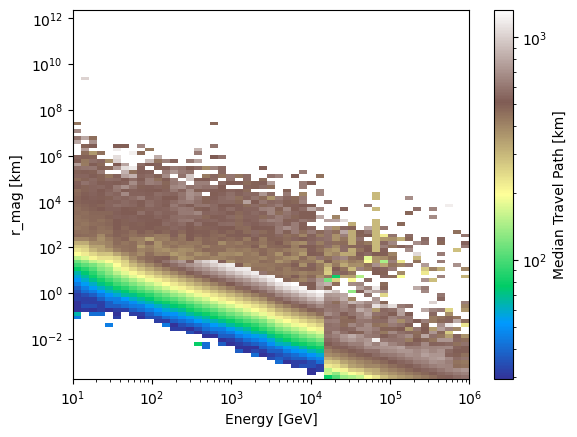

In [3]:
#Magnetic Deflection
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import binned_statistic_2d
mask = photon_count >= 1

r_mag = np.sqrt(x_mag**2 + y_mag**2)
E_bins = np.logspace(1, 6, 50)
R_bins = np.logspace(np.log10(min(r_mag[mask])), np.log10(max(r_mag[mask])) , 100)
# Compute average Slant value in each (Energy, r_mag) bin
stat, xedges, yedges, binnumber = binned_statistic_2d(
    Energy_GeV[mask], r_mag[mask]/1000, Slant[mask], statistic='median', bins=[E_bins, R_bins]
)

# stat has shape (len(E_bins)-1, len(R_bins)-1); need transpose for pcolormesh
plt.figure()
mesh = plt.pcolormesh(xedges, yedges, stat.T, shading='auto', cmap='terrain', norm=LogNorm())
plt.xscale('log')
plt.yscale('log')
cbar = plt.colorbar(mesh)
cbar.set_label('Median Travel Path [km]')
plt.xlabel('Energy [GeV]')
plt.ylabel('r_mag [km]')
plt.show()

In [1]:
import numpy as np
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d

# Physical constants (SI)
C = 299792458.0                 # m/s
E_CHARGE = 1.602176634e-19      # C
MEV_TO_J = 1.602176634e-13      # J/MeV


def propagate_particle(B, x0, v0, a, b, t, charge, mass_MeV,
                       n_steps=20000, E_stop_MeV=None):
    """
    Propagate a charged particle with energy loss dE/ds = -a - b*E
    in a uniform magnetic field.

    Parameters
    ----------
    B        : (Bx, By, Bz) in Tesla
    x0       : (x, y, z) initial position in meters
    v0       : (vx, vy, vz) initial velocity in m/s (sets direction and initial energy)
    a        : constant loss term, MeV/m
    b        : proportional loss term, 1/m
    t        : propagation time, s
    charge   : charge in units of e (e.g. -1 for electron, +1 for proton)
    mass_MeV : rest mass energy mc^2 in MeV
    n_steps  : integration grid resolution
    E_stop_MeV : kinetic-energy-free stopping threshold (default: total E = mc^2)

    Returns
    -------
    x_final (m), v_final (m/s), E_final (MeV), s_final (m), stopped (bool)
    """
    B = np.asarray(B, float)
    x0 = np.asarray(x0, float)
    v0 = np.asarray(v0, float)
    q = charge * E_CHARGE

    # --- initial state ---
    speed0 = np.linalg.norm(v0)
    if speed0 >= C:
        raise ValueError("Initial speed must be < c")
    u0 = v0 / speed0
    gamma0 = 1.0 / np.sqrt(1.0 - (speed0 / C) ** 2)
    E0 = gamma0 * mass_MeV                      # total energy, MeV
    E_stop = mass_MeV if E_stop_MeV is None else E_stop_MeV

    # --- energy vs path length (analytic) ---
    def E_of_s(s):
        if b > 0:
            return (E0 + a / b) * np.exp(-b * s) - a / b
        return E0 - a * s

    # maximum path length before the particle stops
    if b > 0:
        s_max = np.log((E0 + a / b) / (E_stop + a / b)) / b
    elif a > 0:
        s_max = (E0 - E_stop) / a
    else:
        s_max = np.inf                          # no loss: bounded by time only

    # choose a grid long enough to cover time t
    if np.isfinite(s_max):
        s_grid_max = s_max
    else:
        s_grid_max = C * t                      # upper bound on path length
    s = np.linspace(0.0, s_grid_max, n_steps)
    # avoid the singular endpoint where p -> 0
    s[-1] = s[-1] * (1 - 1e-12) if np.isfinite(s_max) else s[-1]

    E = E_of_s(s)                               # MeV
    E = np.maximum(E, E_stop * (1 + 1e-12))
    p_c = np.sqrt(E**2 - mass_MeV**2)           # pc in MeV
    p_SI = p_c * MEV_TO_J / C                   # kg m/s
    beta = p_c / E                              # v/c
    v_s = beta * C

    # --- time as a function of s, invert to find s(t) ---
    t_of_s = cumulative_trapezoid(1.0 / v_s, s, initial=0.0)
    stopped = False
    if t >= t_of_s[-1] and np.isfinite(s_max):
        s_final = s[-1]
        stopped = True
    else:
        s_final = float(interp1d(t_of_s, s)(min(t, t_of_s[-1])))

    # --- rotation angle about B-hat as a function of s ---
    Bmag = np.linalg.norm(B)
    phi = cumulative_trapezoid(abs(q) * Bmag / p_SI, s, initial=0.0)
    sign = -np.sign(q) if q != 0 else 0.0       # rotation sense (see note below)

    if Bmag > 0:
        bhat = B / Bmag
        u_par = np.dot(u0, bhat) * bhat
        u_perp0 = u0 - u_par
        w = np.cross(bhat, u_perp0)             # perpendicular basis vector
        # direction u(s) = u_par + u_perp0 cos(phi) + sign*w sin(phi)
        # Note: dU/ds = (q/p) u x B  ->  rotation about B-hat with sense -sign(q)
        # (check below)
        ang = -np.sign(q) * phi
        u_s = (u_par[None, :]
               + u_perp0[None, :] * np.cos(ang)[:, None]
               + w[None, :] * np.sin(ang)[:, None])
    else:
        u_s = np.tile(u0, (n_steps, 1))

    # --- integrate direction to get position ---
    pos = x0[None, :] + cumulative_trapezoid(u_s, s, axis=0, initial=0.0)

    # --- evaluate everything at s_final ---
    x_final = np.array([np.interp(s_final, s, pos[:, i]) for i in range(3)])
    u_final = np.array([np.interp(s_final, s, u_s[:, i]) for i in range(3)])
    u_final /= np.linalg.norm(u_final)
    E_final = float(np.interp(s_final, s, E))
    beta_final = np.sqrt(max(E_final**2 - mass_MeV**2, 0.0)) / E_final
    v_final = u_final * beta_final * C

    return x_final, v_final, E_final, s_final, stopped


# 50 MeV kinetic electron in 0.43 G field perpendicular to motion, no loss
m_e = 0.511
E_tot = 50.0 + m_e
gamma = E_tot / m_e
beta = np.sqrt(1 - 1 / gamma**2)
v0 = np.array([beta * C, 0.0, 0.0])
B = (0.0, 0.43e-4, 0.0)                     # 0.43 G = 4.3e-5 T

xf, vf, Ef, sf, stopped = propagate_particle(
    B=B, x0=(0, 0, 0), v0=v0, a=0.0, b=0.0,
    t=1e-3, charge=-1, mass_MeV=m_e)

# analytic Larmor radius check
p_SI = np.sqrt(E_tot**2 - m_e**2) * MEV_TO_J / C
rL = p_SI / (E_CHARGE * 0.43e-4)
print("Larmor radius (analytic): %.1f m" % rL)
print("Path length: %.1f m, final E: %.3f MeV" % (sf, Ef))
print("Final position:", xf)
print("Final velocity / c:", vf / C)
# In the no-loss case, |x - center| should equal rL (circle check)

Larmor radius (analytic): 3918.1 m
Path length: 299777.1 m, final E: 50.511 MeV
Final position: [ 3514.25309634     0.         -2185.6249072 ]
Final velocity / c: [ 0.44214782  0.         -0.89688514]


In [2]:
#Trigger Efficiency vs Photon Count, Energy, and Incidence
import plotly.io as pio
pio.renderers.default = "notebook"
# ---------------------------------------------------------
# Grid of 2D trigger-efficiency heatmaps:
#   one panel per incidence bin
#   x = photon count (log), y = energy (log)
#   color = efficiency (symlog, shared across all panels)
#   binning: equal-quantile (default) or equal-log
# ---------------------------------------------------------
import math
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ============ USER CONTROLS ============
N_PC_BINS  = 30          # bins in photon count  (x of each panel)
N_E_BINS   = 30          # bins in energy        (y of each panel)
N_INC_BINS = 6          # bins in incidence     (number of panels)

BIN_MODE   = "log"  # "quantile" (equal-count) or "log" (equal-decade)
INC_MODE   = "log"  # incidence panels: "quantile" or "linear"

MAX_COLS   = 3           # panels per row; rows = ceil(N_INC_BINS / MAX_COLS)

PC_RANGE  = (1e1, 1e7)   # photon count range
E_RANGE   = (1e2, 1e6)   # energy range in GeV
INC_RANGE = (0.0, 6.0)   # incidence range in deg

PE_THRESHOLD = 20.0      # trigger threshold
MIN_EVENTS   = 1         # blank out bins with fewer events than this
LINTHRESH    = 1e-5      # symlog: linear below this, log above

PANEL_W = 300            # px per panel
PANEL_H = 280
# =======================================

# ---------------------------------------------------------
# 1. Select finite events inside all three ranges
# ---------------------------------------------------------
pc_all  = np.asarray(photon_count, dtype=float)
E_all   = np.asarray(Energy_GeV,   dtype=float)
inc_all = np.asarray(Incidence,    dtype=float)
pe_all  = np.asarray(Max_PE,       dtype=float)
r_all   = np.asarray(R,       dtype=float)
mask = (
    np.isfinite(pc_all) & np.isfinite(E_all)
    & np.isfinite(inc_all) & np.isfinite(pe_all)
    & (pc_all  >= PC_RANGE[0])  & (pc_all  <= PC_RANGE[1])
    & (E_all   >= E_RANGE[0])   & (E_all   <= E_RANGE[1])
    & (inc_all >= INC_RANGE[0]) & (inc_all <= INC_RANGE[1])
    & (r_all == 0)
)
try:
    mask &= (R == 0)          # same reflection cut used in the fits
except NameError:
    print("NOTE: 'R' not defined; no reflection cut applied.")

pc_d, E_d, inc_d, pe_d = pc_all[mask], E_all[mask], inc_all[mask], pe_all[mask]
print(f"Events in range: {len(pc_d)} of {len(pc_all)}")
if len(pc_d) == 0:
    raise SystemExit("No events survive the range and reflection cuts.")

# ---------------------------------------------------------
# 2. Bin edges
#    Quantiles are built from the *plotted* sample, so every
#    bin carries a comparable number of events.
# ---------------------------------------------------------
def quantile_bins(v, nbins, lo, hi):
    """Equal-count edges over [lo, hi], de-duplicated and clamped."""
    v = v[(v >= lo) & (v <= hi)]
    e = np.percentile(v, np.linspace(0.0, 100.0, nbins + 1))
    e[0], e[-1] = lo, hi          # pin outer edges to the stated range
    return np.unique(e)           # collapse ties

def log_bins(nbins, lo, hi):
    return np.logspace(np.log10(lo), np.log10(hi), nbins + 1)

if BIN_MODE == "quantile":
    pc_bins = quantile_bins(pc_d, N_PC_BINS, *PC_RANGE)
    E_bins  = quantile_bins(E_d,  N_E_BINS,  *E_RANGE)
else:
    pc_bins = log_bins(N_PC_BINS, *PC_RANGE)
    E_bins  = log_bins(N_E_BINS,  *E_RANGE)

if INC_MODE == "quantile":
    inc_bins = quantile_bins(inc_d, N_INC_BINS, *INC_RANGE)
else:
    inc_bins = np.linspace(INC_RANGE[0], INC_RANGE[1], N_INC_BINS + 1)

# Edge counts may shrink if ties collapsed percentiles
N_PC_EFF  = len(pc_bins)  - 1
N_E_EFF   = len(E_bins)   - 1
N_INC_EFF = len(inc_bins) - 1

for name, want, got in (("photon count", N_PC_BINS,  N_PC_EFF),
                        ("energy",       N_E_BINS,   N_E_EFF),
                        ("incidence",    N_INC_BINS, N_INC_EFF)):
    if got != want:
        print(f"NOTE: {name} quantiles collapsed {want} -> {got} bins (ties).")

# ---------------------------------------------------------
# 3. 3D bin counts: total and triggered
# ---------------------------------------------------------
sample = np.column_stack([pc_d, E_d, inc_d])
edges  = [pc_bins, E_bins, inc_bins]

n_tot,  _ = np.histogramdd(sample, bins=edges)
n_trig, _ = np.histogramdd(sample[pe_d >= PE_THRESHOLD], bins=edges)

with np.errstate(divide="ignore", invalid="ignore"):
    eff     = np.where(n_tot > 0, n_trig / n_tot, np.nan)
    eff_err = np.where(n_tot > 0, np.sqrt(eff * (1.0 - eff) / n_tot), np.nan)

# Blank out under-populated bins so they render as gaps
sparse   = n_tot < MIN_EVENTS
eff_plot = np.where(sparse, np.nan, eff)

print(f"Populated bins: {int(np.sum(n_tot > 0))} of {eff.size} | "
      f"kept (n >= {MIN_EVENTS}): {int(np.sum(~sparse & (n_tot > 0)))}")

# Flatness check on the 1D marginals
if BIN_MODE == "quantile":
    pc_marg = np.histogram(pc_d, pc_bins)[0]
    E_marg  = np.histogram(E_d,  E_bins)[0]
    print(f"Per-bin counts  photon count: {pc_marg.min()}-{pc_marg.max()} | "
          f"energy: {E_marg.min()}-{E_marg.max()}")

# ---------------------------------------------------------
# 4. Hand-built symlog transform for the shared colorscale.
#    Plotly colorbars have no symlog mode, so values are
#    transformed and the colorbar ticks relabelled.
# ---------------------------------------------------------
def symlog_fwd(v, linthresh=LINTHRESH):
    v = np.asarray(v, dtype=float)
    out = np.empty_like(v)
    small = np.abs(v) <= linthresh
    out[small] = v[small] / linthresh
    big = ~small
    out[big] = np.sign(v[big]) * (1.0 + np.log10(np.abs(v[big]) / linthresh))
    return out if out.ndim else out.item()

eff_t  = symlog_fwd(eff_plot)         # NaNs propagate, stay as gaps
cmin_t = float(symlog_fwd(0.0))
cmax_t = float(symlog_fwd(1.0))

decades    = np.arange(np.log10(LINTHRESH), 0.0 + 1e-9)
ctick_real = np.unique(np.concatenate(([0.0], 10.0 ** decades, [1.0])))
ctick_pos  = [float(symlog_fwd(v)) for v in ctick_real]
ctick_text = ["0" if v == 0 else f"{v:g}" for v in ctick_real]

# ---------------------------------------------------------
# 5. Axis setup. Heatmaps get bin EDGES (not centers) so that
#    unequal quantile cells render at their true widths.
# ---------------------------------------------------------
log_pc_e = np.log10(pc_bins)
log_E_e  = np.log10(E_bins)

def log_ticks(bins):
    lo, hi = np.floor(np.log10(bins[0])), np.ceil(np.log10(bins[-1]))
    d = np.arange(lo, hi + 1)
    return d, [f"10<sup>{int(v)}</sup>" for v in d]

pc_tv, pc_tt = log_ticks(pc_bins)
E_tv,  E_tt  = log_ticks(E_bins)

# ---------------------------------------------------------
# 6. Build the subplot grid
# ---------------------------------------------------------
n_cols = min(MAX_COLS, N_INC_EFF)
n_rows = math.ceil(N_INC_EFF / n_cols)

titles = [
    f"{inc_bins[k]:.2f}&ndash;{inc_bins[k+1]:.2f}&deg; "
    f"(N={int(n_tot[:, :, k].sum())})"
    for k in range(N_INC_EFF)
]

fig = make_subplots(
    rows=n_rows, cols=n_cols,
    subplot_titles=titles,
    shared_xaxes=True, shared_yaxes=True,
    horizontal_spacing=0.04,
    vertical_spacing=0.09,
)

for k in range(N_INC_EFF):
    r = k // n_cols + 1
    c = k % n_cols + 1

    # transpose: heatmap z is indexed [row, col] = [y, x] = [E, pc]
    z_panel   = eff_t[:, :, k].T
    eff_panel = eff[:, :, k].T
    err_panel = eff_err[:, :, k].T
    tot_panel = n_tot[:, :, k].T
    trg_panel = n_trig[:, :, k].T

    custom = np.stack([eff_panel, err_panel, tot_panel, trg_panel], axis=-1)

    fig.add_trace(
        go.Heatmap(
            x=log_pc_e, y=log_E_e, z=z_panel,
            customdata=custom,
            colorscale="Viridis",
            zmin=cmin_t, zmax=cmax_t,
            showscale=(k == 0),          # one shared colorbar
            colorbar=dict(
                title="Trigger<br>efficiency",
                tickvals=ctick_pos,
                ticktext=ctick_text,
                len=0.85, y=0.5,
            ),
            hovertemplate=(
                f"incidence {inc_bins[k]:.2f}&ndash;{inc_bins[k+1]:.2f}&deg;<br>"
                "log10(pc) = %{x:.2f}<br>"
                "log10(E/GeV) = %{y:.2f}<br>"
                "efficiency = %{customdata[0]:.4g} "
                "&plusmn; %{customdata[1]:.2g}<br>"
                "N total = %{customdata[2]:.0f}<br>"
                "N triggered = %{customdata[3]:.0f}"
                "<extra></extra>"
            ),
        ),
        row=r, col=c,
    )

# Decade ticks on every panel axis
for r in range(1, n_rows + 1):
    for c in range(1, n_cols + 1):
        fig.update_xaxes(tickvals=pc_tv, ticktext=pc_tt,
                         range=[log_pc_e[0], log_pc_e[-1]], row=r, col=c)
        fig.update_yaxes(tickvals=E_tv, ticktext=E_tt,
                         range=[log_E_e[0], log_E_e[-1]], row=r, col=c)

# Axis labels only on the outer edge
for c in range(1, n_cols + 1):
    fig.update_xaxes(title_text="Photon count", row=n_rows, col=c)
for r in range(1, n_rows + 1):
    fig.update_yaxes(title_text="Energy (GeV)", row=r, col=1)

fig.update_annotations(font_size=11)

mode_txt = ("equal-count quantile bins" if BIN_MODE == "quantile"
            else "equal-decade log bins")
fig.update_layout(
    title=(f"Trigger efficiency (Max_PE &ge; {PE_THRESHOLD:.0f}) "
           f"vs. photon count and energy, by incidence angle<br>"
           f"<sub>{N_PC_EFF} pc &times; {N_E_EFF} E bins per panel, {mode_txt} | "
           f"blank = fewer than {MIN_EVENTS} events | "
           f"color symlog, linthresh = {LINTHRESH:g}</sub>"),
    width=PANEL_W * n_cols + 180,
    height=PANEL_H * n_rows + 130,
    margin=dict(l=70, r=120, t=110, b=60),
)

fig.show()
# fig.write_html("trigger_efficiency_panels.html")

Events in range: 1972013 of 4279493
Populated bins: 3589 of 5400 | kept (n >= 1): 3589


In [16]:
#Trigger Efficiency vs Photon Count, Energy, and Incidence
import plotly.io as pio
pio.renderers.default = "notebook"
# ---------------------------------------------------------
# Grid of 1D trigger-efficiency curves:
#   one panel per incidence bin
#   x = energy (log), y = trigger efficiency (log)
#   one line per photon-count bin, colored by photon count
#   binomial (Wilson) error bars on each point
# ---------------------------------------------------------
import math
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex, Normalize

# ============ USER CONTROLS ============
N_E_BINS   = 30
N_PC_BINS  = 6
N_INC_BINS = 6

E_MODE     = "log"
BIN_MODE   = "log"
INC_MODE   = "linear"

MAX_COLS   = 3

PC_RANGE  = (1e3, 1e7)
E_RANGE   = (1e3, 1e6)
INC_RANGE = (0.0, 5.0)

PE_THRESHOLD = 20.0
MIN_EVENTS   = 10
Y_LOG        = True
Y_FLOOR      = 1e-4

ERR_MODE     = "wilson"

PANEL_W = 380
PANEL_H = 320
# =======================================

pc_all  = np.asarray(photon_count, dtype=float)
E_all   = np.asarray(Energy_GeV,   dtype=float)
inc_all = np.asarray(Incidence,    dtype=float)
pe_all  = np.asarray(Max_PE,       dtype=float)
r_all   = np.asarray(R,            dtype=float)

mask = (
    np.isfinite(pc_all) & np.isfinite(E_all)
    & np.isfinite(inc_all) & np.isfinite(pe_all)
    & (pc_all  >= PC_RANGE[0])  & (pc_all  <= PC_RANGE[1])
    & (E_all   >= E_RANGE[0])   & (E_all   <= E_RANGE[1])
    & (inc_all >= INC_RANGE[0]) & (inc_all <= INC_RANGE[1])
    & (r_all == 0)
)

pc_d, E_d, inc_d, pe_d = pc_all[mask], E_all[mask], inc_all[mask], pe_all[mask]
print(f"Events in range: {len(pc_d)} of {len(pc_all)}")
if len(pc_d) == 0:
    raise SystemExit("No events survive the range and reflection cuts.")

def quantile_bins(v, nbins, lo, hi):
    v = v[(v >= lo) & (v <= hi)]
    e = np.percentile(v, np.linspace(0.0, 100.0, nbins + 1))
    e[0], e[-1] = lo, hi
    return np.unique(e)

def log_bins(nbins, lo, hi):
    return np.logspace(np.log10(lo), np.log10(hi), nbins + 1)

E_bins  = (quantile_bins(E_d, N_E_BINS, *E_RANGE) if E_MODE == "quantile"
           else log_bins(N_E_BINS, *E_RANGE))
pc_bins = (quantile_bins(pc_d, N_PC_BINS, *PC_RANGE) if BIN_MODE == "quantile"
           else log_bins(N_PC_BINS, *PC_RANGE))
inc_bins = (quantile_bins(inc_d, N_INC_BINS, *INC_RANGE) if INC_MODE == "quantile"
            else np.linspace(INC_RANGE[0], INC_RANGE[1], N_INC_BINS + 1))

N_E_EFF   = len(E_bins)   - 1
N_PC_EFF  = len(pc_bins)  - 1
N_INC_EFF = len(inc_bins) - 1

for name, want, got in (("energy",       N_E_BINS,   N_E_EFF),
                        ("photon count", N_PC_BINS,  N_PC_EFF),
                        ("incidence",    N_INC_BINS, N_INC_EFF)):
    if got != want:
        print(f"NOTE: {name} bins collapsed {want} -> {got} (ties).")

sample = np.column_stack([E_d, pc_d, inc_d])
edges  = [E_bins, pc_bins, inc_bins]

n_tot,  _ = np.histogramdd(sample, bins=edges)
n_trig, _ = np.histogramdd(sample[pe_d >= PE_THRESHOLD], bins=edges)

with np.errstate(divide="ignore", invalid="ignore"):
    eff = np.where(n_tot > 0, n_trig / n_tot, np.nan)

def wilson_interval(k, n, z=1.0):
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    out_lo = np.full(k.shape, np.nan)
    out_hi = np.full(k.shape, np.nan)
    good = n > 0
    if not np.any(good):
        return out_lo, out_hi
    kg, ng = k[good], n[good]
    p = kg / ng
    denom = 1.0 + z**2 / ng
    center = (p + z**2 / (2.0 * ng)) / denom
    half = (z / denom) * np.sqrt(p * (1.0 - p) / ng + z**2 / (4.0 * ng**2))
    out_lo[good] = np.clip(center - half, 0.0, 1.0)
    out_hi[good] = np.clip(center + half, 0.0, 1.0)
    return out_lo, out_hi

if ERR_MODE == "wilson":
    lo_ci, hi_ci = wilson_interval(n_trig, n_tot, z=1.0)
    err_minus = eff - lo_ci
    err_plus  = hi_ci - eff
else:
    with np.errstate(divide="ignore", invalid="ignore"):
        s = np.where(n_tot > 0, np.sqrt(eff * (1.0 - eff) / n_tot), np.nan)
    err_minus = np.minimum(s, eff)
    err_plus  = np.minimum(s, 1.0 - eff)

E_cen  = np.sqrt(E_bins[:-1]  * E_bins[1:])
pc_cen = np.sqrt(pc_bins[:-1] * pc_bins[1:])

cmap = plt.get_cmap("plasma")
norm = Normalize(vmin=np.log10(pc_bins[0]), vmax=np.log10(pc_bins[-1]))
PC_colors = [to_hex(cmap(norm(np.log10(p)))) for p in pc_cen]

def log_ticks(bins):
    lo, hi = np.floor(np.log10(bins[0])), np.ceil(np.log10(bins[-1]))
    d = np.arange(lo, hi + 1)
    return (10.0 ** d), [f"10<sup>{int(v)}</sup>" for v in d]

E_tv, E_tt = log_ticks(E_bins)

n_cols = min(MAX_COLS, N_INC_EFF)
n_rows = math.ceil(N_INC_EFF / n_cols)

titles = [
    f"{inc_bins[k]:.2f}&ndash;{inc_bins[k+1]:.2f}&deg; "
    f"(N={int(n_tot[:, :, k].sum())})"
    for k in range(N_INC_EFF)
]

fig = make_subplots(
    rows=n_rows, cols=n_cols,
    subplot_titles=titles,
    shared_xaxes=False, shared_yaxes=False,   # <- so per-panel tick labels are drawn
    horizontal_spacing=0.06,
    vertical_spacing=0.14,
)

for k in range(N_INC_EFF):
    r = k // n_cols + 1
    c = k % n_cols + 1

    for j in range(N_PC_EFF):
        n_col_ = n_tot[:, j, k]
        k_col_ = n_trig[:, j, k]
        e_col_ = eff[:, j, k]
        em     = err_minus[:, j, k]
        ep     = err_plus[:, j, k]

        keep = (n_col_ >= MIN_EVENTS) & np.isfinite(e_col_) & (e_col_ > 0)
        if not np.any(keep):
            continue

        label = f"{pc_bins[j]:.3g}&ndash;{pc_bins[j+1]:.3g}"

        fig.add_trace(
            go.Scatter(
                x=E_cen[keep],
                y=e_col_[keep],
                error_y=dict(
                    type="data",
                    symmetric=False,
                    array=ep[keep],
                    arrayminus=np.minimum(em[keep], e_col_[keep] * 0.999),  # keep lower bound > 0 on log axis
                    thickness=1.0,
                    width=2,
                ),
                mode="lines+markers",
                line=dict(color=PC_colors[j], width=1.8),
                marker=dict(size=5, color=PC_colors[j]),
                name=label,
                legendgroup=label,
                showlegend=(k == 0),
                customdata=np.stack(
                    [n_col_[keep], k_col_[keep], em[keep], ep[keep]], axis=-1
                ),
                hovertemplate=(
                    f"photon count = {label}<br>"
                    f"incidence {inc_bins[k]:.2f}&ndash;{inc_bins[k+1]:.2f}&deg;<br>"
                    "E = %{x:.3g} GeV<br>"
                    "efficiency = %{y:.4g} "
                    "(+%{customdata[3]:.2g} / &minus;%{customdata[2]:.2g})<br>"
                    "N total = %{customdata[0]:.0f}<br>"
                    "N triggered = %{customdata[1]:.0f}"
                    "<extra></extra>"
                ),
            ),
            row=r, col=c,
        )

# ---------------------------------------------------------
# Axes: force tick labels on EVERY panel
# ---------------------------------------------------------
y_axis_kw = dict(
    range=[np.log10(Y_FLOOR), np.log10(2)] if Y_LOG else [-0.03,1.03],
    type="log" if Y_LOG else "linear",
)

for r in range(1, n_rows + 1):
    for c in range(1, n_cols + 1):
        fig.update_xaxes(
            type="log", tickvals=E_tv, ticktext=E_tt,
            range=[np.log10(E_bins[0]), np.log10(E_bins[-1])],
            showgrid=True, gridcolor="rgba(0,0,0,0.08)",
            showticklabels=True,     # explicit: keep labels on every panel
            title_text="Energy (GeV)",
            row=r, col=c,
        )
        fig.update_yaxes(
            showgrid=True, gridcolor="rgba(0,0,0,0.08)",
            showticklabels=True,
            title_text="Trigger efficiency" if c == 1 else None,
            **y_axis_kw, row=r, col=c,
        )

fig.update_annotations(font_size=11)

cb_dec = np.arange(np.ceil(np.log10(pc_bins[0])),
                   np.floor(np.log10(pc_bins[-1])) + 1e-9)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None], mode="markers",
        marker=dict(
            colorscale="Plasma",
            cmin=np.log10(pc_bins[0]), cmax=np.log10(pc_bins[-1]),
            color=[np.log10(pc_bins[0])],
            showscale=True,
            colorbar=dict(
                title="Photon<br>count",
                tickvals=cb_dec,
                ticktext=[f"10<sup>{int(v)}</sup>" for v in cb_dec],
                len=0.85, y=0.5, x=1.02,
            ),
        ),
        hoverinfo="skip", showlegend=False,
    ),
    row=1, col=1,
)

mode_txt = ("equal-count quantile" if E_MODE == "quantile"
            else "equal-decade log")
err_txt  = ("Wilson score, 1&sigma;" if ERR_MODE == "wilson"
            else "normal approximation")
fig.update_layout(
    title=(f"Trigger efficiency (Max_PE &ge; {PE_THRESHOLD:.0f}) "
           f"vs. energy, by photon count and incidence angle<br>"
           f"<sub>{N_E_EFF} energy bins ({mode_txt}) | "
           f"points with N < {MIN_EVENTS} dropped | "
           f"errors: {err_txt}</sub>"),
    width=PANEL_W * n_cols + 260,
    height=PANEL_H * n_rows + 150,
    margin=dict(l=80, r=200, t=120, b=60),
    legend=dict(
        title="Photon count",
        x=1.14, y=0.5, yanchor="middle",
        bgcolor="rgba(255,255,255,0.85)",
        bordercolor="rgba(0,0,0,0.2)", borderwidth=1,
        font_size=10,
    ),
    template="plotly_white",
    hovermode="closest",
)

fig.show()
# fig.write_html("trigger_efficiency_vs_energy.html")

Events in range: 1380721 of 4279493


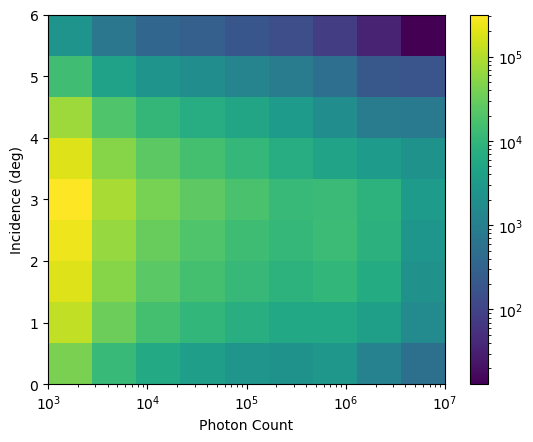

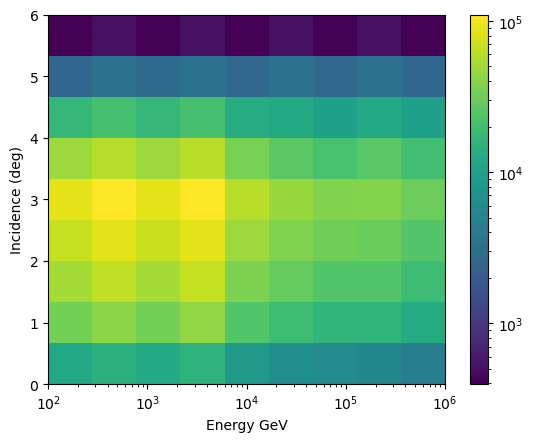

In [199]:
#Number of sample data
from matplotlib.colors import LogNorm

pc_bins = np.logspace(3,7,10)
inc_bins = np.linspace(0,6,10)
plt.hist2d(photon_count, Incidence, bins=[pc_bins, inc_bins], norm=LogNorm())
plt.xscale("log")
plt.xlabel("Photon Count")
plt.ylabel("Incidence (deg)")
plt.colorbar()
plt.show()

E_bins = np.logspace(2,6,10)
inc_bins = np.linspace(0,6,10)
plt.hist2d(Energy_GeV, Incidence, bins=[E_bins, inc_bins], norm=LogNorm())
plt.xlabel("Energy GeV")
plt.ylabel("Incidence (deg)")
plt.xscale("log")
plt.colorbar()
plt.show()

Test Section Below

In [28]:
# Fitting Landau-Gauss Model & Lognormal -- binned Poisson likelihood version
#
# Cleanup notes vs. the original:
#   - body_survival() no longer reimplements the Landau/Gauss/Langau regime
#     switch. It now calls the SAME landau_gauss()/_shape_unnorm() function
#     used to build expected bin counts, so the survival probability and the
#     fitted shape can never silently disagree about which regime is active.
#   - trigger_efficiency() / trigger_efficiency_ln() are now one-line wrappers
#     around a shared combine_efficiency(p_surv, A, A_sat) formula.
#   - trigger_efficiency_error() / trigger_efficiency_error_ln() are replaced
#     by one generic finite-difference error propagator,
#     _propagate_survival_error(), parameterized by the survival function and
#     its covariance (works for the 3-param Landau-Gauss and 2-param
#     lognormal cases alike).
#   - The Minuit "try a strategy, retry with a different strategy/start point
#     if it didn't converge" pattern is factored into _run_minuit(), used by
#     both body-shape fits instead of being written out twice.
#   - Both cost functions now call the single _poisson_nll() helper instead
#     of re-deriving the same sum twice.
#   - fit_bin()'s Landau-Gauss fit logic is pulled out into fit_landau_gauss(),
#     mirroring fit_lognormal(), so the two body models are handled
#     symmetrically and fit_bin() is just orchestration.
#   - The "near a parameter bound" check is a single _is_near_bound() helper
#     instead of being redefined inline in two places.
#   - Default/failure dictionaries for each model (_LG_EMPTY / _LN_EMPTY) are
#     defined once and reused by both the fit functions and fit_bin(), instead
#     of the same key list being typed out twice.
#   - Section 7's array allocation and result-scatter loop are now driven by
#     small key lists instead of ~30 near-identical lines each.

import os
from scipy.stats import norm
import numpy as np
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(v, "1")
from concurrent.futures import ProcessPoolExecutor, as_completed
import pylandau
import logging
from scipy.integrate import cumulative_trapezoid
from iminuit import Minuit
from iminuit.util import IMinuitWarning
import warnings
from scipy.special import ndtr   # standard normal CDF, used by the lognormal model

# Suppress pylandau's WARNING-level log messages (e.g. sigma > 100*eta oscillation notice)
logging.getLogger("pylandau").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=IMinuitWarning)

# ---------------------------------------------------------
# 0. Configuration
# ---------------------------------------------------------
# NOTE: Max_PE, photon_count, Incidence, R, Energy_GeV are assumed to already
# exist in scope (e.g. injected by the calling notebook/session), exactly as
# in the original script.
PE_THRESHOLD = 20.0  # trigger threshold, adjust to your actual cut
N_P = 10          # number of photon_count bins
N_I = 10          # number of incidence bins
EQUAL_COUNT_BINS = False
PC_RANGE  = (1e3, float(np.nanmax(photon_count)))
INC_RANGE = (0.0, 5)
MIN_EVENTS_PER_BIN = 50
N_WORKERS = os.cpu_count()
XMIN_CUT = 1
XMAX_CUT = 149
N_BINS_PE = 100   # bins used internally for each 1D pe histogram fit
PDF_CUT = 1e-4

SIGMA_MIN = 0
KAPPA_LO = 1e-3   # eta/sigma below this -> Landau width negligible, pure Gaussian-ish regime
KAPPA_HI = 2e3    # eta/sigma above this -> Gaussian smearing negligible, pure Landau
EPS_MU    = 1e-12  # floor on expected counts, keeps log() finite

LAMBDA_TRIGGER = 0.0  # tune this; 0 = off, 1 = "one more full observation," higher = more weight
# Fixed, shared histogram binning for EVERY 2D bin.
# Log spacing resolves the peak; the same partition is reused everywhere so
# fits are directly comparable and empty tail bins carry real information.
BIN_EDGES_PE = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), N_BINS_PE + 1)
BIN_WIDTHS   = np.diff(BIN_EDGES_PE)
BIN_CENTERS  = 0.5 * (BIN_EDGES_PE[:-1] + BIN_EDGES_PE[1:])
BIN_LO       = BIN_EDGES_PE[:-1]
BIN_HI       = BIN_EDGES_PE[1:]

X_LO, X_HI = XMIN_CUT, XMAX_CUT
N_GRID     = 100
X_GRID     = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), N_GRID)  # grid for cdf calc

# ---------------------------------------------------------
# 1. Global selection
# ---------------------------------------------------------
mask2d = (
    np.isfinite(Max_PE) & np.isfinite(photon_count) & np.isfinite(Incidence)
    & (photon_count >= PC_RANGE[0]) & (photon_count <= PC_RANGE[1])
    & (Incidence >= INC_RANGE[0]) & (Incidence <= INC_RANGE[1])
    & (R == 0) & (Energy_GeV <= 5e5)
)

pe_all  = np.asarray(Max_PE[mask2d],       dtype=float)
pc_all  = np.asarray(photon_count[mask2d], dtype=float)
inc_all = np.asarray(Incidence[mask2d],    dtype=float)

# ---------------------------------------------------------
# 2. Build 2D bin edges
# ---------------------------------------------------------
if EQUAL_COUNT_BINS:
    quantiles = np.linspace(0, 1, N_P + 1)
    pc_edges = np.unique(np.quantile(pc_all, quantiles))

    quantiles = np.linspace(0, 1, N_I + 1)
    inc_edges = np.unique(np.quantile(inc_all, quantiles))
    if len(pc_edges) - 1 != N_P:
        print(f"WARNING: equal-count binning produced {len(pc_edges)-1} unique bins instead of {N_P}")
else:
    inc_edges = np.linspace(INC_RANGE[0], INC_RANGE[1], N_I + 1)
    pc_edges = np.logspace(np.log10(PC_RANGE[0]), np.log10(PC_RANGE[1]), N_P + 1)

print("Incidence bin edges:", inc_edges)
print("Photon count bin edges:", pc_edges)

# ---------------------------------------------------------
# 3. Landau-Gauss body model
# ---------------------------------------------------------
def landau_gauss(x, mpv, eta, sigma, Amplitude):
    """
    Landau-Gauss convolution with explicit Landau/Gaussian fallbacks based on
    kappa = eta / sigma, to avoid numerical instability in the regimes where
    pylandau.langau's underlying convolution is poorly conditioned.

    This is the single place where the Landau/Gauss/Langau regime is decided.
    body_survival() below reuses it (via _shape_unnorm) rather than
    re-deciding the regime a second time, so the fitted shape and the
    trigger-efficiency integral are always evaluated from the same model.

    Regimes:
      - sigma < SIGMA_MIN              -> pure Landau (sigma negligible)
      - kappa = eta/sigma > KAPPA_HI   -> pure Landau (Gaussian smearing
                                          negligible; convolution ~identity)
      - kappa = eta/sigma < KAPPA_LO   -> pure Gaussian (Landau core has
                                          collapsed to a delta function)
      - otherwise                      -> full Landau-Gauss convolution
    """
    sigma_val = np.atleast_1d(sigma)[0] if isinstance(sigma, np.ndarray) else sigma
    eta_val = np.atleast_1d(eta)[0] if isinstance(eta, np.ndarray) else eta

    if sigma_val < SIGMA_MIN:
        return Amplitude * pylandau.landau(x, mpv, eta)

    kappa = eta_val / sigma_val

    if kappa >= KAPPA_HI:
        return Amplitude * pylandau.landau(x, mpv, eta)

    if kappa < KAPPA_LO:
        return Amplitude * np.exp(-0.5 * ((x - mpv) / sigma_val) ** 2) / (
            sigma_val * np.sqrt(2 * np.pi)
        )

    return pylandau.langau(x, mpv, eta, sigma, Amplitude)


def _shape_unnorm(x, mpv, eta, sigma):
    """Unnormalized Landau-Gauss shape (Amplitude = 1)."""
    return landau_gauss(np.asarray(x, dtype=float), mpv, eta, sigma, 1.0)


def _expected_counts_lg(mpv, eta, sigma, n_body):
    f = _shape_unnorm(BIN_EDGES_PE, mpv, eta, sigma)
    if not np.all(np.isfinite(f)):
        return None
    f = np.maximum(f, 0.0)  # clip only tiny negative round-off
    integ = 0.5 * (f[:-1] + f[1:]) * BIN_WIDTHS
    tot = integ.sum()
    if not np.isfinite(tot) or tot <= 0.0:
        return None
    return n_body * integ / tot


_surv_cache = {}
def body_survival(threshold, mpv_val, eta_val, sigma_val, max_pe_body=0):
    """
    P(X >= threshold | XMIN_CUT <= X <= XMAX_CUT) under the Landau-Gauss body
    shape. Reuses _shape_unnorm() (== landau_gauss) evaluated on X_GRID, then
    integrates -- the same shape function used for the expected bin counts,
    so this can never disagree with the fit about which regime is active.
    """
    if not all(np.isfinite(v) for v in (threshold, mpv_val, eta_val, sigma_val)):
        return np.nan
    if sigma_val <= 0 or eta_val < 0:
        return np.nan

    lo, hi = XMIN_CUT, XMAX_CUT
    if threshold <= lo:
        return 1.0
    if threshold >= hi:
        return 0.0

    key = tuple(round(float(v), 5) for v in (threshold, mpv_val, eta_val, sigma_val))
    if key in _surv_cache:
        return _surv_cache[key]

    try:
        y = _shape_unnorm(X_GRID, mpv_val, eta_val, sigma_val)
        if not np.all(np.isfinite(y)):
            raise ValueError("Non-finite PDF values")
        #clipping y, only use the pdf up to where the threshold is to prevent over extrapolate
        #if max_pe_body <= threshold:
        #    mask = (X_GRID>threshold)
        #    y[mask] = 0
        cdf = cumulative_trapezoid(y, X_GRID, initial=0.0)
        Fa, Fb, Ft = np.interp([lo, hi, threshold], X_GRID, cdf)
        denom = Fb - Fa
        out = (Fb - Ft) / denom if denom > 0 else np.nan
    except Exception:
        out = np.nan

    out = float(np.clip(out, 0.0, 1.0)) if np.isfinite(out) else np.nan
    _surv_cache[key] = out
    return out

# ---------------------------------------------------------
# 3b. Lognormal body model (truncated to [XMIN_CUT, XMAX_CUT))
#     mu_ln = log(median), s_ln = std of log(x)
# ---------------------------------------------------------
LN_LOG_LO = np.log(BIN_LO)
LN_LOG_HI = np.log(BIN_HI)

def _norm_interval(z_lo, z_hi):
    """P(z_lo < Z < z_hi), accurate in both tails (avoids 1-1 cancellation)."""
    z_lo = np.asarray(z_lo, dtype=float)
    z_hi = np.asarray(z_hi, dtype=float)
    upper = ndtr(-z_lo) - ndtr(-z_hi)   # precise when both z > 0
    lower = ndtr(z_hi) - ndtr(z_lo)     # precise when both z < 0
    return np.where(z_lo > 0, upper, lower)


def _expected_counts_ln(mu_ln, s_ln, n_body):
    """Expected counts per PE bin for a lognormal truncated to the fit window."""
    if not (np.isfinite(mu_ln) and np.isfinite(s_ln)) or s_ln <= 0:
        return None
    p = _norm_interval((LN_LOG_LO - mu_ln) / s_ln, (LN_LOG_HI - mu_ln) / s_ln)
    p = np.maximum(p, 0.0)
    tot = p.sum()
    if not np.isfinite(tot) or tot <= 0:
        return None
    return n_body * p / tot


def body_survival_ln(threshold, mu_ln, s_ln):
    """P(x >= threshold | lognormal truncated to [X_LO, X_HI]) -- closed form."""
    if not (np.isfinite(mu_ln) and np.isfinite(s_ln)) or s_ln <= 0:
        return np.nan
    if threshold <= X_LO:
        return 1.0
    if threshold >= X_HI:
        return 0.0
    z_lo  = (np.log(X_LO) - mu_ln) / s_ln
    z_thr = (np.log(threshold) - mu_ln) / s_ln
    z_hi  = (np.log(X_HI) - mu_ln) / s_ln
    den = float(_norm_interval(z_lo, z_hi))
    if not np.isfinite(den) or den <= 0:
        return np.nan
    num = float(_norm_interval(z_thr, z_hi))
    return float(np.clip(num / den, 0.0, 1.0))


# ---------------------------------------------------------
# 3c. Shared trigger-efficiency formula + error propagation
#     (used by both the Landau-Gauss and lognormal body models)
# ---------------------------------------------------------
def combine_efficiency(p_surv, A, A_sat):
    """eff = A_sat + A * P(x >= threshold | body shape). Model-agnostic."""
    if not np.isfinite(p_surv):
        return np.nan
    return A_sat + A * p_surv


def trigger_efficiency(mpv, eta, sigma, A, A_sat, threshold=PE_THRESHOLD, max_pe_body=0):
    return combine_efficiency(body_survival(threshold, mpv, eta, sigma, max_pe_body), A, A_sat)


def trigger_efficiency_ln(mu_ln, s_ln, A, A_sat, threshold=PE_THRESHOLD):
    return combine_efficiency(body_survival_ln(threshold, mu_ln, s_ln), A, A_sat)


def _propagate_survival_error(survival_fn, params, cov, A, A_err, A_sat, A_sat_err, eps=1e-3):
    """
    Generic error propagation for eff = A_sat + A * survival_fn(*params),
    given a covariance matrix for `params` (n x n, from the shape fit) plus
    independent binomial errors on A and A_sat. Works for the 3-parameter
    Landau-Gauss survival function and the 2-parameter lognormal one alike --
    replaces what used to be two near-duplicate functions.
    """
    if cov is None or not np.all(np.isfinite(cov)):
        return np.nan

    params = np.array(params, dtype=float)
    n = len(params)
    p0 = survival_fn(*params)
    if not np.isfinite(p0):
        return np.nan

    grad = np.zeros(n)
    for k in range(n):
        step = max(abs(params[k]) * eps, 1e-6)
        d = np.zeros(n)
        d[k] = step
        p_plus  = survival_fn(*(params + d))
        p_minus = survival_fn(*(params - d))
        grad[k] = (p_plus - p_minus) / (2.0 * step) if np.isfinite(p_plus) and np.isfinite(p_minus) else 0.0

    var_p = max(float(grad @ cov @ grad), 0.0)
    var_eff = (A_sat_err ** 2 if np.isfinite(A_sat_err) else 0.0)
    var_eff += (p0 ** 2) * (A_err ** 2 if np.isfinite(A_err) else 0.0)
    var_eff += (A ** 2) * var_p

    return float(np.sqrt(var_eff)) if np.isfinite(var_eff) and var_eff >= 0 else np.nan


# ---------------------------------------------------------
# 3d. Population fractions (independent of the shape fit)
# ---------------------------------------------------------
def compute_fractions(pe_vals):
    """
    Compute the three population fractions and their errors.

        A_0   : fraction below XMIN_CUT   (delta at 0)
        A     : fraction in [XMIN_CUT, XMAX_CUT)  (Landau-Gauss body)
        A_sat : fraction at/above XMAX_CUT (delta at saturation)

    Errors are binomial, sqrt(p*(1-p)/n) -- the correct form for a fraction
    of a fixed total.
    """
    n = len(pe_vals)
    if n == 0:
        return dict(A=np.nan, A_err=np.nan,
                    A_0=np.nan, A_0_err=np.nan,
                    A_sat=np.nan, A_sat_err=np.nan,
                    k_0=0, k_mid=0, k_sat=0, n_total=0,
                    frac_valid=False)

    k_0   = int(np.count_nonzero(pe_vals < XMIN_CUT))
    k_sat = int(np.count_nonzero(pe_vals >= XMAX_CUT))
    k_mid = int(np.count_nonzero((pe_vals >= XMIN_CUT) & (pe_vals < XMAX_CUT)))

    def _binom_err(k):
        p = k / n
        return np.sqrt(max(p * (1.0 - p), 0.0) / n)

    return dict(
        A=k_mid / n,        A_err=_binom_err(k_mid),
        A_0=k_0 / n,        A_0_err=_binom_err(k_0),
        A_sat=k_sat / n,    A_sat_err=_binom_err(k_sat),
        k_0=k_0, k_mid=k_mid, k_sat=k_sat, n_total=n,
        frac_valid=True,
    )


# ---------------------------------------------------------
# 3e. Poisson likelihood helpers (shared by both fits)
# ---------------------------------------------------------
def _poisson_nll(mu, counts):
    """Binned Poisson negative log-likelihood, constant terms dropped."""
    mu = np.maximum(mu, EPS_MU)
    return np.sum(mu - counts * np.log(mu))


def _trigger_nll(p, k_trig, n_body):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(k_trig * np.log(p) + (n_body - k_trig) * np.log(1 - p))
    
def _poisson_deviance(mu, counts):
    """
    Saturated-model Poisson deviance: 2*sum(mu - n + n*log(n/mu)).
    Asymptotically chi2-distributed; stored in the 'chi2' slot and divided by
    ndof for 'chi2_red'.
    """
    mu = np.maximum(mu, EPS_MU)
    n  = counts.astype(float)
    term = mu - n
    nz = n > 0
    term[nz] += n[nz] * np.log(n[nz] / mu[nz])
    return 2.0 * np.sum(term)


# ---------------------------------------------------------
# 3f. Minuit fitting helper (shared retry pattern)
# ---------------------------------------------------------
def _is_near_bound(value, limit, rtol=1e-3):
    return abs(value - limit) <= rtol * max(abs(limit), 1.0)


def _run_minuit(cost_func, start, limits, strategies=(0, 1), ncall=None):
    """
    Run Minuit through a sequence of strategies, continuing from wherever the
    previous attempt left off, stopping as soon as a valid minimum is found.
    Shared by the Landau-Gauss and lognormal body fits so the retry logic
    lives in exactly one place.
    """
    m = Minuit(cost_func, **start)
    for name, (lo, hi) in limits.items():
        m.limits[name] = (lo, hi)
    for strategy in strategies:
        m.strategy = strategy
        m.migrad(ncall=ncall) if ncall else m.migrad()
        m.hesse()
        if m.valid:
            break
    return m


# ---------------------------------------------------------
# 3g. Body-shape fits (symmetric structure, one dict each)
# ---------------------------------------------------------
_LG_EMPTY = dict(
    success=False, valid_minuit=False, at_bound=False,
    mpv=np.nan, eta=np.nan, sigma=np.nan,
    mpv_err=np.nan, eta_err=np.nan, sigma_err=np.nan,
    cov=None, nll=np.nan,
    chi2=np.nan, ndof=np.nan, chi2_red=np.nan,
    error_msg=None,
)

_LN_EMPTY = dict(
    success_ln=False, valid_minuit_ln=False, at_bound_ln=False,
    mu_ln=np.nan, s_ln=np.nan, mu_ln_err=np.nan, s_ln_err=np.nan,
    cov_ln=None, nll_ln=np.nan,
    chi2_ln=np.nan, ndof_ln=np.nan, chi2_red_ln=np.nan,
    error_msg_ln=None,
)


def fit_landau_gauss(counts, pe_body, n_body, k_trig):
    """Binned Poisson-likelihood fit of the Landau-Gauss body."""
    out = dict(_LG_EMPTY)

    dens = counts / BIN_WIDTHS
    mpv_guess = float(BIN_CENTERS[np.argmax(dens)])
    q16, q84 = np.percentile(pe_body, [16.0, 84.0])
    spread = max(float(q84 - q16), 1e-3)
    eta_guess = max(spread / 4.0, 1e-3)
    sigma_guess = max(spread / 4.0, 1e-3)
    """
    def cost(mpv, eta, sigma):
        mu = _expected_counts_lg(mpv, eta, sigma, n_body)
        if mu is None:
            return 1e12
        val = _poisson_nll(mu, counts)
        return val if np.isfinite(val) else 1e12"""
    max_pe_body = np.max(pe_body)
    def cost(mpv, eta, sigma):
        mu = _expected_counts_lg(mpv, eta, sigma, n_body)
        if mu is None:
            return 1e12
        p = body_survival(PE_THRESHOLD, mpv, eta, sigma)
        if not np.isfinite(p):
            return 1e12
        val = _poisson_nll(mu, counts) + LAMBDA_TRIGGER * _trigger_nll(p, k_trig, n_body)
        return val if np.isfinite(val) else 1e12
        
    cost.errordef = Minuit.LIKELIHOOD

    m = _run_minuit(
        cost, dict(mpv=mpv_guess, eta=eta_guess, sigma=sigma_guess),
        {"mpv": (1, 1000), "eta": (0, XMAX_CUT), "sigma": (0, XMAX_CUT)},
        strategies=(0, 1), ncall=2000,
    )
    if not m.valid:
        # one retry from a wider, blunter starting point
        m = _run_minuit(
            cost,
            dict(mpv=mpv_guess, eta=max(spread / 8.0, 1e-3), sigma=max(spread / 2.0, 1e-3)),
            {"mpv": (0, 1000), "eta": (0, XMAX_CUT * 2), "sigma": (0, XMAX_CUT * 2)},
            strategies=(2,),
        )

    out["valid_minuit"] = bool(m.valid)
    mpv_fit, eta_fit, sigma_fit = (
        float(m.values["mpv"]), float(m.values["eta"]), float(m.values["sigma"])
    )
    out["mpv"], out["eta"], out["sigma"] = mpv_fit, eta_fit, sigma_fit

    out["at_bound"] = bool(
        _is_near_bound(eta_fit, 1e-4) or _is_near_bound(sigma_fit, 1e-4)
        or _is_near_bound(eta_fit, XMAX_CUT - XMIN_CUT)
        or _is_near_bound(sigma_fit, XMAX_CUT - XMIN_CUT)
        or _is_near_bound(mpv_fit, XMIN_CUT) or _is_near_bound(mpv_fit, XMAX_CUT)
    )

    if not m.valid:
        out["error_msg"] = "Minuit did not converge"
        return out

    try:
        cov = np.array(m.covariance, dtype=float)
        if cov.shape != (3, 3) or not np.all(np.isfinite(cov)):
            cov = None
    except Exception:
        cov = None
    perr = np.sqrt(np.clip(np.diag(cov), 0.0, None)) if cov is not None else np.full(3, np.nan)
    out["cov"] = cov
    out["mpv_err"], out["eta_err"], out["sigma_err"] = perr

    mu_best = _expected_counts_lg(mpv_fit, eta_fit, sigma_fit, n_body)
    if mu_best is None:
        out["error_msg"] = "Model evaluation failed at best fit"
        return out

    # ndof: nonempty bins minus free params (overall normalization is fixed,
    # not fitted, so only 3 shape parameters are subtracted).
    n_used = int(np.count_nonzero(counts))
    chi2 = _poisson_deviance(mu_best, counts)
    ndof = n_used - 3
    out.update(dict(
        success=True, nll=float(m.fval),
        chi2=float(chi2), ndof=int(ndof),
        chi2_red=chi2 / ndof if ndof > 0 else np.nan,
    ))
    return out


def fit_lognormal(counts, pe_body, n_body):
    """
    Binned Poisson-likelihood fit of the lognormal body. Uses the same NLL
    convention as the Landau-Gauss fit (n_body - sum n*log(mu)), so nll_ln
    and nll are directly comparable: delta_nll = nll - nll_ln > 0 means the
    lognormal fits better.
    """
    out = dict(_LN_EMPTY)

    def cost_ln(mu_ln, s_ln):
        mu = _expected_counts_ln(mu_ln, s_ln, n_body)
        if mu is None:
            return 1e12
        val = _poisson_nll(mu, counts)
        return val if np.isfinite(val) else 1e12
    cost_ln.errordef = Minuit.LIKELIHOOD

    logx = np.log(pe_body)
    mu0 = float(np.median(logx))
    s0  = float(max(np.std(logx), 0.05))

    S_LO, S_HI = 1e-3, 10.0
    MU_LO, MU_HI = -10.0, np.log(10 * XMAX_CUT)

    m = _run_minuit(
        cost_ln, dict(mu_ln=mu0, s_ln=s0),
        {"mu_ln": (MU_LO, MU_HI), "s_ln": (S_LO, S_HI)},
        strategies=(1, 2),
    )

    out["valid_minuit_ln"] = bool(m.valid)
    mu_fit, s_fit = float(m.values["mu_ln"]), float(m.values["s_ln"])
    out["mu_ln"], out["s_ln"] = mu_fit, s_fit
    out["at_bound_ln"] = bool(
        _is_near_bound(s_fit, S_LO) or _is_near_bound(s_fit, S_HI)
        or _is_near_bound(mu_fit, MU_LO) or _is_near_bound(mu_fit, MU_HI)
    )

    if not m.valid:
        out["error_msg_ln"] = "Minuit (lognormal) did not converge"
        return out

    try:
        cov = np.array(m.covariance, dtype=float)
        if cov.shape != (2, 2) or not np.all(np.isfinite(cov)):
            cov = None
    except Exception:
        cov = None
    if cov is not None:
        out["mu_ln_err"], out["s_ln_err"] = np.sqrt(np.clip(np.diag(cov), 0, None))
    out["cov_ln"] = cov

    mu_best = _expected_counts_ln(mu_fit, s_fit, n_body)
    if mu_best is None:
        out["error_msg_ln"] = "Lognormal evaluation failed at best fit"
        return out

    chi2 = _poisson_deviance(mu_best, counts)
    ndof = int(np.count_nonzero(counts)) - 2  # 2 free shape parameters
    out.update(dict(
        success_ln=True, nll_ln=float(m.fval),
        chi2_ln=float(chi2), ndof_ln=ndof,
        chi2_red_ln=chi2 / ndof if ndof > 0 else np.nan,
    ))
    return out


# ---------------------------------------------------------
# 4. Worker function: fit pe distribution for a single 2D bin
# ---------------------------------------------------------
def fit_bin(args):
    """
    args: dict with keys i_inc, i_pc, inc_lo, inc_hi, pc_lo, pc_hi, pe_vals.

    Fractions A / A_0 / A_sat are computed up front and returned regardless
    of whether either shape fit converges. 'success' / 'success_ln' refer
    only to the respective shape fit; 'frac_valid' flags whether the
    fractions are usable.
    """
    i_inc, i_pc = args["i_inc"], args["i_pc"]
    inc_lo, inc_hi = args["inc_lo"], args["inc_hi"]
    pc_lo, pc_hi = args["pc_lo"], args["pc_hi"]
    pe_vals = args["pe_vals"]
    n_events = len(pe_vals)

    result = {
        "i_inc": i_inc, "i_pc": i_pc,
        "inc_lo": inc_lo, "inc_hi": inc_hi,
        "pc_lo": pc_lo, "pc_hi": pc_hi,
        "n_events": n_events, "n_body": 0,
        "bin_centers": None, "counts": None, "bin_edges": None,
        "efficiency": np.nan, "efficiency_err": np.nan,
        "efficiency_data": np.nan, "efficiency_data_err": np.nan,
        "efficiency_ln": np.nan, "efficiency_ln_err": np.nan,
        "delta_nll": np.nan,
    }
    result.update(_LG_EMPTY)
    result.update(_LN_EMPTY)
    result.update(compute_fractions(pe_vals))

    # --- empirical (data-driven) trigger efficiency: always available ---
    if n_events > 0:
        k_trig = int(np.count_nonzero(pe_vals >= PE_THRESHOLD))
        eff_data = k_trig / n_events
        result["efficiency_data"] = eff_data
        result["efficiency_data_err"] = np.sqrt(max(eff_data * (1.0 - eff_data), 0.0) / n_events)
    body = pe_vals[np.isfinite(pe_vals) & (pe_vals >= XMIN_CUT)]
    if body.size < MIN_EVENTS_PER_BIN:          # e.g. MIN_BODY_EVENTS = 20
        result["error_msg"] = (f"Too few events above XMIN_CUT={XMIN_CUT} "
                               f"({body.size} of {len(pe_vals)})")
        return result                        # result["success"] is still False
    
    pe_body_min = body.min()
    pe_body_max = body.max()
    #pe_body_min = np.nanmin(pe_vals[pe_vals>=XMIN_CUT])
    #pe_body_max = np.nanmax(pe_vals[pe_vals<XMAX_CUT])
    #pe_body = pe_vals[(pe_vals >= XMIN_CUT) & (pe_vals < XMAX_CUT)]
    pe_body = pe_vals[(pe_vals >= pe_body_min) & (pe_vals < pe_body_max)]
    n_body = len(pe_body)
    result["n_body"] = n_body

    if n_body < MIN_EVENTS_PER_BIN:
        result["error_msg"] = f"Not enough events ({n_body} < {MIN_EVENTS_PER_BIN})"
        return result

    try:
        # Fixed shared binning -> comparable fits across all 2D bins.
        counts, _ = np.histogram(pe_body, bins=BIN_EDGES_PE)
        result["bin_centers"] = BIN_CENTERS.copy()
        result["counts"] = counts
        result["bin_edges"] = BIN_EDGES_PE.copy()

        if np.count_nonzero(counts) < 5:
            result["error_msg"] = "Too few nonempty bins for fitting"
            return result

        # --- lognormal body fit ---
        try:
            result.update(fit_lognormal(counts, pe_body, n_body))
        except Exception as e:
            result["error_msg_ln"] = str(e)
        if result["success_ln"]:
            result["efficiency_ln"] = trigger_efficiency_ln(
                result["mu_ln"], result["s_ln"], result["A"], result["A_sat"])
            result["efficiency_ln_err"] = _propagate_survival_error(
                lambda mu_ln, s_ln: body_survival_ln(PE_THRESHOLD, mu_ln, s_ln),
                (result["mu_ln"], result["s_ln"]), result["cov_ln"],
                result["A"], result["A_err"], result["A_sat"], result["A_sat_err"],
                eps=1e-4)

        # --- Landau-Gauss body fit ---
        result.update(fit_landau_gauss(counts, pe_body, n_body, k_trig))
        if result["success"]:
            result["efficiency"] = trigger_efficiency(
                result["mpv"], result["eta"], result["sigma"], result["A"], result["A_sat"], max_pe_body=pe_body_max)
            result["efficiency_err"] = _propagate_survival_error(
                lambda mpv, eta, sigma: body_survival(PE_THRESHOLD, mpv, eta, sigma, max_pe_body=pe_body_max),
                (result["mpv"], result["eta"], result["sigma"]), result["cov"],
                result["A"], result["A_err"], result["A_sat"], result["A_sat_err"],
                eps=1e-3)

        # --- model comparison: delta_nll > 0 means lognormal fits better ---
        if result["success"] and result["success_ln"]:
            result["delta_nll"] = result["nll"] - result["nll_ln"]

    except Exception as e:
        result["error_msg"] = str(e)

    return result


# ---------------------------------------------------------
# 5. Prepare all 2D bin jobs
# ---------------------------------------------------------
N_PC = len(pc_edges) - 1
inc_idx = np.clip(np.searchsorted(inc_edges, inc_all, side="right") - 1, 0, N_I - 1)
pc_idx  = np.clip(np.searchsorted(pc_edges,  pc_all,  side="right") - 1, 0, N_PC - 1)
flat    = inc_idx * N_PC + pc_idx

order   = np.argsort(flat, kind="stable")
pe_sorted = pe_all[order]
bounds  = np.searchsorted(flat[order], np.arange(N_I * N_PC + 1))

jobs = []
for i_inc in range(N_I):
    for i_pc in range(N_PC):
        k = i_inc * N_PC + i_pc
        jobs.append({
            "i_inc": i_inc, "i_pc": i_pc,
            "inc_lo": inc_edges[i_inc], "inc_hi": inc_edges[i_inc + 1],
            "pc_lo": pc_edges[i_pc],    "pc_hi": pc_edges[i_pc + 1],
            "pe_vals": pe_sorted[bounds[k]:bounds[k + 1]],
        })

print(f"Total 2D bins to fit: {len(jobs)}")
jobs.sort(key=lambda j: len(j["pe_vals"]), reverse=True)

# ---------------------------------------------------------
# 6. Run fits in parallel
# ---------------------------------------------------------
results = []
with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
    futures = {executor.submit(fit_bin, job): job for job in jobs}
    for i, future in enumerate(as_completed(futures)):
        res = future.result()
        results.append(res)
        if res["success"]:
            status = "OK" + (" [AT BOUND]" if res["at_bound"] else "")
        else:
            frac_note = " [fractions stored]" if res["frac_valid"] else ""
            status = f"FAILED ({res['error_msg']}){frac_note}"

        eff_str = (
            f"eff_LG={res['efficiency']:.2e}\u00b1{res['efficiency_err']:.2e} "
            f"eff_LN={res['efficiency_ln']:.2e}\u00b1{res['efficiency_ln_err']:.2e} "
            f"eff_data={res['efficiency_data']:.2e}\u00b1{res['efficiency_data_err']:.2e}"
        )
        print(f"[{i+1}/{len(jobs)}] "
              f"inc=[{res['inc_lo']:.2f},{res['inc_hi']:.2f}) "
              f"pc=[{res['pc_lo']:.2e},{res['pc_hi']:.2e}) "
              f"n_events={res['n_events']} n_body={res['n_body']} -> {status}, "
              f"Dev/ndof LG={res['chi2_red']:.3g} LN={res['chi2_red_ln']:.3g}, {eff_str}")

# Sort results back into a consistent (i_inc, i_pc) order
results.sort(key=lambda r: (r["i_inc"], r["i_pc"]))

# ---------------------------------------------------------
# 7. Organize results into arrays for easy later use
# ---------------------------------------------------------
N_PC_ACTUAL = len(pc_edges) - 1

def _nan_array(*extra_shape):
    return np.full((N_I, N_PC_ACTUAL) + extra_shape, np.nan)

def _bool_array():
    return np.zeros((N_I, N_PC_ACTUAL), dtype=bool)

def _int_array():
    return np.zeros((N_I, N_PC_ACTUAL), dtype=int)

# key groups scattered from each result dict (see loop below)
SCALAR_FLAG_KEYS = ("n_events", "success", "frac_valid", "n_body", "at_bound", "success_ln", "at_bound_ln")
FRAC_KEYS = ("A", "A_err", "A_0", "A_0_err", "A_sat", "A_sat_err",
             "k_0", "k_mid", "k_sat", "n_total",
             "efficiency_data", "efficiency_data_err")
LG_KEYS = ("mpv", "eta", "sigma", "mpv_err", "eta_err", "sigma_err",
           "chi2", "ndof", "chi2_red", "nll", "efficiency", "efficiency_err")
LN_KEYS = ("mu_ln", "s_ln", "mu_ln_err", "s_ln_err", "chi2_ln", "ndof_ln",
           "chi2_red_ln", "nll_ln", "efficiency_ln", "efficiency_ln_err")

fit_params = {
    **{k: _nan_array() for k in
       ("mpv", "eta", "sigma", "A", "A_0", "A_sat",
        "mpv_err", "eta_err", "sigma_err", "A_err", "A_0_err", "A_sat_err",
        "chi2", "ndof", "chi2_red",
        "efficiency", "efficiency_err", "efficiency_data", "efficiency_data_err",
        "nll", "mu_ln", "s_ln", "mu_ln_err", "s_ln_err",
        "chi2_ln", "ndof_ln", "chi2_red_ln", "nll_ln",
        "efficiency_ln", "efficiency_ln_err", "delta_nll")},
    **{k: _int_array() for k in ("n_events", "n_body", "k_0", "k_mid", "k_sat", "n_total")},
    **{k: _bool_array() for k in ("success", "frac_valid", "at_bound", "success_ln", "at_bound_ln")},
    "cov": _nan_array(3, 3),
    "cov_ln": _nan_array(2, 2),
}

# also keep the raw per-bin histogram info + edges for later plotting
bin_details = [[None] * N_PC_ACTUAL for _ in range(N_I)]

for res in results:
    i, j = res["i_inc"], res["i_pc"]

    for k in SCALAR_FLAG_KEYS:
        fit_params[k][i, j] = res[k]

    if res["frac_valid"]:
        for k in FRAC_KEYS:
            fit_params[k][i, j] = res[k]

    if res["success"]:
        for k in LG_KEYS:
            fit_params[k][i, j] = res[k]
        if res["cov"] is not None:
            fit_params["cov"][i, j] = res["cov"]

    if res["success_ln"]:
        for k in LN_KEYS:
            fit_params[k][i, j] = res[k]
        if res["cov_ln"] is not None:
            fit_params["cov_ln"][i, j] = res["cov_ln"]

    if res["success"] and res["success_ln"]:
        fit_params["delta_nll"][i, j] = res["delta_nll"]

    bin_details[i][j] = {
        "inc_lo": res["inc_lo"], "inc_hi": res["inc_hi"],
        "pc_lo": res["pc_lo"], "pc_hi": res["pc_hi"],
        "bin_centers": res["bin_centers"],
        "counts": res["counts"],
        "bin_edges": res["bin_edges"],
        "error_msg": res["error_msg"],
        "error_msg_ln": res["error_msg_ln"],
    }

print("\nDone. Summary of chi2_red grid (rows=incidence bins, cols=photon_count bins):")
print("Mean Chi-square:", np.nanmean(fit_params["chi2_red"]))
print("Median Chi-square:", np.nanmedian(fit_params["chi2_red"]))
print("Max and Min Chi-square:", np.nanmax(fit_params["chi2_red"]), np.nanmin(fit_params["chi2_red"]))

n_shape = int(fit_params["success"].sum())
n_frac  = int(fit_params["frac_valid"].sum())
n_bound = int((fit_params["success"] & fit_params["at_bound"]).sum())
print(f"\nBins with converged shape fit : {n_shape} / {N_I * N_PC_ACTUAL}")
print(f"Bins with usable fractions    : {n_frac} / {N_I * N_PC_ACTUAL}")
print(f"Fraction-only bins (recovered): {n_frac - n_shape}")
print(f"Converged but AT A BOUND      : {n_bound}  (errors not trustworthy)")

print("\n--- Lognormal model ---")
print("Mean / Median Dev/ndof (LN):", np.nanmean(fit_params["chi2_red_ln"]),
      np.nanmedian(fit_params["chi2_red_ln"]))
print(f"Converged LN fits: {int(fit_params['success_ln'].sum())} / {N_I * N_PC_ACTUAL}")
both = fit_params["success"] & fit_params["success_ln"]
dn = fit_params["delta_nll"][both]
print(f"Bins where LN preferred (delta_nll > 0): {(dn > 0).sum()} / {both.sum()}")
print(f"Median delta_nll: {np.nanmedian(dn):.2f}  (LN has 1 fewer parameter -> "
      f"delta_AIC = 2*delta_nll + 2)")

# ---------------------------------------------------------
# 8. Save results to disk for later use
# ---------------------------------------------------------
npz_file = "landau_gauss_2d_fit_results_test.npz"
np.savez(
    npz_file,
    inc_edges=inc_edges,
    pc_edges=pc_edges,
    bin_edges_pe=BIN_EDGES_PE,
    xmin_cut=XMIN_CUT,
    xmax_cut=XMAX_CUT,
    **fit_params
)
print("\nSaved fit_params to landau_gauss_2d_fit_results_test.npz")

Incidence bin edges: [0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5. ]
Photon count bin edges: [1.00000000e+03 2.64185043e+03 6.97937368e+03 1.84384613e+04
 4.87116570e+04 1.28688912e+05 3.39976856e+05 8.98168003e+05
 2.37282552e+06 6.26865012e+06 1.65608360e+07]
Total 2D bins to fit: 100
[1/100] inc=[2.50,3.00) pc=[1.84e+04,4.87e+04) n_events=13613 n_body=13443 -> OK, Dev/ndof LG=25.4 LN=162, eff_LG=6.36e-03±1.83e-04 eff_LN=1.03e-18±4.99e-19 eff_data=0.00e+00±0.00e+00
[2/100] inc=[2.00,2.50) pc=[1.84e+04,4.87e+04) n_events=14208 n_body=14073 -> OK, Dev/ndof LG=29.9 LN=131, eff_LG=6.32e-03±1.86e-04 eff_LN=9.83e-20±4.93e-20 eff_data=0.00e+00±0.00e+00
[3/100] inc=[3.00,3.50) pc=[6.98e+03,1.84e+04) n_events=28381 n_body=23666 -> OK, Dev/ndof LG=46.7 LN=99.6, eff_LG=5.29e-04±3.73e-05 eff_LN=5.70e-49±5.82e-49 eff_data=0.00e+00±0.00e+00
[4/100] inc=[3.50,4.00) pc=[1.29e+05,3.40e+05) n_events=3360 n_body=3355 -> OK, Dev/ndof LG=14.8 LN=28.9, eff_LG=1.08e-02±5.77e-04 eff_LN=5.25e-16±4.29e-16 eff_d

In [29]:
# 6. Plotly interactive version: slider over Incidence bins,
#    subplots across photon_count bins for the selected row.
#    Overlays BOTH the Landau-Gauss and the Lognormal body fits.
# ---------------------------------------------------------
import math
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
from scipy.special import ndtr
pio.renderers.default = "notebook"

# Dense log grid for normalisation (the peak sits at low PE)
_XG = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), 2000)

def langau_pdf(x, mpv, eta, sigma):
    """
    Landau-Gauss body normalised to unit area on [XMIN_CUT, XMAX_CUT].
    Uses landau_gauss() from the fit code, so the same kappa-regime
    switching (pure Landau / pure Gauss / full convolution) is applied.
    """
    x = np.asarray(x, dtype=float)
    if not (np.isfinite(mpv) and np.isfinite(eta) and np.isfinite(sigma)):
        return np.full_like(x, np.nan)
    try:
        shape_grid = np.asarray(landau_gauss(_XG, mpv, eta, sigma, 1.0), dtype=float)
        shape_x    = np.asarray(landau_gauss(x,   mpv, eta, sigma, 1.0), dtype=float)
    except Exception:
        return np.full_like(x, np.nan)
    shape_grid = np.nan_to_num(np.maximum(shape_grid, 0.0))
    norm = np.trapezoid(shape_grid, _XG)
    if not np.isfinite(norm) or norm <= 0:
        return np.full_like(x, np.nan)
    return np.maximum(shape_x, 0.0) / norm

def lognormal_pdf(x, mu_ln, s_ln):
    """
    Lognormal truncated to [XMIN_CUT, XMAX_CUT], unit area on that window
    (same normalisation as used in the fit).
    """
    x = np.asarray(x, dtype=float)
    if not (np.isfinite(mu_ln) and np.isfinite(s_ln)) or s_ln <= 0:
        return np.full_like(x, np.nan)
    pdf = np.exp(-0.5 * ((np.log(x) - mu_ln) / s_ln) ** 2) / (x * s_ln * np.sqrt(2 * np.pi))
    z_lo = (np.log(XMIN_CUT) - mu_ln) / s_ln
    z_hi = (np.log(XMAX_CUT) - mu_ln) / s_ln
    # tail-accurate P(z_lo < Z < z_hi)
    trunc = (ndtr(-z_lo) - ndtr(-z_hi)) if z_lo > 0 else (ndtr(z_hi) - ndtr(z_lo))
    if not np.isfinite(trunc) or trunc <= 0:
        return np.full_like(x, np.nan)
    return pdf / trunc

N_PC_ACTUAL = len(pc_edges) - 1

# Median incidence / photon_count per bin (slider labels / annotations)
row_medians = []
for ii in range(N_I):
    lo, hi = inc_edges[ii], inc_edges[ii + 1]
    sel = (inc_all >= lo) & ((inc_all < hi) if ii < N_I - 1 else (inc_all <= hi))
    row_medians.append(np.median(inc_all[sel]) if np.any(sel) else np.nan)

col_medians = []
for ip in range(N_PC_ACTUAL):
    lo, hi = pc_edges[ip], pc_edges[ip + 1]
    sel = (pc_all >= lo) & ((pc_all < hi) if ip < N_PC_ACTUAL - 1 else (pc_all <= hi))
    col_medians.append(np.median(pc_all[sel]) if np.any(sel) else np.nan)

# ---- grid layout ----
MAX_COLS = 5
N_COLS = min(MAX_COLS, N_PC_ACTUAL)
N_ROWS = math.ceil(N_PC_ACTUAL / N_COLS)

def rc(ip):
    return ip // N_COLS + 1, ip % N_COLS + 1

def subplot_axis_index(r, c):
    return (r - 1) * N_COLS + c

fig = make_subplots(rows=N_ROWS, cols=N_COLS,
                    horizontal_spacing=0.05, vertical_spacing=0.18)

n_traces_per_panel = 3   # data + langau + lognormal

def compute_ylim(y):
    pos = y[np.isfinite(y) & (y > 0)]
    if len(pos) == 0:
        return None
    return pos.min() / 10.0, pos.max() * 10.0

def _fmt(v, f=".2f"):
    return format(v, f) if np.isfinite(v) else "nan"

def _empty_panel_traces():
    return [go.Scatter(x=[], y=[], mode="markers", showlegend=False),
            go.Scatter(x=[], y=[], mode="lines",   showlegend=False),
            go.Scatter(x=[], y=[], mode="lines",   showlegend=False)]

def build_row_traces(ii):
    traces, annotations, ylims = [], [], {}

    for ip in range(N_PC_ACTUAL):
        detail     = bin_details[ii][ip]
        n_events   = int(fit_params["n_events"][ii, ip])
        success_lg = bool(fit_params["success"][ii, ip])
        success_ln = bool(fit_params["success_ln"][ii, ip])

        r, c = rc(ip)
        axis_idx = subplot_axis_index(r, c)
        xref = "x domain" if axis_idx == 1 else f"x{axis_idx} domain"
        yref = "y domain" if axis_idx == 1 else f"y{axis_idx} domain"
        pc_med_cell = col_medians[ip]
        pc_label = f"pc_med={pc_med_cell:.3g}" if np.isfinite(pc_med_cell) else "pc_med=N/A"

        no_hist = detail is None or detail.get("counts") is None
        # --- skip panel: no histogram, or neither model converged ---
        if no_hist or not (success_lg or success_ln):
            traces.extend(_empty_panel_traces())
            reason = detail.get("error_msg") if detail is not None else "no data"
            annotations.append(dict(text=f"n={n_events} ({reason})", xref=xref, yref=yref,
                                    x=0.5, y=0.5, showarrow=False, font=dict(size=10)))
            annotations.append(dict(text=pc_label, xref=xref, yref=yref, x=0.5, y=1.08,
                                    showarrow=False, font=dict(size=10, color="black")))
            ylims[ip] = None
            continue

        # --- histogram, density-normalised over the body ---
        counts       = detail["counts"]
        bin_edges_pe = detail["bin_edges"]
        centers      = np.sqrt(bin_edges_pe[:-1] * bin_edges_pe[1:])  # geometric centre (log bins)
        w            = np.diff(bin_edges_pe)
        ntot         = np.sum(counts)
        counts_f     = counts.astype(float) / (w * ntot)
        yerr         = np.sqrt(counts.astype(float)) / (w * ntot)
        nz           = counts_f > 0
        err_minus    = np.clip(np.minimum(yerr, counts_f - 1e-6 * counts_f[nz].max()), 0, None)

        x_grid = np.logspace(np.log10(bin_edges_pe[0]), np.log10(bin_edges_pe[-1]), 400)

        # --- Landau-Gauss ---
        mpv, eta, sigma = (fit_params[k][ii, ip] for k in ("mpv", "eta", "sigma"))
        y_lg = langau_pdf(x_grid, mpv, eta, sigma) if success_lg else np.full_like(x_grid, np.nan)

        # --- Lognormal ---
        mu_ln, s_ln = fit_params["mu_ln"][ii, ip], fit_params["s_ln"][ii, ip]
        y_ln = lognormal_pdf(x_grid, mu_ln, s_ln) if success_ln else np.full_like(x_grid, np.nan)

        traces.append(go.Scatter(
            x=centers[nz], y=counts_f[nz], mode="markers",
            marker=dict(color="black", size=4),
            error_y=dict(type="data", array=yerr[nz], arrayminus=err_minus[nz],
                         visible=True, thickness=1, width=2),
            name="Data", showlegend=(ip == 0)))
        traces.append(go.Scatter(
            x=x_grid if success_lg else [], y=y_lg if success_lg else [], mode="lines",
            line=dict(color="magenta", width=2),
            name="Landau⊗Gauss", showlegend=(ip == 0)))
        traces.append(go.Scatter(
            x=x_grid if success_ln else [], y=y_ln if success_ln else [], mode="lines",
            line=dict(color="royalblue", width=2, dash="dash"),
            name="Lognormal", showlegend=(ip == 0)))

        # --- annotation with both models ---
        chi2_red, chi2, ndof = (fit_params[k][ii, ip] for k in ("chi2_red", "chi2", "ndof"))
        chi2_red_ln, chi2_ln, ndof_ln = (fit_params[k][ii, ip]
                                         for k in ("chi2_red_ln", "chi2_ln", "ndof_ln"))
        dnll = fit_params["delta_nll"][ii, ip]
        A    = fit_params["A"][ii, ip]
        eff_lg, eff_ln, eff_dt = (fit_params[k][ii, ip]
                                  for k in ("efficiency", "efficiency_ln", "efficiency_data"))

        label = (
            f"n={n_events}, A={_fmt(A)}<br>"
            f"<span style='color:magenta'>LG: χ²/ndf={_fmt(chi2_red)} "
            f"({_fmt(chi2, '.1f')}/{_fmt(ndof, '.0f')})<br>"
            f"mpv={_fmt(mpv)} η={_fmt(eta)} σ={_fmt(sigma)}</span><br>"
            f"<span style='color:royalblue'>LN: χ²/ndf={_fmt(chi2_red_ln)} "
            f"({_fmt(chi2_ln, '.1f')}/{_fmt(ndof_ln, '.0f')})<br>"
            f"μ={_fmt(mu_ln)} (med={_fmt(np.exp(mu_ln), '.2f')}) s={_fmt(s_ln, '.3f')}</span><br>"
            f"Δnll(LG−LN)={_fmt(dnll, '.1f')}<br>"
            f"eff LG/LN/data={_fmt(eff_lg, '.2e')}/{_fmt(eff_ln, '.2e')}/{_fmt(eff_dt, '.2e')}"
        )
        annotations.append(dict(text=label, xref=xref, yref=yref, x=0.98, y=0.98,
                                showarrow=False, align="right", font=dict(size=8),
                                bgcolor="rgba(255,255,255,0.7)"))
        annotations.append(dict(text=pc_label, xref=xref, yref=yref, x=0.5, y=1.08,
                                showarrow=False, font=dict(size=10, color="black")))

        ylims[ip] = compute_ylim(counts_f)

    return traces, annotations, ylims

# ---- initial row ----
init_traces, init_annotations, init_ylims = build_row_traces(0)
for ip in range(N_PC_ACTUAL):
    r, c = rc(ip)
    for k in range(n_traces_per_panel):
        fig.add_trace(init_traces[n_traces_per_panel * ip + k], row=r, col=c)

# ---- frames (one per incidence bin) ----
frames = []
for ii in range(N_I):
    row_traces, row_annotations, row_ylims = build_row_traces(ii)
    layout_updates = {}
    for ip in range(N_PC_ACTUAL):
        r, c = rc(ip)
        axis_idx = subplot_axis_index(r, c)
        ykey = "yaxis" if axis_idx == 1 else f"yaxis{axis_idx}"
        if row_ylims[ip] is not None:
            ymin, ymax = row_ylims[ip]
            layout_updates[ykey] = dict(type="log", range=[np.log10(ymin), np.log10(ymax)])
    frames.append(go.Frame(data=row_traces, name=str(ii),
                           layout=go.Layout(annotations=row_annotations, **layout_updates)))

fig.frames = frames
fig.update_layout(annotations=init_annotations)

# ---- axes ----
XLIM = (max(np.nanmin(pe_all), XMIN_CUT * 0.8), np.nanmax(pe_all))  # avoid log10(0)
for ip in range(N_PC_ACTUAL):
    r, c = rc(ip)
    fig.update_yaxes(type="log", row=r, col=c)
    if init_ylims[ip] is not None:
        ymin, ymax = init_ylims[ip]
        fig.update_yaxes(range=[np.log10(ymin), np.log10(ymax)], row=r, col=c)
    fig.update_xaxes(type="log", range=[np.log10(XLIM[0]), np.log10(XLIM[1])], row=r, col=c)
    if r == N_ROWS:
        fig.update_xaxes(title_text="Max_PE", row=r, col=c)

fig.update_layout(
    height=500 * N_ROWS + 50,
    width=400 * N_COLS,
    title="Landau⊗Gauss vs Lognormal body fits",
    sliders=[{
        "active": 0,
        "currentvalue": {"prefix": "Incidence bin: "},
        "y": -0.25,
        "pad": {"t": 40, "b": 10},
        "steps": [{
            "method": "animate",
            "label": f"{row_medians[ii]:.3g}",
            "args": [[str(ii)], {"mode": "immediate",
                                 "frame": {"duration": 0, "redraw": True},
                                 "transition": {"duration": 0}}],
        } for ii in range(N_I)],
    }],
    legend=dict(orientation="h", yanchor="bottom", y=1.06, xanchor="center", x=0.5),
    margin=dict(t=140, b=140),
)

fig.show()

Grid shape: (10, 10)
Trimmed inc_edges: 11 elements (expect 11)
Trimmed pc_edges: 11 elements (expect 11)
inc_grid shape: (10, 10)
pc_grid shape: (10, 10)
Total bins: 100, valid fits (with usable errors): 76
Error floor applied: A_0 -> 16 points, A_sat -> 60 points (k=0 bins, err set to 1/n)

eta = A + B*MPV^C fit (weighted, incl. MPV error propagation):
  A = -0.4817 +/- 0.008147
  B = 0.03384 +/- 0.001424
  C = 1.616 +/- 0.01616

sigma = const fit (weighted mean over 76 bins):
  sigma_const = 0.4217 +/- 0.0003659
  unweighted std = 0.449
  chi2/ndof = 2245 / 75 = 29.94
  -> chi2/ndof >> 1: sigma is NOT well described as eta-independent

MPV = 150*(1 - exp(-B*pc - C)) fits, per incidence angle:
  Incidence=0.250: B=1.084e-07+/-3.0e-09, C=3.548e-02+/-2.2e-05, chi2_red=4.454
  Incidence=0.750: B=1.001e-07+/-1.5e-09, C=3.541e-02+/-1.3e-05, chi2_red=20.713
  Incidence=1.250: B=9.012e-08+/-1.3e-09, C=3.530e-02+/-1.2e-05, chi2_red=23.758
  Incidence=1.750: B=8.244e-08+/-9.2e-10, C=3.518e-02

/tmp/ipykernel_59796/3545750703.py:453: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.90, 0.95])


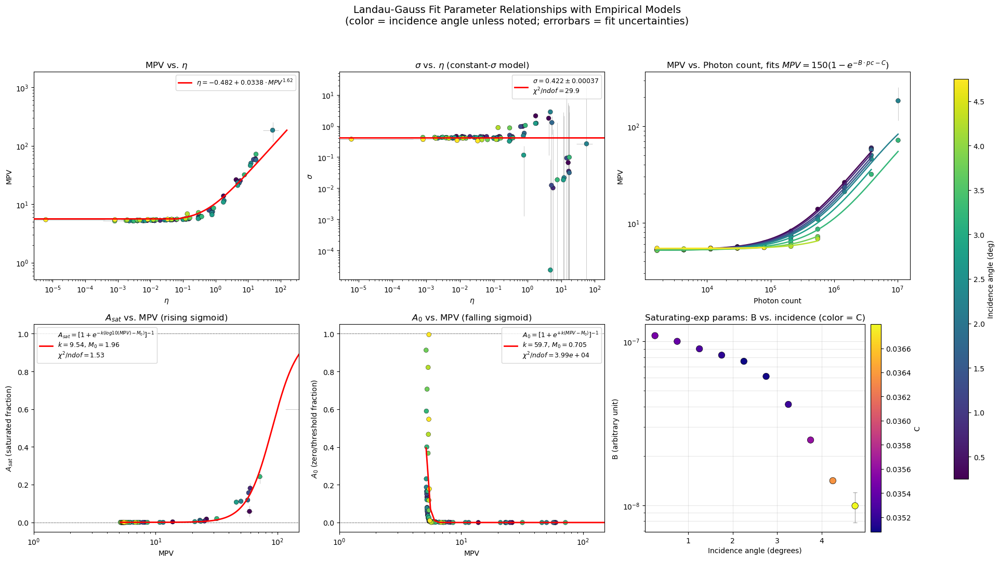

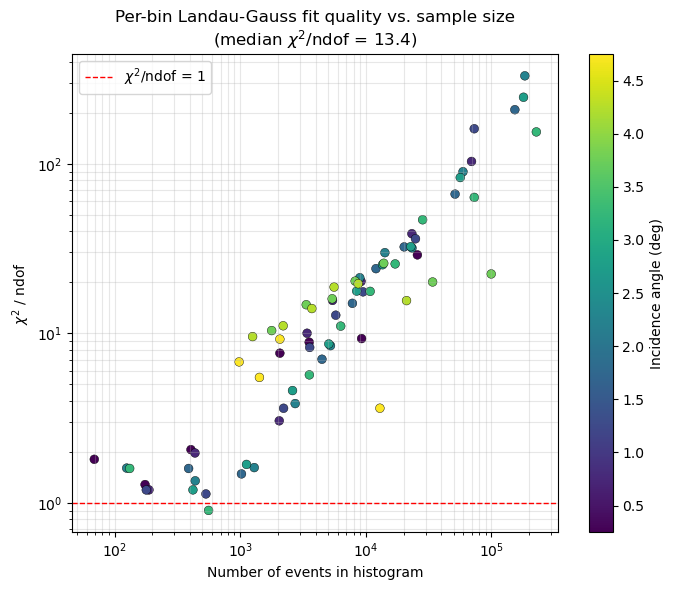


SUMMARY OF EMPIRICAL PARAMETER RELATIONS (weighted fits)
eta(MPV)        = -0.4817 + 0.03384 * MPV^1.616
sigma           = 0.4217 +/- 0.0003659 (constant; chi2/ndof = 29.9)
MPV(pc | inc)   = 150*(1 - exp(-B*pc - C)), fitted for 10 incidence angles
                  B range: [9.932e-09, 1.084e-07]
                  C range: [3.508e-02, 3.680e-02]
                  median chi2_red = 50.784
A_sat(MPV)      = 1/(1 + exp(-9.542*(MPV - 1.958)))   (chi2/ndof = 1.53)
A_0(MPV)        = 1/(1 + exp(+59.67*(MPV - 0.7049)))   (chi2/ndof = 3.99e+04)


In [30]:
# Load 2D fit results, fit empirical relations (weighted by
# uncertainties), and plot parameter relationships color-coded
# by incidence angle, with errorbars.
#
#   eta    = A_eta + B_eta * MPV^C_eta
#   sigma  = const                        (tested vs eta, chi2/ndf reported)
#   MPV    = 150*(1 - exp(-B*pc - C))     (per incidence angle)
#   A_sat  = 1/(1 + exp(-k*(MPV - M0)))   (rising sigmoid, asymptotes 0->1)
#   A_0    = 1/(1 + exp(+k*(MPV - M0)))   (falling sigmoid, asymptotes 1->0)
#   B(inc) colored by C                   (saturating-exp params)
# ---------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ---------------------------------------------------------
# 1. Load saved results
# ---------------------------------------------------------
data = np.load(npz_file, allow_pickle=True)

mpv       = data["mpv"]
eta       = data["eta"]
sigma     = data["sigma"]
A         = data["A"]
A_0       = data["A_0"]
A_sat     = data["A_sat"]
mpv_err   = data["mpv_err"]
eta_err   = data["eta_err"]
sigma_err = data["sigma_err"]
A_err     = data["A_err"]
A_0_err   = data["A_0_err"]
A_sat_err = data["A_sat_err"]
chi2_red  = data["chi2_red"]
n_events  = data["n_events"]
success   = data["success"]

N_I, N_PC_ACTUAL = mpv.shape

inc_edges = data["inc_edges"][:N_I + 1]
pc_edges  = data["pc_edges"][:N_PC_ACTUAL + 1]

print(f"Grid shape: ({N_I}, {N_PC_ACTUAL})")
print(f"Trimmed inc_edges: {len(inc_edges)} elements (expect {N_I + 1})")
print(f"Trimmed pc_edges: {len(pc_edges)} elements (expect {N_PC_ACTUAL + 1})")

inc_centers = 0.5 * (inc_edges[:-1] + inc_edges[1:])
pc_centers  = np.sqrt(pc_edges[:-1] * pc_edges[1:])   # geometric mean for log-spaced

inc_grid = np.repeat(inc_centers[:, None], N_PC_ACTUAL, axis=1)
pc_grid  = np.repeat(pc_centers[None, :], N_I, axis=0)

print(f"inc_grid shape: {inc_grid.shape}")
print(f"pc_grid shape: {pc_grid.shape}")

# ---------------------------------------------------------
# 2. Flatten arrays and keep only successful fits with finite,
#    positive uncertainties (needed for weighted fitting).
#    NOTE: A_0 / A_sat are now required finite as well (item 7).
# ---------------------------------------------------------
valid = (
    #success.astype(bool) &
    #(chi2_red <=2)&
    np.isfinite(mpv) & np.isfinite(eta) & np.isfinite(sigma) & np.isfinite(A)
    & np.isfinite(A_0) & np.isfinite(A_sat)
    & np.isfinite(mpv_err) & np.isfinite(eta_err) & np.isfinite(sigma_err) & np.isfinite(A_err)
    & np.isfinite(A_0_err) & np.isfinite(A_sat_err)
    & (mpv_err > 0) & (eta_err > 0) & (sigma_err > 0) & (A_err > 0)
    & (n_events > 0)
    #& (chi2_red <=1)
)

mpv_f       = mpv[valid]
eta_f       = eta[valid]
sigma_f     = sigma[valid]
A_f         = A[valid]
A_0_f       = A_0[valid]
A_sat_f     = A_sat[valid]
mpv_err_f   = mpv_err[valid]
eta_err_f   = eta_err[valid]
sigma_err_f = sigma_err[valid]
A_err_f     = A_err[valid]
A_0_err_f   = A_0_err[valid]
A_sat_err_f = A_sat_err[valid]
n_events_f  = n_events[valid]
inc_f       = inc_grid[valid]
pc_f        = pc_grid[valid]
chi2_f      = chi2_red[valid]

print(f"Total bins: {mpv.size}, valid fits (with usable errors): {valid.sum()}")

# ---------------------------------------------------------
# 2b. Error floor for the delta-fraction uncertainties (item 6).
#     fit_bin computes sqrt(k)/n, which is exactly 0 when k = 0.
#     Zero error -> infinite weight, which would dominate the
#     sigmoid fits. Floor those at the k=0 binomial scale 1/n.
# ---------------------------------------------------------
def floor_fraction_err(err, n):
    """Replace non-positive fraction errors with the k=0 scale 1/n."""
    err = np.asarray(err, dtype=float).copy()
    n   = np.asarray(n, dtype=float)
    bad = ~np.isfinite(err) | (err <= 0)
    err[bad] = 1.0 / np.maximum(n[bad], 1.0)
    return err

A_0_err_fit   = floor_fraction_err(A_0_err_f,   n_events_f)
A_sat_err_fit = floor_fraction_err(A_sat_err_f, n_events_f)

n_floor_0   = int(np.sum(A_0_err_f   <= 0))
n_floor_sat = int(np.sum(A_sat_err_f <= 0))
print(f"Error floor applied: A_0 -> {n_floor_0} points, "
      f"A_sat -> {n_floor_sat} points (k=0 bins, err set to 1/n)")

# ---------------------------------------------------------
# 3. Empirical model fits (weighted by uncertainties)
# ---------------------------------------------------------

# --- 3a. eta = A_eta + B_eta * MPV^C_eta  (unchanged) ---
def eta_model(mpv_val, A_eta, B_eta, C_eta):
    return A_eta + B_eta * np.power(mpv_val, C_eta)

order_mpv  = np.argsort(mpv_f)
mpv_sorted = mpv_f[order_mpv]

p0_eta = [0.0, 1.0, 1.0]

# pass 1: weight by eta_err only, to get a first estimate
popt_eta0, _ = curve_fit(
    eta_model, mpv_f, eta_f, p0=p0_eta,
    sigma=eta_err_f, absolute_sigma=True, maxfev=20000
)

# propagate MPV uncertainty into effective eta uncertainty
A_eta0, B_eta0, C_eta0 = popt_eta0
deta_dmpv   = B_eta0 * C_eta0 * np.power(mpv_f, C_eta0 - 1)
eta_err_eff = np.sqrt(eta_err_f ** 2 + (deta_dmpv * mpv_err_f) ** 2)

try:
    popt_eta, pcov_eta = curve_fit(
        eta_model, mpv_f, eta_f, p0=popt_eta0,
        sigma=eta_err_eff, absolute_sigma=True, maxfev=20000
    )
    A_eta, B_eta, C_eta = popt_eta
    perr_eta = np.sqrt(np.diag(pcov_eta))
    eta_fit_success = True
    print("\neta = A + B*MPV^C fit (weighted, incl. MPV error propagation):")
    print(f"  A = {A_eta:.4g} +/- {perr_eta[0]:.4g}")
    print(f"  B = {B_eta:.4g} +/- {perr_eta[1]:.4g}")
    print(f"  C = {C_eta:.4g} +/- {perr_eta[2]:.4g}")
except RuntimeError as e:
    print("eta vs mpv fit failed:", e)
    eta_fit_success = False

# --- 3b. sigma = const, tested against eta (item 1: (a) + chi2/ndf from (b)) ---
w_sigma         = 1.0 / sigma_err_f ** 2
sigma_const     = np.nanmedian(sigma_f)#np.sum(sigma_f * w_sigma) / np.sum(w_sigma)
sigma_const_err = np.sqrt(1.0 / np.sum(w_sigma))
sigma_const_std = np.std(sigma_f)

# chi2/ndf of the constant model (1 free parameter)
chi2_sigma      = np.sum(((sigma_f - sigma_const) / sigma_err_f) ** 2)
ndof_sigma      = len(sigma_f) - 1
chi2red_sigma   = chi2_sigma / ndof_sigma if ndof_sigma > 0 else np.nan

print(f"\nsigma = const fit (weighted mean over {len(sigma_f)} bins):")
print(f"  sigma_const = {sigma_const:.4g} +/- {sigma_const_err:.4g}")
print(f"  unweighted std = {sigma_const_std:.4g}")
print(f"  chi2/ndof = {chi2_sigma:.4g} / {ndof_sigma} = {chi2red_sigma:.4g}")
if np.isfinite(chi2red_sigma) and chi2red_sigma > 2:
    print("  -> chi2/ndof >> 1: sigma is NOT well described as eta-independent")

# --- 3c. MPV = 150*(1 - exp(-B*pc - C))   per incidence angle (unchanged) ---
def saturating_exp(pc, B, C):
    return 150.0 * (1.0 - np.exp(-B * pc - C))

unique_incs = np.unique(inc_f)

B_fit_list, C_fit_list = [], []
B_err_list, C_err_list = [], []
inc_list, chi2red_sat_list = [], []

print("\nMPV = 150*(1 - exp(-B*pc - C)) fits, per incidence angle:")
for inc_val in unique_incs:
    mask  = inc_f == inc_val
    pc_i  = pc_f[mask]
    mpv_i = mpv_f[mask]
    mpv_err_i = mpv_err_f[mask]

    if len(pc_i) < 3:
        continue

    order = np.argsort(pc_i)
    pc_i_s      = pc_i[order]
    mpv_i_s     = mpv_i[order]
    mpv_err_i_s = mpv_err_i[order]

    nonzero_err = mpv_err_i_s[mpv_err_i_s > 0]
    floor_val   = np.nanmedian(nonzero_err) if len(nonzero_err) > 0 else 1.0
    sigma_safe  = np.where(mpv_err_i_s > 0, mpv_err_i_s, floor_val)

    try:
        p0     = [1.0 / np.median(pc_i_s), 0.0]
        bounds = ([0, 0], [1, 1])
        popt, pcov = curve_fit(
            saturating_exp, pc_i_s, mpv_i_s,
            p0=p0, sigma=sigma_safe, absolute_sigma=True,
            bounds=bounds, maxfev=100000
        )
        B_fit, C_fit = popt
        B_err, C_err = np.sqrt(np.diag(pcov))

        mpv_pred = saturating_exp(pc_i_s, B_fit, C_fit)
        chi2     = np.sum(((mpv_i_s - mpv_pred) / sigma_safe) ** 2)
        dof      = len(pc_i_s) - 2
        chi2_r   = chi2 / dof if dof > 0 else np.nan

        B_fit_list.append(B_fit)
        C_fit_list.append(C_fit)
        B_err_list.append(B_err)
        C_err_list.append(C_err)
        inc_list.append(inc_val)
        chi2red_sat_list.append(chi2_r)

        print(f"  Incidence={inc_val:.3f}: B={B_fit:.3e}+/-{B_err:.1e}, "
              f"C={C_fit:.3e}+/-{C_err:.1e}, chi2_red={chi2_r:.3f}")
    except Exception as e:
        print(f"  Fit failed for incidence={inc_val:.3f}: {e}")
        continue

B_fit_arr = np.array(B_fit_list)
C_fit_arr = np.array(C_fit_list)
B_err_arr = np.array(B_err_list)
C_err_arr = np.array(C_err_list)
inc_arr   = np.array(inc_list)
chi2red_sat_arr = np.array(chi2red_sat_list)

# --- 3d. A_sat = 1/(1 + exp(-k*(MPV - M0)))   rising sigmoid, 0 -> 1 ---
def sigmoid_rise(mpv_val, k, M0):
    """Logistic rising from 0 to 1. Asymptotes FIXED at 0 and 1 (item 2)."""
    log_mpv = np.log10(mpv_val)
    z = -k * (log_mpv - M0)
    return 1.0 / (1.0 + np.exp(np.clip(z, -500, 500)))

# --- A_0 = 1/(1 + exp(+k*(MPV - M0)))   falling sigmoid, 1 -> 0 ---
def sigmoid_fall(mpv_val, k, M0):
    """Logistic falling from 1 to 0. Asymptotes FIXED at 1 and 0 (item 2)."""
    log_mpv = np.log10(mpv_val)
    z = k * (log_mpv - M0)
    return 1.0 / (1.0 + np.exp(np.clip(z, -500, 500)))

def fit_sigmoid(func, x, y, yerr, label, k_sign=+1.0):
    """Weighted sigmoid fit with a robust initial guess.

    k > 0 always; the rise/fall direction is baked into func.
    M0 is seeded at the MPV where y crosses 0.5, or the midpoint
    of the MPV range if no crossing is observed.
    """
    order = np.argsort(x)
    xs, ys = x[order], y[order]

    # seed M0 at the 0.5 crossing if one exists
    cross = np.where(np.diff(np.sign(ys - 0.5)) != 0)[0]
    M0_guess = xs[cross[0]] if len(cross) > 0 else 0.5 * (xs.min() + xs.max())

    span = max(xs.max() - xs.min(), 1e-12)
    k_guess = 10.0 / span     # transition over ~1/10 of the MPV range

    p0 = [k_guess, M0_guess]
    bounds = ([1e-12, -np.inf], [np.inf, np.inf])

    try:
        popt, pcov = curve_fit(
            func, x, y, p0=p0, sigma=yerr, absolute_sigma=True,
            bounds=bounds, maxfev=100000
        )
        perr = np.sqrt(np.diag(pcov))
        y_pred = func(x, *popt)
        chi2   = np.sum(((y - y_pred) / yerr) ** 2)
        dof    = len(x) - len(popt)
        chi2_r = chi2 / dof if dof > 0 else np.nan
        print(f"\n{label} sigmoid fit (weighted):")
        print(f"  k  = {popt[0]:.4g} +/- {perr[0]:.4g}")
        print(f"  M0 = {popt[1]:.4g} +/- {perr[1]:.4g}")
        print(f"  chi2/ndof = {chi2:.4g} / {dof} = {chi2_r:.4g}")
        return True, popt, perr, chi2_r
    except Exception as e:
        print(f"\n{label} sigmoid fit failed: {e}")
        return False, None, None, np.nan

sat_fit_success, popt_sat, perr_sat, chi2red_sat_sig = fit_sigmoid(
    sigmoid_rise, mpv_f, A_sat_f, A_sat_err_fit, "A_sat vs MPV (rising)"
)
a0_fit_success, popt_a0, perr_a0, chi2red_a0_sig = fit_sigmoid(
    sigmoid_fall, mpv_f, A_0_f, A_0_err_fit, "A_0 vs MPV (falling)"
)

# ---------------------------------------------------------
# 4. Plot: 3 columns x 2 rows
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
cmap = "viridis"
cmap_obj = plt.get_cmap(cmap)
norm = plt.Normalize(vmin=inc_f.min(), vmax=inc_f.max())

def errorbar_then_scatter(ax, x, y, xerr, yerr, c, cmap, **scatter_kwargs):
    """Plot grey errorbars first, then colored scatter points on top."""
    ax.errorbar(
        x, y, xerr=xerr, yerr=yerr,
        fmt="none", ecolor="gray", elinewidth=0.6, alpha=0.5,
        capsize=0, zorder=1
    )
    sc = ax.scatter(x, y, c=c, cmap=cmap, zorder=2, **scatter_kwargs)
    return sc

# --- [0,0] MPV vs eta (kept as-is) ---
ax = axes[0, 0]
sc = errorbar_then_scatter(
    ax, eta_f, mpv_f, eta_err_f, mpv_err_f, inc_f, cmap,
    s=40, edgecolor="k", linewidth=0.3
)
if eta_fit_success:
    mpv_dense = np.linspace(mpv_sorted.min(), mpv_sorted.max(), 400)
    eta_dense = eta_model(mpv_dense, *popt_eta)
    ax.plot(eta_dense, mpv_dense, "r-", lw=2, zorder=3,
            label=f"$\\eta = {A_eta:.3g} + {B_eta:.3g}\\cdot MPV^{{{C_eta:.3g}}}$")
    ax.legend(fontsize=9)
    ax.set_ylim(mpv_dense.min() / 10, mpv_dense.max() * 10)
ax.set_xlabel(r"$\eta$")
ax.set_ylabel("MPV")
ax.set_title("MPV vs. $\\eta$")
ax.set_yscale("log")
ax.set_xscale("log")
#ax.grid(alpha=0.3)

# --- [0,1] sigma vs eta, constant-sigma model ---
ax = axes[0, 1]
errorbar_then_scatter(
    ax, eta_f, sigma_f, eta_err_f, sigma_err_f, inc_f, cmap,
    s=40, edgecolor="k", linewidth=0.3
)
ax.axhline(sigma_const, color="r", lw=2, zorder=3,
           label=f"$\\sigma = {sigma_const:.3g} \\pm {sigma_const_err:.2g}$\n"
                 f"$\\chi^2/ndof = {chi2red_sigma:.3g}$")
ax.axhspan(sigma_const - sigma_const_err, sigma_const + sigma_const_err,
           color="r", alpha=0.15, zorder=0)
ax.legend(fontsize=9)
ax.set_xlabel(r"$\eta$")
ax.set_ylabel(r"$\sigma$")
ax.set_title(r"$\sigma$ vs. $\eta$ (constant-$\sigma$ model)")
ax.set_xscale("log")
ax.set_yscale("log")
#ax.grid(alpha=0.3, which="both")

# --- [0,2] MPV vs photon count (saturating-exp fit per incidence) ---
ax = axes[0, 2]
errorbar_then_scatter(
    ax, pc_f, mpv_f, None, mpv_err_f, inc_f, cmap,
    s=40, edgecolor="k", linewidth=0.3
)
for inc_val, B_fit, C_fit in zip(inc_arr, B_fit_arr, C_fit_arr):
    mask = inc_f == inc_val
    pc_i = pc_f[mask]
    if len(pc_i) < 3:
        continue
    pc_smooth  = np.logspace(np.log10(pc_i.min()), np.log10(pc_i.max()), 200)
    mpv_smooth = saturating_exp(pc_smooth, B_fit, C_fit)
    ax.plot(pc_smooth, mpv_smooth, "-", color=cmap_obj(norm(inc_val)),
            lw=1.8, zorder=3)
ax.set_xlabel("Photon count")
ax.set_ylabel("MPV")
ax.set_title(r"MPV vs. Photon count, fits $MPV = 150(1-e^{-B\cdot pc-C})$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(min(mpv_f) / 2, max(mpv_f) * 2)
#ax.grid(alpha=0.3, which="both")

# --- [1,0] A_sat vs MPV (rising sigmoid) --- linear axes (item 3/5)
ax = axes[1, 0]
errorbar_then_scatter(
    ax, mpv_f, A_sat_f, mpv_err_f, A_sat_err_fit, inc_f, cmap,
    s=40, edgecolor="k", linewidth=0.3
)
if sat_fit_success:
    mpv_dense_s = np.linspace(mpv_f.min(), mpv_f.max(), 400)
    ax.plot(mpv_dense_s, sigmoid_rise(mpv_dense_s, *popt_sat),
            "r-", lw=2, zorder=3,
            label=f"$A_{{sat}} = [1+e^{{-k(log10(MPV)-M_0)}}]^{{-1}}$\n"
                  f"$k = {popt_sat[0]:.3g}$, $M_0 = {popt_sat[1]:.3g}$\n"
                  f"$\\chi^2/ndof = {chi2red_sat_sig:.3g}$")
    ax.legend(fontsize=9, loc="upper left")
ax.axhline(0.0, color="k", lw=0.8, ls=":", zorder=0)
ax.axhline(1.0, color="k", lw=0.8, ls=":", zorder=0)
ax.set_xlabel("MPV")
ax.set_ylabel(r"$A_{sat}$ (saturated fraction)")
ax.set_title(r"$A_{sat}$ vs. MPV (rising sigmoid)")
#ax.set_ylim(-0.05, 1.05)
ax.set_xlim(1, 150)
ax.set_xscale("log")
#ax.grid(alpha=0.3)

# --- [1,1] A_0 vs MPV (falling sigmoid) --- linear axes (item 3/5)
ax = axes[1, 1]
errorbar_then_scatter(
    ax, mpv_f, A_0_f, mpv_err_f, A_0_err_fit, inc_f, cmap,
    s=40, edgecolor="k", linewidth=0.3
)
if a0_fit_success:
    mpv_dense_0 = np.linspace(mpv_f.min(), mpv_f.max(), 400)
    ax.plot(mpv_dense_0, sigmoid_fall(mpv_dense_0, *popt_a0),
            "r-", lw=2, zorder=3,
            label=f"$A_0 = [1+e^{{+k(MPV-M_0)}}]^{{-1}}$\n"
                  f"$k = {popt_a0[0]:.3g}$, $M_0 = {popt_a0[1]:.3g}$\n"
                  f"$\\chi^2/ndof = {chi2red_a0_sig:.3g}$")
    ax.legend(fontsize=9, loc="upper right")
ax.axhline(0.0, color="k", lw=0.8, ls=":", zorder=0)
ax.axhline(1.0, color="k", lw=0.8, ls=":", zorder=0)
ax.set_xlabel("MPV")
ax.set_ylabel(r"$A_0$ (zero/threshold fraction)")
ax.set_title(r"$A_0$ vs. MPV (falling sigmoid)")
ax.set_ylim(-0.05, 1.05)
ax.set_xlim(1, 150)
ax.set_xscale("log")
#ax.set_yscale("symlog")
#ax.grid(alpha=0.3)

# --- [1,2] Saturating-exp params: B vs incidence, colored by C ---
ax = axes[1, 2]
if len(inc_arr) > 0:
    ax.errorbar(inc_arr, B_fit_arr, yerr=B_err_arr,
                fmt="none", ecolor="gray", elinewidth=1, capsize=3,
                alpha=0.6, zorder=2)
    sc_bc = ax.scatter(inc_arr, B_fit_arr, c=C_fit_arr, cmap="plasma", s=80,
                       edgecolor="k", linewidth=0.5, zorder=3)
    cbar_bc = fig.colorbar(sc_bc, ax=ax, pad=0.02)
    cbar_bc.set_label("C")
    ax.set_yscale("log")
    #ax.set_ylim(1e-9, 1e-6)
else:
    ax.text(0.5, 0.5, "no saturating-exp fits", ha="center", va="center",
            transform=ax.transAxes)
ax.set_xlabel("Incidence angle (degrees)")
ax.set_ylabel("B (arbitrary unit)")
ax.set_title("Saturating-exp params: B vs. incidence (color = C)")
ax.grid(alpha=0.3, which="both")

fig.subplots_adjust(right=0.90)
cbar_ax = fig.add_axes([0.92, 0.15, 0.014, 0.7])
cbar = fig.colorbar(sc, cax=cbar_ax)
cbar.set_label("Incidence angle (deg)")

fig.suptitle("Landau-Gauss Fit Parameter Relationships with Empirical Models\n"
             "(color = incidence angle unless noted; errorbars = fit uncertainties)",
             fontsize=14)
plt.tight_layout(rect=[0, 0, 0.90, 0.95])
plt.show()

# ---------------------------------------------------------
# 5. chi2_red vs n_events (separate figure, unchanged)
# ---------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(7, 6))
sc2 = ax2.scatter(n_events_f, chi2_f, c=inc_f, cmap=cmap, s=40,
                  edgecolor="k", linewidth=0.3)
ax2.set_xlabel("Number of events in histogram")
ax2.set_ylabel(r"$\chi^2$ / ndof")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.axhline(1.0, color="red", linestyle="--", linewidth=1, label="$\\chi^2$/ndof = 1")
ax2.set_title("Per-bin Landau-Gauss fit quality vs. sample size\n"
              f"(median $\\chi^2$/ndof = {np.nanmedian(chi2_f):.3g})")
ax2.legend()
ax2.grid(alpha=0.3, which="both")
cbar2 = fig2.colorbar(sc2, ax=ax2)
cbar2.set_label("Incidence angle (deg)")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. Summary
# ---------------------------------------------------------
print("\n" + "=" * 60)
print("SUMMARY OF EMPIRICAL PARAMETER RELATIONS (weighted fits)")
print("=" * 60)
if eta_fit_success:
    print(f"eta(MPV)        = {A_eta:.4g} + {B_eta:.4g} * MPV^{C_eta:.4g}")
print(f"sigma           = {sigma_const:.4g} +/- {sigma_const_err:.4g} "
      f"(constant; chi2/ndof = {chi2red_sigma:.3g})")
if len(inc_arr) > 0:
    print(f"MPV(pc | inc)   = 150*(1 - exp(-B*pc - C)), fitted for "
          f"{len(inc_arr)} incidence angles")
    print(f"                  B range: [{B_fit_arr.min():.3e}, {B_fit_arr.max():.3e}]")
    print(f"                  C range: [{C_fit_arr.min():.3e}, {C_fit_arr.max():.3e}]")
    print(f"                  median chi2_red = {np.nanmedian(chi2red_sat_arr):.3f}")
if sat_fit_success:
    print(f"A_sat(MPV)      = 1/(1 + exp(-{popt_sat[0]:.4g}*(MPV - {popt_sat[1]:.4g})))"
          f"   (chi2/ndof = {chi2red_sat_sig:.3g})")
if a0_fit_success:
    print(f"A_0(MPV)        = 1/(1 + exp(+{popt_a0[0]:.4g}*(MPV - {popt_a0[1]:.4g})))"
          f"   (chi2/ndof = {chi2red_a0_sig:.3g})")
print("=" * 60)

In [23]:
# Complete Model (loads precomputed fit results, no recomputation)
import numpy as np
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import plotly.io as pio
pio.renderers.default = "notebook"
npz_file = "landau_gauss_2d_fit_results_test.npz"

def mpl_to_plotly_colorscale(name, n=256):
    cmap = plt.get_cmap(name)
    return [[i / (n - 1), to_hex(cmap(i / (n - 1)))] for i in range(n)]

terrain_pl = mpl_to_plotly_colorscale("terrain")

# =========================================================
# CONFIG
# =========================================================
PE_THRESHOLD = 20.0
N_MIN_TRIG   = 1
LINTHRESH    = 1e-3

# =========================================================
# 1. Load precomputed fit results
# =========================================================
data = np.load(npz_file, allow_pickle=True)

inc_edges = data["inc_edges"]
pc_edges  = data["pc_edges"]

n_events   = data["n_events"]
success    = data["success"]
frac_valid = data["frac_valid"]
n_body     = data["n_body"]
at_bound   = data["at_bound"]

A          = data["A"]
A_err      = data["A_err"]
A_0        = data["A_0"]
A_0_err    = data["A_0_err"]
A_sat      = data["A_sat"]
A_sat_err  = data["A_sat_err"]
k_0        = data["k_0"]
k_mid      = data["k_mid"]
k_sat      = data["k_sat"]
n_total    = data["n_total"]

efficiency_data     = data["efficiency_data"]
efficiency_data_err = data["efficiency_data_err"]

mpv        = data["mpv"]
eta        = data["eta"]
sigma      = data["sigma"]
mpv_err    = data["mpv_err"]
eta_err    = data["eta_err"]
sigma_err  = data["sigma_err"]

chi2       = data["chi2"]
ndof       = data["ndof"]
chi2_red   = data["chi2_red"]
nll        = data["nll"]

efficiency     = data["efficiency"]
efficiency_err = data["efficiency_err"]

cov = data["cov"]

N_I, N_PC_ACTUAL = mpv.shape

# =========================================================
# 2. Provenance: data-driven vs. per-bin model
# =========================================================
with np.errstate(invalid="ignore"):
    n_trig_equiv = efficiency_data * n_total

use_data   = (n_trig_equiv >= N_MIN_TRIG) & frac_valid & np.isfinite(efficiency_data)
use_perbin = (~use_data) & success & frac_valid & np.isfinite(efficiency)

eff_hybrid = np.full((N_I, N_PC_ACTUAL), np.nan)
eff_hybrid[use_data]   = efficiency_data[use_data]
eff_hybrid[use_perbin] = efficiency[use_perbin]
eff_hybrid = np.clip(eff_hybrid, 0.0, 1.0)

provenance = np.zeros((N_I, N_PC_ACTUAL), dtype=int)
provenance[use_data]   = 1
provenance[use_perbin] = 2

print(f"\nTier 1 (data, n_total >= {N_MIN_TRIG}) : {use_data.sum()}")
print(f"Tier 2 (per-bin langau fit)        : {use_perbin.sum()}")
print(f"No estimate                        : {(provenance == 0).sum()}")
print(f"Total bins                         : {N_I * N_PC_ACTUAL}")

# =========================================================
# 3. Blocky (exact) boundaries between provenance regions
# =========================================================
def staircase_segments(mask):
    xs, ys = [], []

    def add(x0, y0, x1, y1):
        xs.extend([x0, x1, None])
        ys.extend([y0, y1, None])

    ni, nj = mask.shape
    for i in range(ni):
        for j in range(nj):
            if not mask[i, j]:
                continue
            x_l, x_r = pc_edges[j], pc_edges[j + 1]
            y_b, y_t = inc_edges[i], inc_edges[i + 1]
            if j == 0      or not mask[i, j - 1]: add(x_l, y_b, x_l, y_t)
            if j == nj - 1 or not mask[i, j + 1]: add(x_r, y_b, x_r, y_t)
            if i == 0      or not mask[i - 1, j]: add(x_l, y_b, x_r, y_b)
            if i == ni - 1 or not mask[i + 1, j]: add(x_l, y_t, x_r, y_t)
    return xs, ys

x_data_b,   y_data_b   = staircase_segments(use_data)
x_perbin_b, y_perbin_b = staircase_segments(use_perbin)   # <-- NEW: model boundary

# =========================================================
# 4. Symlog transform for the colour scale
# =========================================================
def symlog_fwd(v, lt=LINTHRESH):
    v = np.asarray(v, dtype=float)
    return np.sign(v) * np.log10(1.0 + np.abs(v) / lt)

z_sym = symlog_fwd(eff_hybrid)
z_min, z_max = 0.0, symlog_fwd(1.0)

tick_vals_eff = [0.0, 1e-4, 1e-3, 1e-2, 0.1, 0.3, 0.5, 1.0]
tick_pos  = [float(symlog_fwd(v)) for v in tick_vals_eff]
tick_text = ["0" if v == 0 else (f"{v:g}" if v >= 0.01 else f"{v:.0e}")
             for v in tick_vals_eff]

# =========================================================
# 5. Hover text
# =========================================================
prov_name = {0: "no estimate", 1: "DATA", 2: "per-bin fit"}

customdata = np.empty((N_I, N_PC_ACTUAL), dtype=object)
for i in range(N_I):
    for j in range(N_PC_ACTUAL):
        e = eff_hybrid[i, j]
        p = provenance[i, j]
        lines = [
            f"<b>eff = {e:.2e}</b>" if np.isfinite(e) else "<b>eff = n/a</b>",
            f"source: {prov_name[p]}",
            f"inc: [{inc_edges[i]:.3g}, {inc_edges[i+1]:.3g}] deg",
            f"pc:  [{pc_edges[j]:.3g}, {pc_edges[j+1]:.3g}]",
            f"n_events = {int(n_events[i, j])}, n_trigger = {n_total[i, j]*efficiency_data[i,j]:.3g}",
        ]
        if p == 1 and np.isfinite(efficiency_data_err[i, j]):
            lines.append(f"stat err = ±{efficiency_data_err[i, j]:.2e}")
        if p == 2:
            lines.append(f"mpv={mpv[i,j]:.4g}, eta={eta[i,j]:.4g}, "
                         f"sigma={sigma[i,j]:.4g}")
            lines.append(f"A={A[i,j]:.4g}, A_0={A_0[i,j]:.4g}, "
                         f"A_sat={A_sat[i,j]:.4g}")
            if np.isfinite(efficiency_err[i, j]):
                lines.append(f"model stat err = ±{efficiency_err[i,j]:.2e}")
            lines.append(f"chi2_red = {chi2_red[i,j]:.3g}")
        if np.isfinite(efficiency[i, j]) and p == 1:
            lines.append(f"(per-bin model would give {efficiency[i,j]:.2e})")
        customdata[i, j] = "<br>".join(lines)

# =========================================================
# 6. Plot
# =========================================================
fig = go.Figure()

fig.add_trace(go.Heatmap(
    x=pc_edges, y=inc_edges, z=z_sym,
    customdata=customdata,
    hovertemplate="%{customdata}<extra></extra>",
    colorscale="plasma",
    zmin=z_min, zmax=z_max,
    colorbar=dict(
        title=dict(text=f"Efficiency<br>(Max_PE ≥ {PE_THRESHOLD:.0f})", side="right"),
        tickmode="array", tickvals=tick_pos, ticktext=tick_text,
        len=0.9,
    ),
    hoverongaps=False,
    name="efficiency",
))

fig.add_trace(go.Scatter(
    x=x_data_b, y=y_data_b, mode="lines",
    line=dict(color="crimson", width=2.5),
    name=f"data region (n_total ≥ {N_MIN_TRIG})",
    hoverinfo="skip",
))

fig.add_trace(go.Scatter(                                  # <-- NEW
    x=x_perbin_b, y=y_perbin_b, mode="lines",
    line=dict(color="black", width=2.0, dash="dash"),
    name="per-bin model region",
    hoverinfo="skip",
))

fig.update_xaxes(type="log", title_text="Photon Count",
                 range=[np.log10(pc_edges[0]), np.log10(pc_edges[-1])])
fig.update_yaxes(title_text="Incidence (deg)",
                 range=[inc_edges[0], inc_edges[-1]])

fig.update_layout(
    title=(f"Hybrid Trigger Efficiency (Max_PE ≥ {PE_THRESHOLD:.0f})<br>"
           f"<sup>data where n_total ≥ {N_MIN_TRIG}; per-bin langau fit otherwise. "
           f"symlog colour, linthresh={LINTHRESH:g}</sup>"),
    width=1100, height=700,
    template="plotly_white",
    legend=dict(orientation="h", yanchor="bottom", y=1.02,
                xanchor="right", x=1.0),
)

fig.show()

# =========================================================
# 7. Cross-check in the overlap region
# =========================================================
both = use_data & np.isfinite(efficiency) & (efficiency_data > 0)
if both.sum():
    r = (efficiency[both] - efficiency_data[both]) / efficiency_data[both]
    print(f"\nOverlap check ({both.sum()} bins where data is used and a "
          f"per-bin model also exists):")
    print(f"  median (model-data)/data = {np.median(r):+.4g}")
    print(f"  16-84 pct               = [{np.percentile(r,16):+.4g}, "
          f"{np.percentile(r,84):+.4g}]")
else:
    print("\nNo overlap bins available for a model-vs-data cross-check.")


Tier 1 (data, n_total >= 1) : 777
Tier 2 (per-bin langau fit)        : 775
No estimate                        : 448
Total bins                         : 2000



Overlap check (300 bins where data is used and a per-bin model also exists):
  median (model-data)/data = +0.1818
  16-84 pct               = [-0.05583, +2.644]


Model efficiency loaded for 1075 / 2000 bins
Data efficiency computed for 1941 / 2000 bins (nonzero count bins)


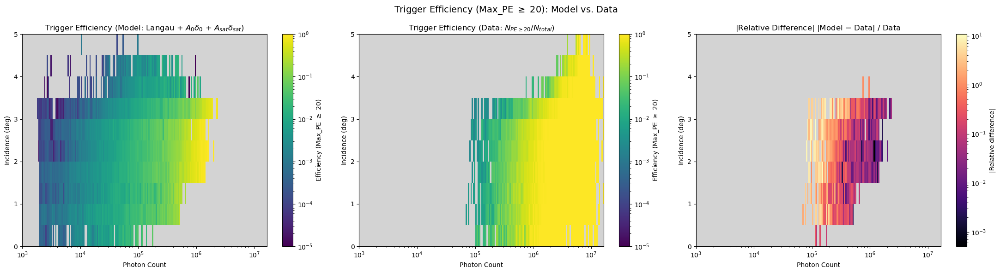


Median |relative difference| = 0.2351
Bins compared: 304 / 2000


In [26]:
# Compare Data and Model:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
print_data = False
# ---------------------------------------------------------
# 1. Load fit results (efficiency loaded directly, not recomputed)
# ---------------------------------------------------------
data = np.load(npz_file, allow_pickle=True)

mpv        = data["mpv"]
eta        = data["eta"]
sigma      = data["sigma"]
A          = data["A"]
A_0        = data["A_0"]
A_sat      = data["A_sat"]
n_events   = data["n_events"]
success    = data["success"]
frac_valid = data["frac_valid"]

efficiency     = data["efficiency"]
efficiency_err = data["efficiency_err"]

inc_edges = data["inc_edges"]
pc_edges  = data["pc_edges"]

N_I, N_PC_ACTUAL = mpv.shape

PE_THRESHOLD = 20.0

# ---------------------------------------------------------
# 2. Model trigger efficiency -- loaded from npz
# ---------------------------------------------------------
eff_model     = np.array(efficiency, dtype=float)
eff_model_err = np.array(efficiency_err, dtype=float)

valid_model = success & frac_valid & np.isfinite(eff_model)
eff_model     = np.where(valid_model, eff_model, np.nan)
eff_model_err = np.where(valid_model, eff_model_err, np.nan)
eff_model     = np.clip(eff_model, 0.0, 1.0)

print(f"Model efficiency loaded for {np.isfinite(eff_model).sum()} / "
      f"{N_I*N_PC_ACTUAL} bins")


# ---------------------------------------------------------
# 3. Data trigger efficiency -- vectorized with histogram2d
#    (two passes over the data instead of 600 masked passes)
# ---------------------------------------------------------
mask2d_eff = (
    np.isfinite(Max_PE) & np.isfinite(photon_count) & np.isfinite(Incidence)
    & (photon_count >= pc_edges[0]) & (photon_count <= pc_edges[-1])
    & (Incidence >= inc_edges[0]) & (Incidence <= inc_edges[-1])
    & (R == 0) & (Energy_GeV <= 5e5)
)

pe_d  = np.asarray(Max_PE[mask2d_eff],       dtype=float)
pc_d  = np.asarray(photon_count[mask2d_eff], dtype=float)
inc_d = np.asarray(Incidence[mask2d_eff],    dtype=float)

# histogram2d closes the last bin on the right, matching the original
# "include right edge in last bin" special case.
n_tot, _, _ = np.histogram2d(inc_d, pc_d, bins=[inc_edges, pc_edges])

trig = pe_d >= PE_THRESHOLD
n_trig, _, _ = np.histogram2d(inc_d[trig], pc_d[trig], bins=[inc_edges, pc_edges])

n_data = n_tot.astype(int)
with np.errstate(divide="ignore", invalid="ignore"):
    eff_data = np.where(n_tot > 0, n_trig / n_tot, np.nan)
    eff_data_err = np.where(
        n_tot > 0,
        np.sqrt(np.clip(eff_data * (1.0 - eff_data), 0.0, None) / np.maximum(n_tot, 1)),
        np.nan)

print(f"Data efficiency computed for {np.isfinite(eff_data).sum()} / "
      f"{N_I*N_PC_ACTUAL} bins (nonzero count bins)")


# ---------------------------------------------------------
# 3b. Print model vs data efficiency (with uncertainty) side by side
# ---------------------------------------------------------
both_finite = np.isfinite(eff_model) & np.isfinite(eff_data)
if print_data == True:
    print(f"\nModel vs Data efficiency (bins with both defined: {both_finite.sum()}):")
    print(f"{'inc range':>18} {'pc range':>20} {'eff_model':>12} {'eff_data':>12}")
    for i, j in zip(*np.nonzero(both_finite)):
        em, eme = eff_model[i, j], eff_model_err[i, j]
        ed, ede = eff_data[i, j], eff_data_err[i, j]
        inc_str = f"[{inc_edges[i]:.2f},{inc_edges[i+1]:.2f})"
        pc_str  = f"[{pc_edges[j]:.3e},{pc_edges[j+1]:.3e})"
        print(f"{inc_str:>18} {pc_str:>20} "
              f"{em:6.4f}±{eme:6.4f} {ed:6.4f}±{ede:6.4f}")


# ---------------------------------------------------------
# 4. Relative difference: (model - data) / data
# ---------------------------------------------------------
with np.errstate(divide="ignore", invalid="ignore"):
    rel_diff = np.where(
        (eff_data > 0) & np.isfinite(eff_data) & np.isfinite(eff_model),
        (eff_model - eff_data) / eff_data,
        np.nan
    )


# ---------------------------------------------------------
# 5. Plot -- log color scale
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# LogNorm cannot show zeros; mask them so they render as blank.
eff_model_p = np.where(eff_model > 0, eff_model, np.nan)
eff_data_p  = np.where(eff_data  > 0, eff_data,  np.nan)

finite_eff = np.concatenate([
    eff_model_p[np.isfinite(eff_model_p)].ravel(),
    eff_data_p[np.isfinite(eff_data_p)].ravel(),
])
eff_vmin = max(finite_eff.min(), 1e-5) if finite_eff.size else 1e-5
eff_norm = LogNorm(vmin=eff_vmin, vmax=1.0)

cmap_eff = plt.get_cmap("viridis").copy()
cmap_eff.set_bad("lightgrey")

# --- Panel 1: model efficiency ---
ax = axes[0]
pcm0 = ax.pcolormesh(pc_edges, inc_edges, eff_model_p, cmap=cmap_eff,
                     norm=eff_norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Trigger Efficiency (Model: Langau + $A_0\\delta_0$ + $A_{sat}\\delta_{sat}$)")
fig.colorbar(pcm0, ax=ax, label="Efficiency (Max_PE $\\geq$ 20)")

# --- Panel 2: data efficiency ---
ax = axes[1]
pcm1 = ax.pcolormesh(pc_edges, inc_edges, eff_data_p, cmap=cmap_eff,
                     norm=eff_norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Trigger Efficiency (Data: $N_{PE\\geq20}/N_{total}$)")
fig.colorbar(pcm1, ax=ax, label="Efficiency (Max_PE $\\geq$ 20)")

# --- Panel 3: relative difference (log magnitude, signed colormap) ---
ax = axes[2]
rel_abs = np.abs(rel_diff)
rel_abs_p = np.where(rel_abs > 0, rel_abs, np.nan)
finite_rel = rel_abs_p[np.isfinite(rel_abs_p)]
rel_vmin = max(finite_rel.min(), 1e-4) if finite_rel.size else 1e-4
rel_vmax = max(finite_rel.max(), rel_vmin * 10) if finite_rel.size else 1.0

cmap_rel = plt.get_cmap("magma").copy()
cmap_rel.set_bad("lightgrey")

pcm2 = ax.pcolormesh(pc_edges, inc_edges, rel_abs_p, cmap=cmap_rel,
                     norm=LogNorm(vmin=rel_vmin, vmax=rel_vmax), shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("|Relative Difference| $|$Model $-$ Data$|$ / Data")
fig.colorbar(pcm2, ax=ax, label="|Relative difference|")

fig.suptitle(f"Trigger Efficiency (Max_PE $\\geq$ {PE_THRESHOLD:.0f}): Model vs. Data",
             fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nMedian |relative difference| = {np.nanmedian(np.abs(rel_diff)):.4g}")
print(f"Bins compared: {np.isfinite(rel_diff).sum()} / {N_I*N_PC_ACTUAL}")

Pull computed for 1018 / 2000 bins
Mean pull = 11.175, median = 3.522, RMS = 69.106
Fraction |pull| > 3: 0.292


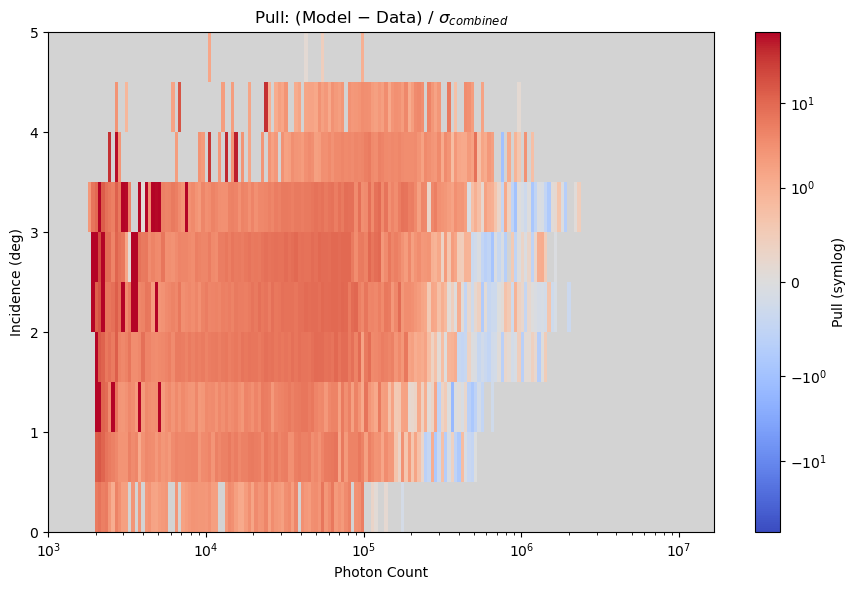

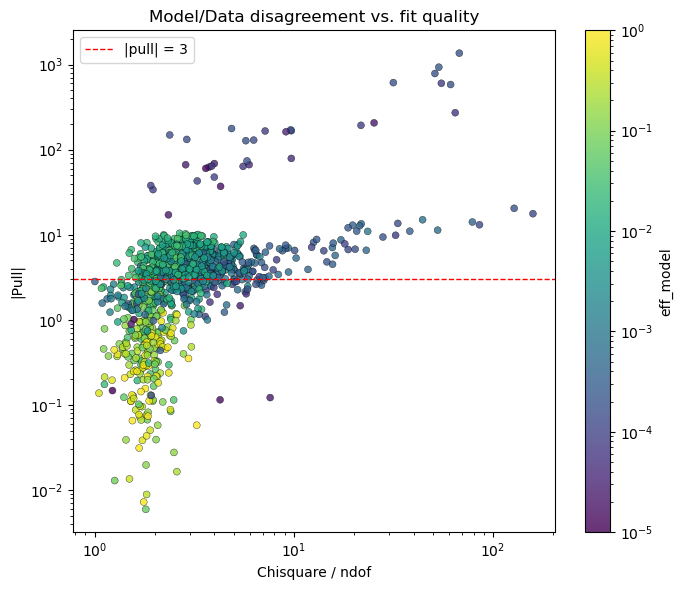

Correlation coefficient (log Deviance/ndof vs log|pull|): 0.544


In [27]:
# 6. Pull analysis: (model - data) significance, and its
#    correlation with fit quality (Deviance/ndof)
# ---------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

# chi2_red/ndof per bin -- adjust the key name if your npz uses a
# different one (e.g. "deviance_ndof", "chi2_ndof", etc.)
dev_ndof = data["chi2_red"] if "chi2_red" in data else None

# --- pull = (model - data) / combined uncertainty ---
with np.errstate(divide="ignore", invalid="ignore"):
    pull = np.where(
        np.isfinite(eff_model) & np.isfinite(eff_data)
        & (n_data > 0) & np.isfinite(eff_model_err),
        (eff_model - eff_data) /
        np.sqrt(np.nan_to_num(eff_model_err, nan=0.0)**2 +
                np.nan_to_num(eff_data_err,  nan=0.0)**2),
        np.nan
    )

n_pull = np.isfinite(pull).sum()
print(f"Pull computed for {n_pull} / {N_I*N_PC_ACTUAL} bins")
print(f"Mean pull = {np.nanmean(pull):.3f}, "
      f"median = {np.nanmedian(pull):.3f}, "
      f"RMS = {np.sqrt(np.nanmean(pull**2)):.3f}")
print(f"Fraction |pull| > 3: {np.nanmean(np.abs(pull) > 3):.3f}")

# ---------------------------------------------------------
# 6a. 2D heatmap of pull over (inc, pc)
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

pull_abs_max = np.nanpercentile(np.abs(pull), 98) if n_pull else 1.0
# linear threshold around 0 -- region below this is shown linearly,
# beyond it switches to log scaling. Tune linthresh to taste (e.g. 1-3
# since |pull| < 3 is "good").
linthresh = 1.0
norm = SymLogNorm(linthresh=linthresh, vmin=-pull_abs_max, vmax=pull_abs_max,
                   base=10)

cmap_pull = plt.get_cmap("coolwarm").copy()
cmap_pull.set_bad("lightgrey")

pcm = ax.pcolormesh(pc_edges, inc_edges, pull, cmap=cmap_pull,
                     norm=norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Pull: (Model $-$ Data) / $\\sigma_{combined}$")
fig.colorbar(pcm, ax=ax, label="Pull (symlog)")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6b. Pull vs. Deviance/ndof scatter -- checks whether large
#     model/data disagreement tracks with poor Langau fits
# ---------------------------------------------------------
if dev_ndof is not None:
    mask_both = np.isfinite(pull) & np.isfinite(dev_ndof)
    x = dev_ndof[mask_both]
    y = np.abs(pull[mask_both])

    fig, ax = plt.subplots(figsize=(7, 6))
    sc = ax.scatter(x, y, c=eff_model[mask_both], cmap="viridis",
                     norm=LogNorm(vmin=max(eff_model[mask_both].min(), 1e-5),
                                  vmax=1.0),
                     s=25, alpha=0.8, edgecolor="k", linewidth=0.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Chisquare / ndof")
    ax.set_ylabel("|Pull|")
    ax.set_title("Model/Data disagreement vs. fit quality")
    fig.colorbar(sc, ax=ax, label="eff_model")
    ax.axhline(3, color="red", ls="--", lw=1, label="|pull| = 3")
    ax.legend()
    plt.tight_layout()
    plt.show()

    if x.size > 2:
        r = np.corrcoef(np.log10(x), np.log10(y))[0, 1]
        print(f"Correlation coefficient (log Deviance/ndof vs log|pull|): {r:.3f}")
else:
    print("No 'deviance_ndof' array found in the npz -- skipping panel 6b. "
          "Check the key name used when the fit results were saved.")

Test Model 2

In [40]:
# Fitting Landau-Gauss-Body & GEV⊗Gauss-Body -- binned Poisson likelihood version
# WEIGHTED version: the max_PE distribution is contaminated by the parent
# photon_count distribution. weights_pc (same length as photon_count) makes the
# PC distribution flat in log; we apply it to each PE event before fitting.
#
# Weighting scheme (effective counts):
#   W_bin  = sum of w in a PE bin ; W2_bin = sum of w^2 in that bin
#   n_i^eff = W_bin^2 / W2_bin   (variance-matching Poisson count)
#   fractions + data efficiency use W=sum w with n_eff = Wtot^2 / sum(w^2)
import os
from scipy.stats import norm, genextreme
import numpy as np
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(v, "1")
from concurrent.futures import ProcessPoolExecutor, as_completed
import pylandau
import logging
from scipy.integrate import cumulative_trapezoid
from iminuit import Minuit
from iminuit.util import IMinuitWarning
import warnings

logging.getLogger("pylandau").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=IMinuitWarning)

# ---------------------------------------------------------
# 0. Configuration
# ---------------------------------------------------------
PE_THRESHOLD = 20.0
N_P = 10
N_I = 10
EQUAL_COUNT_BINS = False
PC_RANGE  = (1e3, float(np.nanmax(photon_count)))
INC_RANGE = (0.0, 5)
MIN_EVENTS_PER_BIN = 50
N_WORKERS = os.cpu_count()
XMIN_CUT = 1
XMAX_CUT = 149
N_BINS_PE = 100
PDF_CUT = 1e-4

SIGMA_MIN = 0
KAPPA_LO = 1e-3
KAPPA_HI = 2e3
EPS_MU    = 1e-12

LAMBDA_TRIGGER = 0.0
BIN_EDGES_PE = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), N_BINS_PE + 1)
BIN_WIDTHS   = np.diff(BIN_EDGES_PE)
BIN_CENTERS  = 0.5 * (BIN_EDGES_PE[:-1] + BIN_EDGES_PE[1:])
BIN_LO       = BIN_EDGES_PE[:-1]
BIN_HI       = BIN_EDGES_PE[1:]

X_LO, X_HI = XMIN_CUT, XMAX_CUT
N_GRID     = 100
X_GRID     = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), N_GRID)

_GH_T, _GH_W = np.polynomial.hermite.hermgauss(64)
_GH_W = _GH_W / np.sqrt(np.pi)

# ---------------------------------------------------------
# 0b. Weighted-count helpers
# ---------------------------------------------------------
def _eff_count(w_subset):
    """Effective (variance-matching) number of events for a weights array."""
    w = np.asarray(w_subset, dtype=float)
    W = float(w.sum())
    W2 = float(np.sum(w * w))
    return W * W / W2 if W2 > 0 else 0.0


def _weighted_hist(pe_vals, w_vals, edges):
    """Return (bin_weight_sum, bin_weight2_sum) histograms."""
    W, _  = np.histogram(pe_vals, bins=edges, weights=w_vals)
    W2, _ = np.histogram(pe_vals, bins=edges, weights=w_vals ** 2)
    return W.astype(float), W2.astype(float)


def _effective_bin_counts(W, W2):
    """n_i^eff = W_i^2/W2_i ; 0 where W_i == 0."""
    n = np.zeros_like(W, dtype=float)
    ok = W2 > 0
    n[ok] = np.maximum(W[ok], 0.0) ** 2 / W2[ok]
    return n


# ---------------------------------------------------------
# 1. Global selection (carry weights along)
# ---------------------------------------------------------
mask2d = (
    np.isfinite(Max_PE) & np.isfinite(photon_count) & np.isfinite(Incidence)
    & (photon_count >= PC_RANGE[0]) & (photon_count <= PC_RANGE[1])
    & (Incidence >= INC_RANGE[0]) & (Incidence <= INC_RANGE[1])
    & (R == 0) & (Energy_GeV <= 5e5)
)

pe_all  = np.asarray(Max_PE[mask2d],       dtype=float)
pc_all  = np.asarray(photon_count[mask2d], dtype=float)
inc_all = np.asarray(Incidence[mask2d],    dtype=float)
w_all   = np.asarray(weights_pc[mask2d],   dtype=float)   # <-- weights applied

w_all = np.where(np.isfinite(pe_all), w_all, 0.0)         # guard non-finite PE

# ---------------------------------------------------------
# 2. Build 2D bin edges
# ---------------------------------------------------------
if EQUAL_COUNT_BINS:
    quantiles = np.linspace(0, 1, N_P + 1)
    pc_edges = np.unique(np.quantile(pc_all, quantiles))
    quantiles = np.linspace(0, 1, N_I + 1)
    inc_edges = np.unique(np.quantile(inc_all, quantiles))
    if len(pc_edges) - 1 != N_P:
        print(f"WARNING: equal-count binning produced {len(pc_edges)-1} unique bins instead of {N_P}")
else:
    inc_edges = np.linspace(INC_RANGE[0], INC_RANGE[1], N_I + 1)
    pc_edges = np.logspace(np.log10(PC_RANGE[0]), np.log10(PC_RANGE[1]), N_P + 1)

print("Incidence bin edges:", inc_edges)
print("Photon count bin edges:", pc_edges)

# ---------------------------------------------------------
# 3. Landau-Gauss body model (unchanged)
# ---------------------------------------------------------
def landau_gauss(x, mpv, eta, sigma, Amplitude):
    sigma_val = np.atleast_1d(sigma)[0] if isinstance(sigma, np.ndarray) else sigma
    eta_val = np.atleast_1d(eta)[0] if isinstance(eta, np.ndarray) else eta
    if sigma_val < SIGMA_MIN:
        return Amplitude * pylandau.landau(x, mpv, eta)
    kappa = eta_val / sigma_val
    if kappa >= KAPPA_HI:
        return Amplitude * pylandau.landau(x, mpv, eta)
    if kappa < KAPPA_LO:
        return Amplitude * np.exp(-0.5 * ((x - mpv) / sigma_val) ** 2) / (
            sigma_val * np.sqrt(2 * np.pi))
    return pylandau.langau(x, mpv, eta, sigma, Amplitude)


def _shape_unnorm(x, mpv, eta, sigma):
    return landau_gauss(np.asarray(x, dtype=float), mpv, eta, sigma, 1.0)


def _expected_counts_lg(mpv, eta, sigma, n_body):
    f = _shape_unnorm(BIN_EDGES_PE, mpv, eta, sigma)
    if not np.all(np.isfinite(f)):
        return None
    f = np.maximum(f, 0.0)
    integ = 0.5 * (f[:-1] + f[1:]) * BIN_WIDTHS
    tot = integ.sum()
    if not np.isfinite(tot) or tot <= 0.0:
        return None
    return n_body * integ / tot


_surv_cache = {}
def body_survival(threshold, mpv_val, eta_val, sigma_val, max_pe_body=0):
    if not all(np.isfinite(v) for v in (threshold, mpv_val, eta_val, sigma_val)):
        return np.nan
    if sigma_val <= 0 or eta_val < 0:
        return np.nan
    lo, hi = XMIN_CUT, XMAX_CUT
    if threshold <= lo:
        return 1.0
    if threshold >= hi:
        return 0.0
    key = tuple(round(float(v), 5) for v in (threshold, mpv_val, eta_val, sigma_val))
    if key in _surv_cache:
        return _surv_cache[key]
    try:
        y = _shape_unnorm(X_GRID, mpv_val, eta_val, sigma_val)
        if not np.all(np.isfinite(y)):
            raise ValueError("Non-finite PDF values")
        cdf = cumulative_trapezoid(y, X_GRID, initial=0.0)
        Fa, Fb, Ft = np.interp([lo, hi, threshold], X_GRID, cdf)
        denom = Fb - Fa
        out = (Fb - Ft) / denom if denom > 0 else np.nan
    except Exception:
        out = np.nan
    out = float(np.clip(out, 0.0, 1.0)) if np.isfinite(out) else np.nan
    _surv_cache[key] = out
    return out

# ---------------------------------------------------------
# 3b. GEV ⊗ Gaussian body model (unchanged)
# ---------------------------------------------------------
def _gev_shape_unnorm(x, mu, scale, xi, sg):
    x = np.asarray(x, dtype=float)[..., None]
    s = np.sqrt(2.0) * sg * _GH_T
    with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
        y = genextreme.pdf(x - s, -xi, loc=mu, scale=scale)
    return np.sum(_GH_W * np.where(np.isfinite(y), y, 0.0), axis=-1)


def _expected_counts_gev(mu, scale, xi, sg, n_body):
    f = _gev_shape_unnorm(BIN_EDGES_PE, mu, scale, xi, sg)
    if not np.all(np.isfinite(f)):
        return None
    f = np.maximum(f, 0.0)
    integ = 0.5 * (f[:-1] + f[1:]) * BIN_WIDTHS
    tot = integ.sum()
    if not np.isfinite(tot) or tot <= 0.0:
        return None
    return n_body * integ / tot


def _gev_conv_sf(x, mu, scale, xi, sg):
    x = np.asarray(x, dtype=float)[..., None]
    s = np.sqrt(2.0) * sg * _GH_T
    with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
        S = genextreme.sf(x - s, -xi, loc=mu, scale=scale)
    return np.sum(_GH_W * np.where(np.isfinite(S), S, 0.0), axis=-1)


def body_survival_gev(threshold, mu, scale, xi, sg):
    if not all(np.isfinite(v) for v in (mu, scale, xi, sg)):
        return np.nan
    if scale <= 0 or sg < 0:
        return np.nan
    lo, hi = XMIN_CUT, XMAX_CUT
    if threshold <= lo:
        return 1.0
    if threshold >= hi:
        return 0.0
    try:
        Slo = float(_gev_conv_sf(lo, mu, scale, xi, sg))
        Shi = float(_gev_conv_sf(hi, mu, scale, xi, sg))
        Sth = float(_gev_conv_sf(threshold, mu, scale, xi, sg))
        denom = Slo - Shi
        out = (Sth - Shi) / denom if denom > 0 else np.nan
    except Exception:
        out = np.nan
    return float(np.clip(out, 0.0, 1.0)) if np.isfinite(out) else np.nan

# ---------------------------------------------------------
# 3c. Trigger efficiency + error propagation (unchanged)
# ---------------------------------------------------------
def combine_efficiency(p_surv, A, A_sat):
    if not np.isfinite(p_surv):
        return np.nan
    return A_sat + A * p_surv


def trigger_efficiency(mpv, eta, sigma, A, A_sat, threshold=PE_THRESHOLD, max_pe_body=0):
    return combine_efficiency(body_survival(threshold, mpv, eta, sigma, max_pe_body), A, A_sat)


def trigger_efficiency_gev(mu, scale, xi, sg, A, A_sat, threshold=PE_THRESHOLD):
    return combine_efficiency(body_survival_gev(threshold, mu, scale, xi, sg), A, A_sat)


def _propagate_survival_error(survival_fn, params, cov, A, A_err, A_sat, A_sat_err, eps=1e-3):
    if cov is None or not np.all(np.isfinite(cov)):
        return np.nan
    params = np.array(params, dtype=float)
    n = len(params)
    p0 = survival_fn(*params)
    if not np.isfinite(p0):
        return np.nan
    grad = np.zeros(n)
    for k in range(n):
        step = max(abs(params[k]) * eps, 1e-6)
        d = np.zeros(n); d[k] = step
        p_plus  = survival_fn(*(params + d))
        p_minus = survival_fn(*(params - d))
        grad[k] = (p_plus - p_minus) / (2.0 * step) if np.isfinite(p_plus) and np.isfinite(p_minus) else 0.0
    var_p = max(float(grad @ cov @ grad), 0.0)
    var_eff = (A_sat_err ** 2 if np.isfinite(A_sat_err) else 0.0)
    var_eff += (p0 ** 2) * (A_err ** 2 if np.isfinite(A_err) else 0.0)
    var_eff += (A ** 2) * var_p
    return float(np.sqrt(var_eff)) if np.isfinite(var_eff) and var_eff >= 0 else np.nan

# ---------------------------------------------------------
# 3d. Population fractions -- WEIGHTED
# ---------------------------------------------------------
def compute_fractions(pe_vals, w_vals=None):
    """
    Weighted population fractions (A_0, A, A_sat) and their errors.

        A     : weighted fraction in [XMIN_CUT, XMAX_CUT)            (body)
        A_0   : weighted fraction below XMIN_CUT
        A_sat : weighted fraction at/above XMAX_CUT

    Errors use a reweighted binomial with n_eff = Wtot^2 / sum(w^2).
    """
    pe_vals = np.asarray(pe_vals, dtype=float)
    if w_vals is None:
        w_vals = np.ones_like(pe_vals)
    w_vals = np.asarray(w_vals, dtype=float)

    if len(pe_vals) == 0:
        return dict(A=np.nan, A_err=np.nan,
                    A_0=np.nan, A_0_err=np.nan,
                    A_sat=np.nan, A_sat_err=np.nan,
                    k_0=0, k_mid=0, k_sat=0, n_total=0,
                    frac_valid=False)

    W_tot = float(w_vals.sum())
    W2_tot = float(np.sum(w_vals * w_vals))
    if W_tot <= 0 or not np.isfinite(W_tot):
        return dict(A=np.nan, A_err=np.nan,
                    A_0=np.nan, A_0_err=np.nan,
                    A_sat=np.nan, A_sat_err=np.nan,
                    k_0=0, k_mid=0, k_sat=0, n_total=0,
                    frac_valid=False)

    m0  = pe_vals < XMIN_CUT
    ms  = pe_vals >= XMAX_CUT
    mm  = (pe_vals >= XMIN_CUT) & (pe_vals < XMAX_CUT)
    W0   = float(w_vals[m0].sum())
    Wsat = float(w_vals[ms].sum())
    Wmid = float(w_vals[mm].sum())

    n_eff = W_tot * W_tot / W2_tot if W2_tot > 0 else 0.0

    def _werr(Wgrp):
        p = Wgrp / W_tot
        return np.sqrt(max(p * (1.0 - p), 0.0) / n_eff) if n_eff > 0 else np.nan

    return dict(
        A=Wmid / W_tot,        A_err=_werr(Wmid),
        A_0=W0 / W_tot,        A_0_err=_werr(W0),
        A_sat=Wsat / W_tot,    A_sat_err=_werr(Wsat),
        k_0=int(W0), k_mid=int(Wmid), k_sat=int(Wsat), n_total=int(W_tot),
        frac_valid=True,
    )

# ---------------------------------------------------------
# 3e. Poisson likelihood helpers (unchanged)
# ---------------------------------------------------------
def _poisson_nll(mu, counts):
    mu = np.maximum(mu, EPS_MU)
    return np.sum(mu - counts * np.log(mu))


def _trigger_nll(p, k_trig, n_body):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(k_trig * np.log(p) + (n_body - k_trig) * np.log(1 - p))

def _poisson_deviance(mu, counts):
    mu = np.maximum(mu, EPS_MU)
    n  = counts.astype(float)
    term = mu - n
    nz = n > 0
    term[nz] += n[nz] * np.log(n[nz] / mu[nz])
    return 2.0 * np.sum(term)

# ---------------------------------------------------------
# 3f. Minuit helper (unchanged)
# ---------------------------------------------------------
def _is_near_bound(value, limit, rtol=1e-3):
    return abs(value - limit) <= rtol * max(abs(limit), 1.0)


def _run_minuit(cost_func, start, limits, strategies=(0, 1), ncall=None):
    m = Minuit(cost_func, **start)
    for name, (lo, hi) in limits.items():
        m.limits[name] = (lo, hi)
    for strategy in strategies:
        m.strategy = strategy
        m.migrad(ncall=ncall) if ncall else m.migrad()
        m.hesse()
        if m.valid:
            break
    return m

# ---------------------------------------------------------
# 3g. Body-shape fits (counts are now EFFECTIVE weighted counts)
# ---------------------------------------------------------
_LG_EMPTY = dict(
    success=False, valid_minuit=False, at_bound=False,
    mpv=np.nan, eta=np.nan, sigma=np.nan,
    mpv_err=np.nan, eta_err=np.nan, sigma_err=np.nan,
    cov=None, nll=np.nan,
    chi2=np.nan, ndof=np.nan, chi2_red=np.nan,
    error_msg=None,
)

_GEV_EMPTY = dict(
    success_gev=False, valid_minuit_gev=False, at_bound_gev=False,
    mu_gev=np.nan, scale_gev=np.nan, xi_gev=np.nan, sg_gev=np.nan,
    mu_gev_err=np.nan, scale_gev_err=np.nan, xi_gev_err=np.nan, sg_gev_err=np.nan,
    cov_gev=None, nll_gev=np.nan,
    chi2_gev=np.nan, ndof_gev=np.nan, chi2_red_gev=np.nan,
    error_msg_gev=None,
)


def fit_landau_gauss(counts, pe_body, n_body, k_trig):
    """Binned Poisson-likelihood fit of the Landau-Gauss body (weighted counts)."""
    out = dict(_LG_EMPTY)
    dens = counts / BIN_WIDTHS
    mpv_guess = float(BIN_CENTERS[np.argmax(dens)])
    q16, q84 = np.percentile(pe_body, [16.0, 84.0])
    spread = max(float(q84 - q16), 1e-3)
    eta_guess = max(spread / 4.0, 1e-3)
    sigma_guess = max(spread / 4.0, 1e-3)

    max_pe_body = np.max(pe_body)
    def cost(mpv, eta, sigma):
        mu = _expected_counts_lg(mpv, eta, sigma, n_body)
        if mu is None:
            return 1e12
        p = body_survival(PE_THRESHOLD, mpv, eta, sigma)
        if not np.isfinite(p):
            return 1e12
        val = _poisson_nll(mu, counts) + LAMBDA_TRIGGER * _trigger_nll(p, k_trig, n_body)
        return val if np.isfinite(val) else 1e12
    cost.errordef = Minuit.LIKELIHOOD

    m = _run_minuit(
        cost, dict(mpv=mpv_guess, eta=eta_guess, sigma=sigma_guess),
        {"mpv": (1, 1000), "eta": (0, XMAX_CUT), "sigma": (0, XMAX_CUT)},
        strategies=(0, 1), ncall=2000,
    )
    if not m.valid:
        m = _run_minuit(
            cost,
            dict(mpv=mpv_guess, eta=max(spread / 8.0, 1e-3), sigma=max(spread / 2.0, 1e-3)),
            {"mpv": (0, 1000), "eta": (0, XMAX_CUT * 2), "sigma": (0, XMAX_CUT * 2)},
            strategies=(2,),
        )

    out["valid_minuit"] = bool(m.valid)
    mpv_fit, eta_fit, sigma_fit = (
        float(m.values["mpv"]), float(m.values["eta"]), float(m.values["sigma"])
    )
    out["mpv"], out["eta"], out["sigma"] = mpv_fit, eta_fit, sigma_fit
    out["at_bound"] = bool(
        _is_near_bound(eta_fit, 1e-4) or _is_near_bound(sigma_fit, 1e-4)
        or _is_near_bound(eta_fit, XMAX_CUT - XMIN_CUT)
        or _is_near_bound(sigma_fit, XMAX_CUT - XMIN_CUT)
        or _is_near_bound(mpv_fit, XMIN_CUT) or _is_near_bound(mpv_fit, XMAX_CUT)
    )
    if not m.valid:
        out["error_msg"] = "Minuit did not converge"
        return out
    try:
        cov = np.array(m.covariance, dtype=float)
        if cov.shape != (3, 3) or not np.all(np.isfinite(cov)):
            cov = None
    except Exception:
        cov = None
    perr = np.sqrt(np.clip(np.diag(cov), 0.0, None)) if cov is not None else np.full(3, np.nan)
    out["cov"] = cov
    out["mpv_err"], out["eta_err"], out["sigma_err"] = perr

    mu_best = _expected_counts_lg(mpv_fit, eta_fit, sigma_fit, n_body)
    if mu_best is None:
        out["error_msg"] = "Model evaluation failed at best fit"
        return out
    n_used = int(np.count_nonzero(counts))
    chi2 = _poisson_deviance(mu_best, counts)
    ndof = n_used - 3
    out.update(dict(
        success=True, nll=float(m.fval),
        chi2=float(chi2), ndof=int(ndof),
        chi2_red=chi2 / ndof if ndof > 0 else np.nan,
    ))
    return out


def fit_gev_gauss(counts, pe_body, n_body):
    """Binned Poisson-likelihood fit of the GEV⊗Gauss body (weighted counts)."""
    out = dict(_GEV_EMPTY)
    dens = counts / BIN_WIDTHS
    mpv_guess = float(BIN_CENTERS[np.argmax(dens)])
    q16, q84 = np.percentile(pe_body, [16.0, 84.0])
    spread = max(float(q84 - q16), 1e-3)
    scale_guess = max(spread / 4.0, 1e-3)
    sg_guess = max(spread / 4.0, 1e-3)
    xi_guess = 0.3

    def cost_gev(mu, scale, xi, sg):
        mu_ = _expected_counts_gev(mu, scale, xi, sg, n_body)
        if mu_ is None:
            return 1e12
        val = _poisson_nll(mu_, counts)
        return val if np.isfinite(val) else 1e12
    cost_gev.errordef = Minuit.LIKELIHOOD

    m = _run_minuit(
        cost_gev,
        dict(mu=mpv_guess, scale=scale_guess, xi=xi_guess, sg=sg_guess),
        {"mu": (0, 10 * XMAX_CUT), "scale": (1e-3, XMAX_CUT),
         "xi": (-0.9, 2.0), "sg": (0, 10 * XMAX_CUT)},
        strategies=(0, 1), ncall=2000,
    )
    if not m.valid:
        m = _run_minuit(
            cost_gev,
            dict(mu=mpv_guess, scale=max(spread / 8.0, 1e-3),
                 xi=0.0, sg=max(spread / 2.0, 1e-3)),
            {"mu": (0, 10 * XMAX_CUT), "scale": (1e-3, 2 * XMAX_CUT),
             "xi": (-0.9, 2.0), "sg": (0, 20 * XMAX_CUT)},
            strategies=(2,),
        )

    out["valid_minuit_gev"] = bool(m.valid)
    mu_fit = float(m.values["mu"])
    sc_fit = float(m.values["scale"])
    xi_fit = float(m.values["xi"])
    sg_fit = float(m.values["sg"])
    out["mu_gev"], out["scale_gev"], out["xi_gev"], out["sg_gev"] = mu_fit, sc_fit, xi_fit, sg_fit
    out["at_bound_gev"] = bool(
        _is_near_bound(sc_fit, 1e-3) or _is_near_bound(sc_fit, 2 * XMAX_CUT)
        or _is_near_bound(xi_fit, -0.9) or _is_near_bound(xi_fit, 2.0)
        or _is_near_bound(sg_fit, 1e-3) or _is_near_bound(sg_fit, 20 * XMAX_CUT)
        or _is_near_bound(mu_fit, 0.0) or _is_near_bound(mu_fit, 10 * XMAX_CUT)
    )
    if not m.valid:
        out["error_msg_gev"] = "Minuit (GEV) did not converge"
        return out
    try:
        cov = np.array(m.covariance, dtype=float)
        if cov.shape != (4, 4) or not np.all(np.isfinite(cov)):
            cov = None
    except Exception:
        cov = None
    if cov is not None:
        perr = np.sqrt(np.clip(np.diag(cov), 0, None))
        (out["mu_gev_err"], out["scale_gev_err"],
         out["xi_gev_err"], out["sg_gev_err"]) = perr
    out["cov_gev"] = cov

    mu_best = _expected_counts_gev(mu_fit, sc_fit, xi_fit, sg_fit, n_body)
    if mu_best is None:
        out["error_msg_gev"] = "GEV evaluation failed at best fit"
        return out
    chi2 = _poisson_deviance(mu_best, counts)
    ndof = int(np.count_nonzero(counts)) - 4
    out.update(dict(
        success_gev=True, nll_gev=float(m.fval),
        chi2_gev=float(chi2), ndof_gev=ndof,
        chi2_red_gev=chi2 / ndof if ndof > 0 else np.nan,
    ))
    return out

# ---------------------------------------------------------
# 4. Worker function -- weighted per-bin fit
# ---------------------------------------------------------
def fit_bin(args):
    """
    args: i_inc, i_pc, inc_lo, inc_hi, pc_lo, pc_hi, pe_vals, pe_w.
    All counts/fractions/efficiency are WEIGHTED by pe_w (effective counts).
    """
    i_inc, i_pc = args["i_inc"], args["i_pc"]
    inc_lo, inc_hi = args["inc_lo"], args["inc_hi"]
    pc_lo, pc_hi = args["pc_lo"], args["pc_hi"]
    pe_vals = args["pe_vals"]
    w_vals  = args["pe_w"]
    n_events = len(pe_vals)
    pe_vals = np.asarray(pe_vals, dtype=float)
    w_vals  = np.asarray(w_vals,  dtype=float)

    result = {
        "i_inc": i_inc, "i_pc": i_pc,
        "inc_lo": inc_lo, "inc_hi": inc_hi,
        "pc_lo": pc_lo, "pc_hi": pc_hi,
        "n_events": n_events, "n_body": 0,
        "bin_centers": None, "counts": None, "bin_edges": None,
        "efficiency": np.nan, "efficiency_err": np.nan,
        "efficiency_data": np.nan, "efficiency_data_err": np.nan,
        "efficiency_gev": np.nan, "efficiency_gev_err": np.nan,
        "delta_nll": np.nan,
    }
    result.update(_LG_EMPTY)
    result.update(_GEV_EMPTY)
    result.update(compute_fractions(pe_vals, w_vals))

    # --- weighted data efficiency (always available) ---
    if n_events > 0:
        finite = np.isfinite(pe_vals)
        W_all = float(w_vals[finite].sum())
        W_trig = float(w_vals[finite & (pe_vals >= PE_THRESHOLD)].sum())
        if W_all > 0:
            eff_data = W_trig / W_all
            n_eff_all = _eff_count(w_vals[finite])
            result["efficiency_data"] = eff_data
            result["efficiency_data_err"] = (
                np.sqrt(max(eff_data * (1.0 - eff_data), 0.0) / n_eff_all)
                if n_eff_all > 0 else np.nan)
        else:
            result["efficiency_data"] = np.nan
            result["efficiency_data_err"] = np.nan

    # --- body selection (weighted) ---
    body_mask = np.isfinite(pe_vals) & (pe_vals >= XMIN_CUT)
    w_body = w_vals[body_mask]
    pe_body = pe_vals[body_mask]
    n_body = _eff_count(w_body)
    result["n_body"] = int(round(n_body))

    if n_body < MIN_EVENTS_PER_BIN:
        result["error_msg"] = (f"Too few weighted body events (n_eff={n_body:.1f} "
                               f"< {MIN_EVENTS_PER_BIN})")
        return result

    try:
        pe_body_min = pe_body.min()
        pe_body_max = pe_body.max()
        pe_body_sel = pe_body[(pe_body >= pe_body_min) & (pe_body < pe_body_max)]
        w_body_sel  = w_body[(pe_body >= pe_body_min) & (pe_body < pe_body_max)]
        n_body = _eff_count(w_body_sel)
        result["n_body"] = int(round(n_body))

        if n_body < MIN_EVENTS_PER_BIN:
            result["error_msg"] = f"Not enough weighted body events ({n_body:.1f} < {MIN_EVENTS_PER_BIN})"
            return result

        # --- weighted (effective) histogram ---
        W_bin, W2_bin = _weighted_hist(pe_body_sel, w_body_sel, BIN_EDGES_PE)
        counts = _effective_bin_counts(W_bin, W2_bin)     # effective per-bin counts
        result["bin_centers"] = BIN_CENTERS.copy()
        result["counts"] = counts
        result["bin_edges"] = BIN_EDGES_PE.copy()

        if np.count_nonzero(counts) < 5:
            result["error_msg"] = "Too few nonempty bins for fitting"
            return result

        # effective trigger count for the (optional) trigger-regularization term
        k_trig = _eff_count(w_vals[np.isfinite(pe_vals) & (pe_vals >= PE_THRESHOLD)])

        # --- GEV⊗Gauss body fit ---
        try:
            result.update(fit_gev_gauss(counts, pe_body, n_body))
        except Exception as e:
            result["error_msg_gev"] = str(e)
        if result["success_gev"]:
            result["efficiency_gev"] = trigger_efficiency_gev(
                result["mu_gev"], result["scale_gev"], result["xi_gev"], result["sg_gev"],
                result["A"], result["A_sat"])
            result["efficiency_gev_err"] = _propagate_survival_error(
                lambda mu, scale, xi, sg: body_survival_gev(PE_THRESHOLD, mu, scale, xi, sg),
                (result["mu_gev"], result["scale_gev"], result["xi_gev"], result["sg_gev"]),
                result["cov_gev"],
                result["A"], result["A_err"], result["A_sat"], result["A_sat_err"],
                eps=1e-4)

        # --- Landau-Gauss body fit ---
        result.update(fit_landau_gauss(counts, pe_body, n_body, k_trig))
        if result["success"]:
            result["efficiency"] = trigger_efficiency(
                result["mpv"], result["eta"], result["sigma"], result["A"], result["A_sat"], max_pe_body=pe_body_max)
            result["efficiency_err"] = _propagate_survival_error(
                lambda mpv, eta, sigma: body_survival(PE_THRESHOLD, mpv, eta, sigma, max_pe_body=pe_body_max),
                (result["mpv"], result["eta"], result["sigma"]), result["cov"],
                result["A"], result["A_err"], result["A_sat"], result["A_sat_err"],
                eps=1e-3)

        # --- model comparison: delta_nll > 0 means GEV⊗Gauss fits better ---
        if result["success"] and result["success_gev"]:
            result["delta_nll"] = result["nll"] - result["nll_gev"]

    except Exception as e:
        result["error_msg"] = str(e)

    return result

# ---------------------------------------------------------
# 5. Prepare all 2D bin jobs (weights sorted alongside PE)
# ---------------------------------------------------------
N_PC = len(pc_edges) - 1
inc_idx = np.clip(np.searchsorted(inc_edges, inc_all, side="right") - 1, 0, N_I - 1)
pc_idx  = np.clip(np.searchsorted(pc_edges,  pc_all,  side="right") - 1, 0, N_PC - 1)
flat    = inc_idx * N_PC + pc_idx

order    = np.argsort(flat, kind="stable")
pe_sorted = pe_all[order]
w_sorted  = w_all[order]
bounds   = np.searchsorted(flat[order], np.arange(N_I * N_PC + 1))

jobs = []
for i_inc in range(N_I):
    for i_pc in range(N_PC):
        k = i_inc * N_PC + i_pc
        jobs.append({
            "i_inc": i_inc, "i_pc": i_pc,
            "inc_lo": inc_edges[i_inc], "inc_hi": inc_edges[i_inc + 1],
            "pc_lo": pc_edges[i_pc],    "pc_hi": pc_edges[i_pc + 1],
            "pe_vals": pe_sorted[bounds[k]:bounds[k + 1]],
            "pe_w":    w_sorted[bounds[k]:bounds[k + 1]],
        })

print(f"Total 2D bins to fit: {len(jobs)}  (weights applied to max_PE)")
jobs.sort(key=lambda j: len(j["pe_vals"]), reverse=True)

# ---------------------------------------------------------
# 6. Run fits in parallel
# ---------------------------------------------------------
results = []
with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
    futures = {executor.submit(fit_bin, job): job for job in jobs}
    for i, future in enumerate(as_completed(futures)):
        res = future.result()
        results.append(res)
        if res["success"]:
            status = "OK" + (" [AT BOUND]" if res["at_bound"] else "")
        else:
            frac_note = " [fractions stored]" if res["frac_valid"] else ""
            status = f"FAILED ({res['error_msg']}){frac_note}"
        eff_str = (
            f"eff_LG={res['efficiency']:.2e}\u00b1{res['efficiency_err']:.2e} "
            f"eff_GEV={res['efficiency_gev']:.2e}\u00b1{res['efficiency_gev_err']:.2e} "
            f"eff_data={res['efficiency_data']:.2e}\u00b1{res['efficiency_data_err']:.2e}"
        )
        print(f"[{i+1}/{len(jobs)}] "
              f"inc=[{res['inc_lo']:.2f},{res['inc_hi']:.2f}) "
              f"pc=[{res['pc_lo']:.2e},{res['pc_hi']:.2e}) "
              f"n_events={res['n_events']} n_body={res['n_body']} -> {status}, "
              f"Dev/ndof LG={res['chi2_red']:.3g} GEV={res['chi2_red_gev']:.3g}, {eff_str}")

# Sort results back into a consistent (i_inc, i_pc) order
results.sort(key=lambda r: (r["i_inc"], r["i_pc"]))

# ---------------------------------------------------------
# 7. Organize results into arrays (unchanged, but counts are effective)
# ---------------------------------------------------------
N_PC_ACTUAL = len(pc_edges) - 1

def _nan_array(*extra_shape):
    return np.full((N_I, N_PC_ACTUAL) + extra_shape, np.nan)

def _bool_array():
    return np.zeros((N_I, N_PC_ACTUAL), dtype=bool)

def _int_array():
    return np.zeros((N_I, N_PC_ACTUAL), dtype=int)

SCALAR_FLAG_KEYS = ("n_events", "success", "frac_valid", "n_body", "at_bound", "success_gev", "at_bound_gev")
FRAC_KEYS = ("A", "A_err", "A_0", "A_0_err", "A_sat", "A_sat_err",
             "k_0", "k_mid", "k_sat", "n_total",
             "efficiency_data", "efficiency_data_err")
LG_KEYS = ("mpv", "eta", "sigma", "mpv_err", "eta_err", "sigma_err",
           "chi2", "ndof", "chi2_red", "nll", "efficiency", "efficiency_err")
GEV_KEYS = ("mu_gev", "scale_gev", "xi_gev", "sg_gev",
            "mu_gev_err", "scale_gev_err", "xi_gev_err", "sg_gev_err",
            "chi2_gev", "ndof_gev", "chi2_red_gev", "nll_gev",
            "efficiency_gev", "efficiency_gev_err")

fit_params = {
    **{k: _nan_array() for k in
       ("mpv", "eta", "sigma", "A", "A_0", "A_sat",
        "mpv_err", "eta_err", "sigma_err", "A_err", "A_0_err", "A_sat_err",
        "chi2", "ndof", "chi2_red",
        "efficiency", "efficiency_err", "efficiency_data", "efficiency_data_err",
        "nll",
        "mu_gev", "scale_gev", "xi_gev", "sg_gev",
        "mu_gev_err", "scale_gev_err", "xi_gev_err", "sg_gev_err",
        "chi2_gev", "ndof_gev", "chi2_red_gev", "nll_gev",
        "efficiency_gev", "efficiency_gev_err", "delta_nll")},
    **{k: _int_array() for k in ("n_events", "n_body", "k_0", "k_mid", "k_sat", "n_total")},
    **{k: _bool_array() for k in ("success", "frac_valid", "at_bound", "success_gev", "at_bound_gev")},
    "cov": _nan_array(3, 3),
    "cov_gev": _nan_array(4, 4),
}

bin_details = [[None] * N_PC_ACTUAL for _ in range(N_I)]

for res in results:
    i, j = res["i_inc"], res["i_pc"]
    for k in SCALAR_FLAG_KEYS:
        fit_params[k][i, j] = res[k]
    if res["frac_valid"]:
        for k in FRAC_KEYS:
            fit_params[k][i, j] = res[k]
    if res["success"]:
        for k in LG_KEYS:
            fit_params[k][i, j] = res[k]
        if res["cov"] is not None:
            fit_params["cov"][i, j] = res["cov"]
    if res["success_gev"]:
        for k in GEV_KEYS:
            fit_params[k][i, j] = res[k]
        if res["cov_gev"] is not None:
            fit_params["cov_gev"][i, j] = res["cov_gev"]
    if res["success"] and res["success_gev"]:
        fit_params["delta_nll"][i, j] = res["delta_nll"]
    bin_details[i][j] = {
        "inc_lo": res["inc_lo"], "inc_hi": res["inc_hi"],
        "pc_lo": res["pc_lo"], "pc_hi": res["pc_hi"],
        "bin_centers": res["bin_centers"],
        "counts": res["counts"],
        "bin_edges": res["bin_edges"],
        "error_msg": res["error_msg"],
        "error_msg_gev": res["error_msg_gev"],
    }

print("\nDone. Summary of chi2_red grid (rows=incidence bins, cols=photon_count bins):")
print("Mean Chi-square:", np.nanmean(fit_params["chi2_red"]))
print("Median Chi-square:", np.nanmedian(fit_params["chi2_red"]))
print("Max and Min Chi-square:", np.nanmax(fit_params["chi2_red"]), np.nanmin(fit_params["chi2_red"]))

n_shape = int(fit_params["success"].sum())
n_frac  = int(fit_params["frac_valid"].sum())
n_bound = int((fit_params["success"] & fit_params["at_bound"]).sum())
print(f"\nBins with converged shape fit : {n_shape} / {N_I * N_PC_ACTUAL}")
print(f"Bins with usable fractions    : {n_frac} / {N_I * N_PC_ACTUAL}")
print(f"Fraction-only bins (recovered): {n_frac - n_shape}")
print(f"Converged but AT A BOUND      : {n_bound}  (errors not trustworthy)")

print("\n--- GEV⊗Gauss model ---")
print("Mean / Median Dev/ndof (GEV):", np.nanmean(fit_params["chi2_red_gev"]),
      np.nanmedian(fit_params["chi2_red_gev"]))
print(f"Converged GEV fits: {int(fit_params['success_gev'].sum())} / {N_I * N_PC_ACTUAL}")
both = fit_params["success"] & fit_params["success_gev"]
dn = fit_params["delta_nll"][both]
print(f"Bins where GEV preferred (delta_nll > 0): {(dn > 0).sum()} / {both.sum()}")
print(f"Median delta_nll: {np.nanmedian(dn):.2f}  (GEV has 1 more parameter -> "
      f"delta_AIC = 2*delta_nll - 2)")

# ---------------------------------------------------------
# 8. Save results to disk for later use
# ---------------------------------------------------------
npz_file = "landau_gev_gauss_2d_fit_results_weighted.npz"
np.savez(
    npz_file,
    inc_edges=inc_edges,
    pc_edges=pc_edges,
    bin_edges_pe=BIN_EDGES_PE,
    xmin_cut=XMIN_CUT,
    xmax_cut=XMAX_CUT,
    **fit_params
)
print("\nSaved fit_params to landau_gev_gauss_2d_fit_results_weighted.npz")


Incidence bin edges: [0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5. ]
Photon count bin edges: [1.00000000e+03 2.64185043e+03 6.97937368e+03 1.84384613e+04
 4.87116570e+04 1.28688912e+05 3.39976856e+05 8.98168003e+05
 2.37282552e+06 6.26865012e+06 1.65608360e+07]
Total 2D bins to fit: 100  (weights applied to max_PE)
[1/100] inc=[4.50,5.00) pc=[1.00e+03,2.64e+03) n_events=12970 n_body=38 -> FAILED (Too few weighted body events (n_eff=38.5 < 50)) [fractions stored], Dev/ndof LG=nan GEV=nan, eff_LG=nan±nan eff_GEV=nan±nan eff_data=0.00e+00±0.00e+00
[2/100] inc=[2.00,2.50) pc=[4.87e+04,1.29e+05) n_events=8970 n_body=8829 -> OK, Dev/ndof LG=21 GEV=7.53, eff_LG=2.13e-02±4.93e-04 eff_GEV=2.62e-03±3.36e-04 eff_data=1.39e-03±3.96e-04
[3/100] inc=[0.00,0.50) pc=[1.84e+04,4.87e+04) n_events=2072 n_body=2040 -> OK, Dev/ndof LG=7.56 GEV=3.26, eff_LG=9.41e-03±6.56e-04 eff_GEV=2.37e-04±1.45e-04 eff_data=0.00e+00±0.00e+00
[4/100] inc=[3.50,4.00) pc=[1.29e+05,3.40e+05) n_events=3360 n_body=3320 -> OK, Dev

In [41]:
# 6. Plotly interactive version: slider over Incidence bins, the weight is off and need to be impove for the error bar
#    subplots across photon_count bins for the selected row.
#    Overlays BOTH the Landau-Gauss and the GEV⊗Gauss body fits.
# ---------------------------------------------------------
import math
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
from scipy.stats import genextreme

pio.renderers.default = "notebook"

# Dense log grid for normalisation (the peak sits at low PE)
_XG = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), 2000)

# Gauss-Hermite quadrature for the GEV ⊗ Gaussian convolution
_GH_T, _GH_W = np.polynomial.hermite.hermgauss(64)
_GH_W = _GH_W / np.sqrt(np.pi)

def langau_pdf(x, mpv, eta, sigma):
    """
    Landau-Gauss body normalised to unit area on [XMIN_CUT, XMAX_CUT].
    Uses landau_gauss() from the fit code, so the same kappa-regime
    switching (pure Landau / pure Gauss / full convolution) is applied.
    """
    x = np.asarray(x, dtype=float)
    if not (np.isfinite(mpv) and np.isfinite(eta) and np.isfinite(sigma)):
        return np.full_like(x, np.nan)
    try:
        shape_grid = np.asarray(landau_gauss(_XG, mpv, eta, sigma, 1.0), dtype=float)
        shape_x    = np.asarray(landau_gauss(x,   mpv, eta, sigma, 1.0), dtype=float)
    except Exception:
        return np.full_like(x, np.nan)
    shape_grid = np.nan_to_num(np.maximum(shape_grid, 0.0))
    norm = np.trapezoid(shape_grid, _XG)
    if not np.isfinite(norm) or norm <= 0:
        return np.full_like(x, np.nan)
    return np.maximum(shape_x, 0.0) / norm

def gev_gauss_pdf(x, mu, scale, xi, sg):
    """
    GEV(mu, scale, xi) ⊗ Gauss(0, sg), truncated to [XMIN_CUT, XMAX_CUT],
    unit area on that window (same normalisation as used in the fit).
    DIY convolution via Gauss-Hermite quadrature; scipy shape c = -xi.
    """
    x = np.asarray(x, dtype=float)
    if not (np.isfinite(mu) and np.isfinite(scale)
            and np.isfinite(xi) and np.isfinite(sg)) or scale <= 0:
        return np.full_like(x, np.nan)
    s = np.sqrt(2.0) * sg * _GH_T
    def _norm_shape(xx):
        with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
            y = genextreme.pdf(np.asarray(xx, float)[..., None] - s,
                               -xi, loc=mu, scale=scale)
        y = np.where(np.isfinite(y), y, 0.0)
        return np.sum(_GH_W * y, axis=-1)
    shape_grid = np.nan_to_num(np.maximum(_norm_shape(_XG), 0.0))
    norm = np.trapezoid(shape_grid, _XG)
    if not np.isfinite(norm) or norm <= 0:
        return np.full_like(x, np.nan)
    return np.maximum(_norm_shape(x), 0.0) / norm

N_PC_ACTUAL = len(pc_edges) - 1

# Median incidence / photon_count per bin (slider labels / annotations)
row_medians = []
for ii in range(N_I):
    lo, hi = inc_edges[ii], inc_edges[ii + 1]
    sel = (inc_all >= lo) & ((inc_all < hi) if ii < N_I - 1 else (inc_all <= hi))
    row_medians.append(np.median(inc_all[sel]) if np.any(sel) else np.nan)

col_medians = []
for ip in range(N_PC_ACTUAL):
    lo, hi = pc_edges[ip], pc_edges[ip + 1]
    sel = (pc_all >= lo) & ((pc_all < hi) if ip < N_PC_ACTUAL - 1 else (pc_all <= hi))
    col_medians.append(np.median(pc_all[sel]) if np.any(sel) else np.nan)

# ---- grid layout ----
MAX_COLS = 5
N_COLS = min(MAX_COLS, N_PC_ACTUAL)
N_ROWS = math.ceil(N_PC_ACTUAL / N_COLS)

def rc(ip):
    return ip // N_COLS + 1, ip % N_COLS + 1

def subplot_axis_index(r, c):
    return (r - 1) * N_COLS + c

fig = make_subplots(rows=N_ROWS, cols=N_COLS,
                    horizontal_spacing=0.05, vertical_spacing=0.18)

n_traces_per_panel = 3   # data + langau + gev

def compute_ylim(y):
    pos = y[np.isfinite(y) & (y > 0)]
    if len(pos) == 0:
        return None
    return pos.min() / 10.0, pos.max() * 10.0

def _fmt(v, f=".2f"):
    return format(v, f) if np.isfinite(v) else "nan"

def _empty_panel_traces():
    return [go.Scatter(x=[], y=[], mode="markers", showlegend=False),
            go.Scatter(x=[], y=[], mode="lines",   showlegend=False),
            go.Scatter(x=[], y=[], mode="lines",   showlegend=False)]

def build_row_traces(ii):
    traces, annotations, ylims = [], [], {}

    for ip in range(N_PC_ACTUAL):
        detail      = bin_details[ii][ip]
        n_events    = int(fit_params["n_events"][ii, ip])
        success_lg  = bool(fit_params["success"][ii, ip])
        success_gev = bool(fit_params["success_gev"][ii, ip])

        r, c = rc(ip)
        axis_idx = subplot_axis_index(r, c)
        xref = "x domain" if axis_idx == 1 else f"x{axis_idx} domain"
        yref = "y domain" if axis_idx == 1 else f"y{axis_idx} domain"
        pc_med_cell = col_medians[ip]
        pc_label = f"pc_med={pc_med_cell:.3g}" if np.isfinite(pc_med_cell) else "pc_med=N/A"

        no_hist = detail is None or detail.get("counts") is None
        # --- skip panel: no histogram, or neither model converged ---
        if no_hist or not (success_lg or success_gev):
            traces.extend(_empty_panel_traces())
            reason = detail.get("error_msg") if detail is not None else "no data"
            annotations.append(dict(text=f"n={n_events} ({reason})", xref=xref, yref=yref,
                                    x=0.5, y=0.5, showarrow=False, font=dict(size=10)))
            annotations.append(dict(text=pc_label, xref=xref, yref=yref, x=0.5, y=1.08,
                                    showarrow=False, font=dict(size=10, color="black")))
            ylims[ip] = None
            continue

        # --- histogram, density-normalised over the body ---
        counts       = detail["counts"]
        bin_edges_pe = detail["bin_edges"]
        centers      = np.sqrt(bin_edges_pe[:-1] * bin_edges_pe[1:])  # geometric centre (log bins)
        w            = np.diff(bin_edges_pe)
        ntot         = np.sum(counts)
        counts_f     = counts.astype(float) / (w * ntot)
        yerr         = np.sqrt(counts.astype(float)) / (w * ntot)
        nz           = counts_f > 0
        err_minus    = np.clip(np.minimum(yerr, counts_f - 1e-6 * counts_f[nz].max()), 0, None)

        x_grid = np.logspace(np.log10(bin_edges_pe[0]), np.log10(bin_edges_pe[-1]), 400)

        # --- Landau-Gauss ---
        mpv, eta, sigma = (fit_params[k][ii, ip] for k in ("mpv", "eta", "sigma"))
        y_lg = langau_pdf(x_grid, mpv, eta, sigma) if success_lg else np.full_like(x_grid, np.nan)

        # --- GEV ⊗ Gauss ---
        mu_gev, scale_gev, xi_gev, sg_gev = (fit_params[k][ii, ip]
                                              for k in ("mu_gev", "scale_gev", "xi_gev", "sg_gev"))
        y_gev = (gev_gauss_pdf(x_grid, mu_gev, scale_gev, xi_gev, sg_gev)
                 if success_gev else np.full_like(x_grid, np.nan))

        traces.append(go.Scatter(
            x=centers[nz], y=counts_f[nz], mode="markers",
            marker=dict(color="black", size=4),
            error_y=dict(type="data", array=yerr[nz], arrayminus=err_minus[nz],
                         visible=True, thickness=1, width=2),
            name="Data", showlegend=(ip == 0)))
        traces.append(go.Scatter(
            x=x_grid if success_lg else [], y=y_lg if success_lg else [], mode="lines",
            line=dict(color="magenta", width=2),
            name="Landau⊗Gauss", showlegend=(ip == 0)))
        traces.append(go.Scatter(
            x=x_grid if success_gev else [], y=y_gev if success_gev else [], mode="lines",
            line=dict(color="royalblue", width=2, dash="dash"),
            name="GEV⊗Gauss", showlegend=(ip == 0)))

        # --- annotation with both models ---
        chi2_red, chi2, ndof = (fit_params[k][ii, ip] for k in ("chi2_red", "chi2", "ndof"))
        chi2_red_gev, chi2_gev, ndof_gev = (fit_params[k][ii, ip]
                                            for k in ("chi2_red_gev", "chi2_gev", "ndof_gev"))
        dnll = fit_params["delta_nll"][ii, ip]
        A    = fit_params["A"][ii, ip]
        eff_lg, eff_gev, eff_dt = (fit_params[k][ii, ip]
                                   for k in ("efficiency", "efficiency_gev", "efficiency_data"))

        label = (
            f"n={n_events}, A={_fmt(A)}<br>"
            f"<span style='color:magenta'>LG: χ²/ndf={_fmt(chi2_red)} "
            f"({_fmt(chi2, '.1f')}/{_fmt(ndof, '.0f')})<br>"
            f"mpv={_fmt(mpv)} η={_fmt(eta)} σ={_fmt(sigma)}</span><br>"
            f"<span style='color:royalblue'>GEV: χ²/ndf={_fmt(chi2_red_gev)} "
            f"({_fmt(chi2_gev, '.1f')}/{_fmt(ndof_gev, '.0f')})<br>"
            f"μ={_fmt(mu_gev)} sc={_fmt(scale_gev)} ξ={_fmt(xi_gev)} sg={_fmt(sg_gev)}</span><br>"
            f"Δnll(LG−GEV)={_fmt(dnll, '.1f')}<br>"
            f"eff LG/GEV/data={_fmt(eff_lg, '.2e')}/{_fmt(eff_gev, '.2e')}/{_fmt(eff_dt, '.2e')}"
        )
        annotations.append(dict(text=label, xref=xref, yref=yref, x=0.98, y=0.98,
                                showarrow=False, align="right", font=dict(size=8),
                                bgcolor="rgba(255,255,255,0.7)"))
        annotations.append(dict(text=pc_label, xref=xref, yref=yref, x=0.5, y=1.08,
                                showarrow=False, font=dict(size=10, color="black")))

        ylims[ip] = compute_ylim(counts_f)

    return traces, annotations, ylims

# ---- initial row ----
init_traces, init_annotations, init_ylims = build_row_traces(0)
for ip in range(N_PC_ACTUAL):
    r, c = rc(ip)
    for k in range(n_traces_per_panel):
        fig.add_trace(init_traces[n_traces_per_panel * ip + k], row=r, col=c)

# ---- frames (one per incidence bin) ----
frames = []
for ii in range(N_I):
    row_traces, row_annotations, row_ylims = build_row_traces(ii)
    layout_updates = {}
    for ip in range(N_PC_ACTUAL):
        r, c = rc(ip)
        axis_idx = subplot_axis_index(r, c)
        ykey = "yaxis" if axis_idx == 1 else f"yaxis{axis_idx}"
        if row_ylims[ip] is not None:
            ymin, ymax = row_ylims[ip]
            layout_updates[ykey] = dict(type="log", range=[np.log10(ymin), np.log10(ymax)])
    frames.append(go.Frame(data=row_traces, name=str(ii),
                           layout=go.Layout(annotations=row_annotations, **layout_updates)))

fig.frames = frames
fig.update_layout(annotations=init_annotations)

# ---- axes ----
XLIM = (max(np.nanmin(pe_all), XMIN_CUT * 0.8), np.nanmax(pe_all))  # avoid log10(0)
for ip in range(N_PC_ACTUAL):
    r, c = rc(ip)
    fig.update_yaxes(type="log", row=r, col=c)
    if init_ylims[ip] is not None:
        ymin, ymax = init_ylims[ip]
        fig.update_yaxes(range=[np.log10(ymin), np.log10(ymax)], row=r, col=c)
    fig.update_xaxes(type="log", range=[np.log10(XLIM[0]), np.log10(XLIM[1])], row=r, col=c)
    if r == N_ROWS:
        fig.update_xaxes(title_text="Max_PE", row=r, col=c)

fig.update_layout(
    height=500 * N_ROWS + 50,
    width=400 * N_COLS,
    title="Landau⊗Gauss vs GEV⊗Gauss body fits",
    sliders=[{
        "active": 0,
        "currentvalue": {"prefix": "Incidence bin: "},
        "y": -0.25,
        "pad": {"t": 40, "b": 10},
        "steps": [{
            "method": "animate",
            "label": f"{row_medians[ii]:.3g}",
            "args": [[str(ii)], {"mode": "immediate",
                                 "frame": {"duration": 0, "redraw": True},
                                 "transition": {"duration": 0}}],
        } for ii in range(N_I)],
    }],
    legend=dict(orientation="h", yanchor="bottom", y=1.06, xanchor="center", x=0.5),
    margin=dict(t=140, b=140),
)

fig.show()


87 converged bins selected
  [diagnostic] 55/87 selected bins have mu < 7.0 PE; 3 of those (5.5%) have at_bound_gev set

Offset power-law fits  mu = A + B*x^C   (fitted in log10(mu))
  scale   : A=5.002+/-0.052, B=1.518+/-0.085, C=1.094+/-0.028 | chi2/ndf=128 (raw), sigma_int=0.0221 dex
  xi      : A=6.267+/-0.88, B=23.65+/-7.4, C=2.46+/-0.52 | chi2/ndf=499 (raw), sigma_int=0.251 dex
  sigma_s : A=7.451+/-0.75, B=1.524+/-1.7, C=1.503+/-0.49 | chi2/ndf=1.16e+05 (raw), sigma_int=0.285 dex

mu = 150*(1 - exp(-B*pc - C)) per incidence angle
  inc=  0.25: B=1.072e-07+/-1.7e-09, C=3.489e-02+/-2.3e-05, chi2/ndf=5.98
  inc=  0.75: B=1.070e-07+/-1.0e-09, C=3.466e-02+/-1.7e-05, chi2/ndf=7.54
  inc=  1.25: B=9.641e-08+/-9.2e-10, C=3.451e-02+/-1.9e-05, chi2/ndf=25.8
  inc=  1.75: B=9.013e-08+/-6.4e-10, C=3.452e-02+/-1.0e-05, chi2/ndf=50.4
  inc=  2.25: B=8.272e-08+/-5.5e-10, C=3.446e-02+/-9.7e-06, chi2/ndf=89.9
  inc=  2.75: B=7.058e-08+/-5.2e-10, C=3.453e-02+/-7.0e-06, chi2/ndf=98.5
  inc=  3.25:


A_0 vs mu (falling): k=175.7+/-1.2, M0=0.7096+/-5.21e-05 (mu_0=5.12 PE), chi2/ndf=3.284e+04/85=386.3


/tmp/ipykernel_1570908/4017992256.py:433: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.92, 0.96])


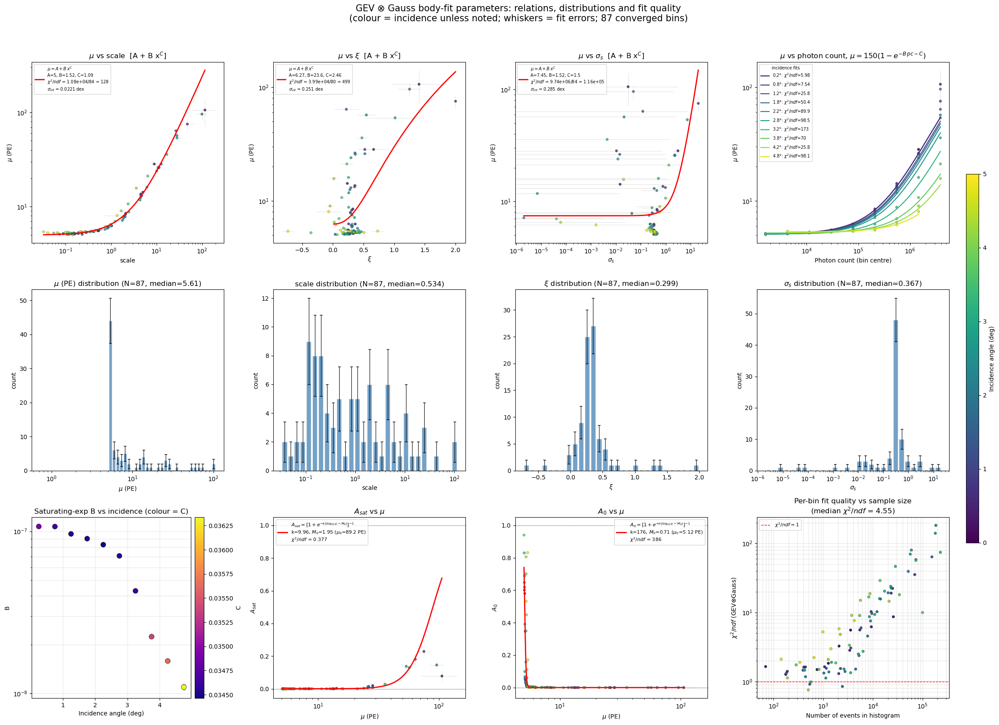


SUMMARY
mu(scale  ) = A + B*x^C : A=5.002±0.052, B=1.518±0.085, C=1.094±0.028 | chi2/ndf=128 (raw), sigma_int=0.0221 dex
mu(xi     ) = A + B*x^C : A=6.267±0.88, B=23.65±7.4, C=2.46±0.52 | chi2/ndf=499 (raw), sigma_int=0.251 dex
mu(sigma_s) = A + B*x^C : A=7.451±0.75, B=1.524±1.7, C=1.503±0.49 | chi2/ndf=1.16e+05 (raw), sigma_int=0.285 dex
mu(pc|inc) = 150(1-exp(-B pc - C)), 10 angles, median chi2/ndf = 60.2
A_sat(mu): k=9.958, M0=1.951 (mu_0=89.2 PE), chi2/ndf=0.377
A_0  (mu): k=175.7, M0=0.7096 (mu_0=5.12 PE), chi2/ndf=386


In [42]:
# GEV ⊗ Gauss body-fit parameters: 3 x 4 summary figure
#
#  Row 1: mu vs scale | mu vs xi | mu vs sigma_s | mu vs photon count
#         (offset power law  mu = A + B*x^C  per parameter, fitted in
#          log10(mu) with effective variance + intrinsic scatter;
#          saturating-exp fit per incidence angle for photon count)
#  Row 2: histograms of mu, scale, xi, sigma_s
#  Row 3: B vs incidence (colour = C) | A_sat vs mu | A_0 vs mu |
#         chi2/ndf vs n_events
#
#  All scatter points coloured by incidence angle; fits weighted with
#  effective variance  sigma_eff^2 = sigma_y^2 + (df/dx * sigma_x)^2
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.optimize import curve_fit, brentq
from scipy.stats import spearmanr

# ---------------------------------------------------------------------
# USER SETTINGS
# ---------------------------------------------------------------------
npz_file = "landau_gev_gauss_2d_fit_results_weighted.npz"

MU_MAX = 150.0          # saturation ceiling of mu(pc) = MU_MAX*(1-exp(-B*pc-C))

# model per parameter: "powerlaw" (mu = A + B*x^C) or None (no fit, show Spearman rho)
FIT_MODEL = {"scale": "powerlaw", "xi": "powerlaw", "sigma_s": "powerlaw"}
FIT_INTRINSIC = True    # solve for intrinsic scatter so chi2/ndf = 1

FRAC_USE_XERR = True   # A_sat/A_0 fits: False = script-2 method (y-errors only)
N_EFFVAR_ITER = 3       # iterations of effective-variance re-weighting

# ---------------------------------------------------------------------
# 1. Load
# ---------------------------------------------------------------------
data = np.load(npz_file, allow_pickle=True)

mu,  mu_err  = data["mu_gev"],    data["mu_gev_err"]
sc,  sc_err  = data["scale_gev"], data["scale_gev_err"]
xi,  xi_err  = data["xi_gev"],    data["xi_gev_err"]
sg,  sg_err  = data["sg_gev"],    data["sg_gev_err"]

efficiency = data["efficiency_gev"]
success    = data["success_gev"].astype(bool)
fracv      = data["frac_valid"].astype(bool)
chi2_red   = data["chi2_red_gev"]
n_events   = data["n_events"]

A_sat, A_sat_err = data["A_sat"], data["A_sat_err"]
A_0,   A_0_err   = data["A_0"],   data["A_0_err"]

N_I, N_PC = mu.shape
inc_edges = data["inc_edges"][:N_I + 1]
pc_edges  = data["pc_edges"][:N_PC + 1]

inc_c = 0.5 * (inc_edges[:-1] + inc_edges[1:])
pc_c  = np.sqrt(pc_edges[:-1] * pc_edges[1:])
INC, PC = np.meshgrid(inc_c, pc_c, indexing="ij")

# ---------------------------------------------------------------------
# 2. Base mask (script 1) -> flatten
# ---------------------------------------------------------------------
mask = success & fracv & np.isfinite(efficiency) & np.isfinite(chi2_red)# & (chi2_red <= 5)
for v, e in ((mu, mu_err), (sc, sc_err), (xi, xi_err), (sg, sg_err)):
    mask &= np.isfinite(v) & np.isfinite(e)
mask &= mu > 0          # needed for log axes / log10(mu)

f = lambda a: np.asarray(a)[mask].ravel()
MU, MU_E   = f(mu), f(mu_err)
SC, SC_E   = f(sc), f(sc_err)
XI, XI_E   = f(xi), f(xi_err)
SG, SG_E   = f(sg), f(sg_err)
INC_F, PC_F = f(INC), f(PC)
CHI2_F, NEV_F = f(chi2_red), f(n_events).astype(float)
ASAT, ASAT_E = f(A_sat), f(A_sat_err)
A0,   A0_E   = f(A_0),   f(A_0_err)
print(f"{MU.size} converged bins selected")

# Diagnostic: is mu pinned at a fit bound in the low-mu floor region?
if "at_bound_gev" in data.files:
    atb = np.asarray(data["at_bound_gev"])
    if atb.size == mu.size:
        # reshape to the 2D grid so the 2D mask applies, then flatten
        # (same ordering as the f() helper, so atb_m aligns with MU)
        atb_m = atb.reshape(mu.shape)[mask].ravel().astype(bool)
        floor_sel = MU < 7.0          # floor sits near ~5.3 PE
        nf = int(np.sum(floor_sel))
        nb = int(np.sum(floor_sel & atb_m))
        print(f"  [diagnostic] {nf}/{atb_m.size} selected bins have mu < 7.0 PE; "
              f"{nb} of those ({100 * nb / max(nf, 1):.1f}%) have "
              f"at_bound_gev set")
    else:
        print(f"  [diagnostic] skipped: at_bound_gev size {atb.size} "
              f"!= mu size {mu.size}")

def safe_err(err):
    """Replace non-positive / non-finite errors with the median positive error."""
    err = np.asarray(err, float).copy()
    good = np.isfinite(err) & (err > 0)
    fill = np.median(err[good]) if good.any() else 1.0
    err[~good] = fill
    return err

def floor_fraction_err(err, n):
    """Script-2 floor: zero fraction errors (k=0 bins) -> 1/n."""
    err = np.asarray(err, float).copy()
    bad = ~np.isfinite(err) | (err <= 0)
    err[bad] = 1.0 / np.maximum(np.asarray(n, float)[bad], 1.0)
    return err

MU_E_S = safe_err(MU_E)

# ---------------------------------------------------------------------
# 3. Generic effective-variance weighted fit
# ---------------------------------------------------------------------
def num_deriv(func, x, popt):
    h = 1e-5 * np.maximum(np.abs(x), 1e-3)
    return (func(x + h, *popt) - func(x - h, *popt)) / (2 * h)

def fit_effvar(func, x, y, xerr, yerr, p0, bounds=(-np.inf, np.inf),
               n_iter=N_EFFVAR_ITER, maxfev=100000):
    """Weighted fit; x-errors folded in via df/dx (iterated).
    Returns popt, perr, chi2, ndof, sigma_eff."""
    sig = np.asarray(yerr, float)
    popt, pcov = curve_fit(func, x, y, p0=p0, sigma=sig,
                           absolute_sigma=True, bounds=bounds, maxfev=maxfev)
    if xerr is not None:
        for _ in range(n_iter):
            dfdx = num_deriv(func, x, popt)
            sig = np.sqrt(yerr**2 + (dfdx * xerr)**2)
            sig = np.where(sig > 0, sig, np.min(yerr[yerr > 0]))
            popt, pcov = curve_fit(func, x, y, p0=popt, sigma=sig,
                                   absolute_sigma=True, bounds=bounds,
                                   maxfev=maxfev)
    perr = np.sqrt(np.diag(pcov))
    chi2 = np.sum(((y - func(x, *popt)) / sig) ** 2)
    ndof = len(x) - len(popt)
    return popt, perr, chi2, ndof, sig

# ---------------------------------------------------------------------
# 4. mu = f(param) : offset power law    mu = A + B*x^C
#    (same form as script 2's eta(MPV)).  Fitted in log10(mu) so low
#    and high mu count comparably, with effective variance from the
#    x-errors and an intrinsic scatter term solved so chi2/ndf = 1.
# ---------------------------------------------------------------------
def offset_power(x, A, B, C):
    return A + B * np.power(x, C)

def _log_model(x, A, B, C):
    return np.log10(offset_power(x, A, B, C))

def fit_offset_power(x, y, xerr, yerr, n_iter=6, fit_int=FIT_INTRINSIC):
    """Fit log10(mu) = log10(A + B x^C) with effective variance + intrinsic scatter."""
    xerr = np.where(np.isfinite(xerr), xerr, 0.0)
    m = (np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
         & np.isfinite(yerr) & (yerr > 0))
    x, y, xerr, yerr = x[m], y[m], xerr[m], yerr[m]
    if x.size < 5:
        return None

    ly  = np.log10(y)
    sly = yerr / (y * np.log(10))

    # starting values: floor from low-x points, slope from upper half (log-log)
    A0 = np.percentile(y, 5)
    hi = x > np.median(x)
    excess = np.clip(y[hi] - A0, 1e-3 * A0, None)
    C0, lnB = np.polyfit(np.log(x[hi]), np.log(excess), 1)
    C0 = float(np.clip(C0, 0.05, 5))
    popt = [A0, np.exp(lnB), C0]
    bounds = ([1e-6, 1e-12, 1e-3], [np.inf, np.inf, 10])

    sig_int, h = 0.0, 1e-4
    try:
        for _ in range(n_iter):
            dfdx = (_log_model(x * (1 + h), *popt)
                    - _log_model(x * (1 - h), *popt)) / (2 * h * x)
            base = sly**2 + (dfdx * xerr)**2
            popt, pcov = curve_fit(_log_model, x, ly, p0=popt,
                                   sigma=np.sqrt(base + sig_int**2),
                                   absolute_sigma=True, bounds=bounds,
                                   maxfev=50000)
            r2   = (ly - _log_model(x, *popt))**2
            ndof = x.size - 3
            if fit_int:
                g = lambda s: np.sum(r2 / (base + s**2)) - ndof
                sig_int = brentq(g, 0.0, 10.0) if g(0.0) > 0 else 0.0
    except Exception as e:
        print("  power-law fit failed:", e)
        return None

    chi2_raw = np.sum(r2 / base)
    chi2_int = np.sum(r2 / (base + sig_int**2))
    perr = np.sqrt(np.diag(pcov))
    return dict(popt=popt, perr=perr, ndof=ndof, sig_int=sig_int,
                chi2=chi2_raw, chi2r=chi2_raw / ndof, chi2r_int=chi2_int / ndof,
                xmin=x.min(), xmax=x.max())

param_cfg = [   # (key, values, errors, label)
    ("scale",   SC, SC_E, "scale"),
    ("xi",      XI, XI_E, r"$\xi$"),
    ("sigma_s", SG, SG_E, r"$\sigma_s$"),
]

sig_fits = {}
print("\nOffset power-law fits  mu = A + B*x^C   (fitted in log10(mu))")
for key, xv, xe, lab in param_cfg:
    model = FIT_MODEL.get(key)
    res = fit_offset_power(xv, MU, xe, MU_E_S) if model == "powerlaw" else None
    sig_fits[key] = res
    if res is None:
        print(f"  {key:8s}: no fit (model = {model})"); continue
    A, B, C = res["popt"]; dA, dB, dC = res["perr"]
    print(f"  {key:8s}: A={A:.4g}+/-{dA:.2g}, B={B:.4g}+/-{dB:.2g}, "
          f"C={C:.4g}+/-{dC:.2g} | chi2/ndf={res['chi2r']:.3g} "
          f"(raw), sigma_int={res['sig_int']:.3g} dex")

# ---------------------------------------------------------------------
# 5. mu = MU_MAX*(1 - exp(-B pc - C)) per incidence angle
# ---------------------------------------------------------------------
def saturating_exp(pc, B, C):
    return MU_MAX * (1.0 - np.exp(-B * pc - C))

sat_res = []   # list of dicts
print(f"\nmu = {MU_MAX:g}*(1 - exp(-B*pc - C)) per incidence angle")
for inc_val in np.unique(INC_F):
    m = INC_F == inc_val
    if m.sum() < 3:
        continue
    o = np.argsort(PC_F[m])
    pc_i, mu_i, e_i = PC_F[m][o], MU[m][o], MU_E_S[m][o]
    try:
        popt, perr, chi2, ndof, _ = fit_effvar(
            saturating_exp, pc_i, mu_i, None, e_i,
            p0=[1.0 / np.median(pc_i), 0.0], bounds=([0, 0], [1, 1]))
        chi2r = chi2 / ndof if ndof > 0 else np.nan
        sat_res.append(dict(inc=inc_val, B=popt[0], C=popt[1],
                            B_err=perr[0], C_err=perr[1], chi2r=chi2r,
                            pcmin=pc_i.min(), pcmax=pc_i.max()))
        print(f"  inc={inc_val:6.2f}: B={popt[0]:.3e}+/-{perr[0]:.1e}, "
              f"C={popt[1]:.3e}+/-{perr[1]:.1e}, chi2/ndf={chi2r:.3g}")
    except Exception as e:
        print(f"  inc={inc_val:6.2f}: fit failed ({e})")

# ---------------------------------------------------------------------
# 6. A_sat / A_0 vs mu  (script-2 method; x = log10(mu), asymptotes 0/1)
# ---------------------------------------------------------------------
def sigmoid_rise(mu_val, k, M0):
    return 1.0 / (1.0 + np.exp(np.clip(-k * (np.log10(mu_val) - M0), -500, 500)))

def sigmoid_fall(mu_val, k, M0):
    return 1.0 / (1.0 + np.exp(np.clip(+k * (np.log10(mu_val) - M0), -500, 500)))

def fit_frac_sigmoid(func, x, xerr, y, yerr, label):
    sel = np.isfinite(x) & np.isfinite(y) & (x > 0)
    x, xerr, y, yerr = x[sel], xerr[sel], y[sel], yerr[sel]
    if len(x) < 4:
        print(f"\n{label}: not enough points"); return None
    o = np.argsort(x)
    lx, ys = np.log10(x[o]), y[o]
    cross = np.where(np.diff(np.sign(ys - 0.5)) != 0)[0]
    M0_guess = lx[cross[0]] if len(cross) else 0.5 * (lx.min() + lx.max())
    k_guess = 10.0 / max(np.ptp(lx), 1e-12)
    try:
        popt, perr, chi2, ndof, _ = fit_effvar(
            func, x, y, xerr if FRAC_USE_XERR else None, yerr,
            p0=[k_guess, M0_guess], bounds=([1e-12, -np.inf], [np.inf, np.inf]))
    except Exception as e:
        print(f"\n{label}: fit failed ({e})"); return None
    chi2r = chi2 / ndof if ndof > 0 else np.nan
    print(f"\n{label}: k={popt[0]:.4g}+/-{perr[0]:.3g}, "
          f"M0={popt[1]:.4g}+/-{perr[1]:.3g} (mu_0={10**popt[1]:.3g} PE), "
          f"chi2/ndf={chi2:.4g}/{ndof}={chi2r:.4g}")
    return dict(popt=popt, perr=perr, chi2r=chi2r)

m_sat = np.isfinite(ASAT) & np.isfinite(NEV_F)
m_a0  = np.isfinite(A0)   & np.isfinite(NEV_F)
ASAT_E_FIT = floor_fraction_err(ASAT_E, NEV_F)
A0_E_FIT   = floor_fraction_err(A0_E,   NEV_F)

fit_sat = fit_frac_sigmoid(sigmoid_rise, MU[m_sat], MU_E_S[m_sat],
                           ASAT[m_sat], ASAT_E_FIT[m_sat], "A_sat vs mu (rising)")
fit_a0  = fit_frac_sigmoid(sigmoid_fall, MU[m_a0], MU_E_S[m_a0],
                           A0[m_a0], A0_E_FIT[m_a0], "A_0 vs mu (falling)")

# ---------------------------------------------------------------------
# 7. Figure 3 x 4
# ---------------------------------------------------------------------
cmap = plt.get_cmap("viridis")
norm = Normalize(vmin=inc_edges[0], vmax=inc_edges[-1])
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

fig, axes = plt.subplots(3, 4, figsize=(24, 17))

def err_scatter(ax, x, y, xerr, yerr, c):
    ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt="none", ecolor="lightgray",
                elinewidth=0.5, capsize=0, zorder=1)
    ax.scatter(x, y, c=c, cmap=cmap, norm=norm, s=18, alpha=0.8,
               edgecolors="k", linewidths=0.2, zorder=2)

# ---- Row 1, cols 0-2: mu vs scale / xi / sigma_s ----
for j, (key, xv, xe, lab) in enumerate(param_cfg):
    ax = axes[0, j]
    err_scatter(ax, xv, MU, xe, MU_E, INC_F)

    res = sig_fits.get(key)

    if res is not None:
        A, B, C = res["popt"]
        xs = np.logspace(np.log10(res["xmin"]), np.log10(res["xmax"]), 300)
        ax.plot(xs, offset_power(xs, A, B, C), "r-", lw=2, zorder=3,
                label=(rf"$\mu = A + B\,x^{{C}}$" "\n"
                       rf"A={A:.3g}, B={B:.3g}, C={C:.3g}" "\n"
                       rf"$\chi^2/ndf$ = {res['chi2']:.3g}/{res['ndof']} = {res['chi2r']:.3g}" "\n"
                       rf"$\sigma_{{int}}$ = {res['sig_int']:.3g} dex"))
        ax.legend(fontsize=7, loc="upper left")
    else:
        xm = np.isfinite(xv) & np.isfinite(MU)
        rho, pval = spearmanr(xv[xm], MU[xm])
        ax.text(0.03, 0.97, f"no fit\nSpearman ρ = {rho:+.2f} (p={pval:.1g})",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(boxstyle="round", fc="white", alpha=0.8))
    if key != "xi":
        ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(lab)
    ax.set_ylabel(r"$\mu$ (PE)")
    ax.set_title(rf"$\mu$ vs {lab}" + ("  [A + B x$^C$]" if res else ""))

# ---- Row 1, col 3: mu vs photon count + per-incidence fits ----
ax = axes[0, 3]
ax.errorbar(PC_F, MU, yerr=MU_E, fmt="none", ecolor="lightgray",
            elinewidth=0.5, capsize=0, zorder=1)
ax.scatter(PC_F, MU, c=INC_F, cmap=cmap, norm=norm, s=18, alpha=0.8,
           edgecolors="k", linewidths=0.2, zorder=2)
for r in sat_res:
    pc_d = np.logspace(np.log10(r["pcmin"]), np.log10(r["pcmax"]), 200)
    ax.plot(pc_d, saturating_exp(pc_d, r["B"], r["C"]), "-",
            color=cmap(norm(r["inc"])), lw=1.6, zorder=3,
            label=rf"{r['inc']:.1f}°: $\chi^2/ndf$={r['chi2r']:.3g}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Photon count (bin centre)")
ax.set_ylabel(r"$\mu$ (PE)")
ax.set_title(rf"$\mu$ vs photon count, $\mu={MU_MAX:g}(1-e^{{-B\,pc-C}})$")
if sat_res:
    ax.legend(fontsize=7, ncol=1 if len(sat_res) <= 10 else 2,
              loc="upper left", framealpha=0.8, title="incidence fits",
              title_fontsize=7)

# ---- Row 2: histograms ----
hist_cfg = [(MU, r"$\mu$ (PE)", True), (SC, "scale", True),
            (XI, r"$\xi$", False), (SG, r"$\sigma_s$", True)]
for j, (vals, lab, logx) in enumerate(hist_cfg):
    ax = axes[1, j]
    vals = vals[np.isfinite(vals)]
    if logx:
        vals = vals[vals > 0]
        edges = np.logspace(np.log10(vals.min()), np.log10(vals.max()), 30)
        ax.set_xscale("log")
        centers = np.sqrt(edges[:-1] * edges[1:])
    else:
        edges = np.linspace(vals.min(), vals.max(), 30)
        centers = 0.5 * (edges[:-1] + edges[1:])
    counts, _ = np.histogram(vals, bins=edges)
    ax.bar(centers, counts, width=np.diff(edges) * 0.8, color="steelblue",
           alpha=0.75, edgecolor="white", yerr=np.sqrt(counts),
           error_kw=dict(ecolor="k", elinewidth=0.8, capsize=2))
    ax.set_xlabel(lab); ax.set_ylabel("count")
    ax.set_title(f"{lab} distribution (N={vals.size}, median={np.median(vals):.3g})")

# ---- Row 3, col 0: B vs incidence, colour = C ----
ax = axes[2, 0]
if sat_res:
    inc_a = np.array([r["inc"] for r in sat_res])
    B_a   = np.array([r["B"] for r in sat_res])
    Be_a  = np.array([r["B_err"] for r in sat_res])
    C_a   = np.array([r["C"] for r in sat_res])
    ax.errorbar(inc_a, B_a, yerr=Be_a, fmt="none", ecolor="gray",
                elinewidth=1, capsize=3, alpha=0.6, zorder=2)
    s_bc = ax.scatter(inc_a, B_a, c=C_a, cmap="plasma", s=70,
                      edgecolor="k", linewidth=0.5, zorder=3)
    fig.colorbar(s_bc, ax=ax, pad=0.02).set_label("C")
    ax.set_yscale("log")
else:
    ax.text(0.5, 0.5, "no saturating-exp fits", ha="center", va="center",
            transform=ax.transAxes)
ax.set_xlabel("Incidence angle (deg)")
ax.set_ylabel("B")
ax.set_title("Saturating-exp B vs incidence (colour = C)")
ax.grid(alpha=0.3, which="both")

# ---- Row 3, cols 1-2: A_sat / A_0 vs mu ----
for ax, m, y, ye, res, func, name, sgn, loc in (
        (axes[2, 1], m_sat, ASAT, ASAT_E_FIT, fit_sat, sigmoid_rise,
         r"A_{sat}", "-", "upper left"),
        (axes[2, 2], m_a0, A0, A0_E_FIT, fit_a0, sigmoid_fall,
         r"A_0", "+", "upper right")):
    err_scatter(ax, MU[m], y[m], MU_E[m], ye[m], INC_F[m])
    if res is not None:
        mu_d = np.logspace(np.log10(MU[m].min()), np.log10(MU[m].max()), 400)
        k, M0 = res["popt"]
        ax.plot(mu_d, func(mu_d, k, M0), "r-", lw=2, zorder=3,
                label=(rf"${name}=[1+e^{{{sgn}k(\log_{{10}}\mu-M_0)}}]^{{-1}}$" "\n"
                       f"k={k:.3g}, $M_0$={M0:.3g} ($\\mu_0$={10**M0:.3g} PE)\n"
                       rf"$\chi^2/ndf$ = {res['chi2r']:.3g}"))
        ax.legend(fontsize=8, loc=loc)
    ax.axhline(0, color="k", lw=0.8, ls=":"); ax.axhline(1, color="k", lw=0.8, ls=":")
    ax.set_xscale("log")#; ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel(r"$\mu$ (PE)"); ax.set_ylabel(rf"${name}$")
    ax.set_title(rf"${name}$ vs $\mu$")

# ---- Row 3, col 3: chi2/ndf vs n_events ----
ax = axes[2, 3]
mc = np.isfinite(CHI2_F) & (CHI2_F > 0) & (NEV_F > 0)
ax.scatter(NEV_F[mc], CHI2_F[mc], c=INC_F[mc], cmap=cmap, norm=norm, s=20,
           edgecolors="k", linewidths=0.2)
ax.axhline(1.0, color="r", ls="--", lw=1, label=r"$\chi^2/ndf = 1$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Number of events in histogram")
ax.set_ylabel(r"$\chi^2/ndf$ (GEV$\otimes$Gauss)")
ax.set_title("Per-bin fit quality vs sample size\n"
             rf"(median $\chi^2/ndf$ = {np.median(CHI2_F[mc]):.3g})")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")

# ---- shared incidence colourbar ----
cax = fig.add_axes([0.93, 0.25, 0.012, 0.5])
fig.colorbar(sm, cax=cax).set_label("Incidence angle (deg)")

fig.suptitle("GEV ⊗ Gauss body-fit parameters: relations, distributions and fit quality\n"
             f"(colour = incidence unless noted; whiskers = fit errors; "
             f"{MU.size} converged bins)", fontsize=15)
plt.tight_layout(rect=[0, 0, 0.92, 0.96])
plt.show()

# ---------------------------------------------------------------------
# 8. Summary
# ---------------------------------------------------------------------
print("\n" + "=" * 64)
print("SUMMARY")
print("=" * 64)
for key, res in sig_fits.items():
    if res is not None:
        A, B, C = res["popt"]; dA, dB, dC = res["perr"]
        print(f"mu({key:7s}) = A + B*x^C : A={A:.4g}±{dA:.2g}, B={B:.4g}±{dB:.2g}, "
              f"C={C:.4g}±{dC:.2g} | chi2/ndf={res['chi2r']:.3g} "
              f"(raw), sigma_int={res['sig_int']:.3g} dex")
if sat_res:
    print(f"mu(pc|inc) = {MU_MAX:g}(1-exp(-B pc - C)), {len(sat_res)} angles, "
          f"median chi2/ndf = {np.nanmedian([r['chi2r'] for r in sat_res]):.3g}")
for name, res in (("A_sat", fit_sat), ("A_0", fit_a0)):
    if res is not None:
        print(f"{name:5s}(mu): k={res['popt'][0]:.4g}, M0={res['popt'][1]:.4g} "
              f"(mu_0={10**res['popt'][1]:.3g} PE), chi2/ndf={res['chi2r']:.3g}")
print("=" * 64)


Keys in file: ['inc_edges', 'pc_edges', 'bin_edges_pe', 'xmin_cut', 'xmax_cut', 'mpv', 'eta', 'sigma', 'A', 'A_0', 'A_sat', 'mpv_err', 'eta_err', 'sigma_err', 'A_err', 'A_0_err', 'A_sat_err', 'chi2', 'ndof', 'chi2_red', 'efficiency', 'efficiency_err', 'efficiency_data', 'efficiency_data_err', 'nll', 'mu_gev', 'scale_gev', 'xi_gev', 'sg_gev', 'mu_gev_err', 'scale_gev_err', 'xi_gev_err', 'sg_gev_err', 'chi2_gev', 'ndof_gev', 'chi2_red_gev', 'nll_gev', 'efficiency_gev', 'efficiency_gev_err', 'delta_nll', 'n_events', 'n_body', 'k_0', 'k_mid', 'k_sat', 'n_total', 'success', 'frac_valid', 'at_bound', 'success_gev', 'at_bound_gev', 'cov', 'cov_gev']


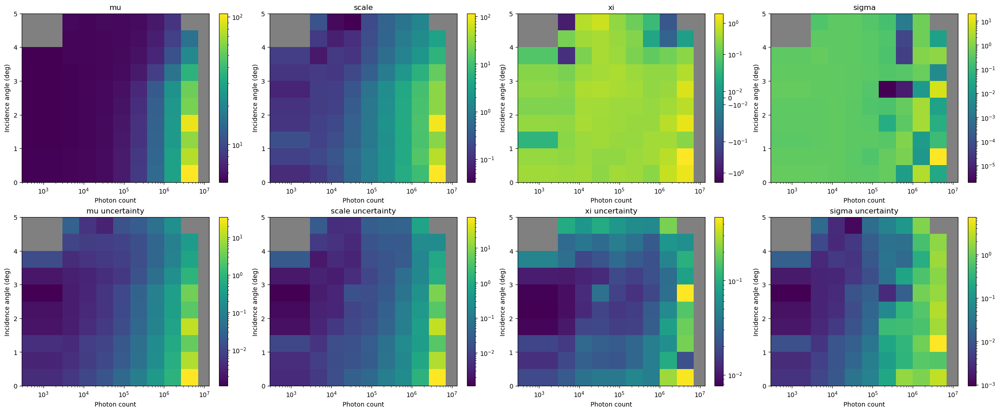

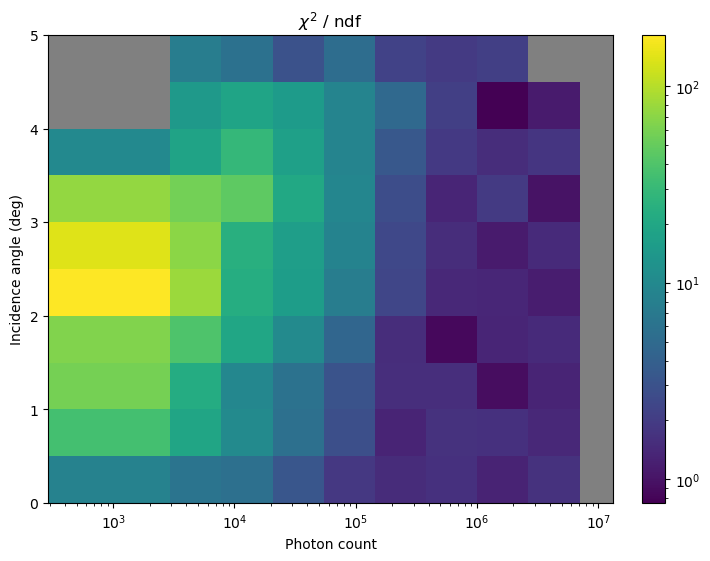

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, SymLogNorm

npz_file = "landau_gev_gauss_2d_fit_results_weighted.npz"
out_params = "gev_gauss_params_heatmap.png"
out_chi2 = "gev_gauss_chi2_heatmap.png"

d = np.load(npz_file, allow_pickle=True)
print("Keys in file:", list(d.keys()))

# ---- Adjust here if your key names differ ----
KEYS = {
    "inc_edges": "inc_edges",      # incidence angle bin edges (deg)
    "pc_edges":  "pc_edges",       # photon count bin edges
    "params": [("mu_gev", "mu"), ("scale_gev", "scale"),
               ("xi_gev", "xi"), ("sg_gev", "sigma")],
    "err_suffix": "_err",
    "chi2red": "chi2_red_gev",
    "success": "success_gev",      # set to None if absent
}
# ----------------------------------------------

inc_edges = np.asarray(d[KEYS["inc_edges"]], float)
pc_edges = np.asarray(d[KEYS["pc_edges"]], float)

# Bin centres (photon count: geometric centre, since axis is log)
inc_c = 0.5 * (inc_edges[:-1] + inc_edges[1:])
pc_c = np.sqrt(pc_edges[:-1] * pc_edges[1:])

# Expected array layout: (n_inc, n_pc). Transposed automatically if needed.
def orient(a):
    a = np.asarray(a, float)
    if a.shape == (len(inc_c), len(pc_c)):
        return a
    if a.shape == (len(pc_c), len(inc_c)):
        return a.T
    raise ValueError(f"Unexpected shape {a.shape}, expected "
                     f"{(len(inc_c), len(pc_c))}")

ok = np.ones((len(inc_c), len(pc_c)), bool)
if KEYS["success"] and KEYS["success"] in d:
    ok = orient(d[KEYS["success"]]).astype(bool)

def make_norm(vals):
    """Log by default; symlog if any valid value is <= 0."""
    v = vals[np.isfinite(vals)]
    if v.size == 0:
        return None
    if np.any(v <= 0):
        absv = np.abs(v[v != 0])
        linthresh = np.percentile(absv, 5) if absv.size else 1.0
        vmax = np.max(np.abs(v))
        return SymLogNorm(linthresh=linthresh, vmin=-vmax, vmax=vmax, base=10)
    return LogNorm(vmin=v.min(), vmax=v.max())

def draw(ax, data, title, cmap):
    data = data.copy()
    data[~ok] = np.nan
    data[~np.isfinite(data)] = np.nan
    masked = np.ma.masked_invalid(data)
    norm = make_norm(data)
    cmap = plt.get_cmap(cmap).copy()
    cmap.set_bad("gray")
    ax.set_facecolor("gray")
    m = ax.pcolormesh(pc_c, inc_c, masked, cmap=cmap, norm=norm, shading="nearest")
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Photon count")
    ax.set_ylabel("Incidence angle (deg)")
    plt.colorbar(m, ax=ax)

cmap = "viridis"

# ---------- Figure 1: parameters (row 1) and uncertainties (row 2) ----------
fig, axes = plt.subplots(2, 4, figsize=(22, 9), constrained_layout=True)
for j, (key, label) in enumerate(KEYS["params"]):
    val = orient(d[key])
    err = orient(d[key + KEYS["err_suffix"]])
    err = np.where(err > 0, err, np.nan)   # non-positive errors -> gray
    draw(axes[0, j], val, label, cmap)
    draw(axes[1, j], err, f"{label} uncertainty", cmap)
fig.savefig(out_params, dpi=300)

# ---------- Figure 2: chi2 / ndf ----------
chi2 = orient(d[KEYS["chi2red"]])
chi2 = np.where(chi2 > 0, chi2, np.nan)
fig2, ax2 = plt.subplots(figsize=(7, 5.5), constrained_layout=True)
draw(ax2, chi2, r"$\chi^2$ / ndf", cmap)
fig2.savefig(out_chi2, dpi=300)

plt.show()

In [44]:
# Complete Model (loads precomputed fit results, no recomputation)
import numpy as np
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import plotly.io as pio
pio.renderers.default = "notebook"
npz_file = "landau_gev_gauss_2d_fit_results_weighted.npz"

def mpl_to_plotly_colorscale(name, n=256):
    cmap = plt.get_cmap(name)
    return [[i / (n - 1), to_hex(cmap(i / (n - 1)))] for i in range(n)]

terrain_pl = mpl_to_plotly_colorscale("terrain")

# =========================================================
# CONFIG
# =========================================================
PE_THRESHOLD = 20.0
N_MIN_TRIG   = 1
LINTHRESH    = 1e-10

# =========================================================
# 1. Load precomputed fit results
# =========================================================
data = np.load(npz_file, allow_pickle=True)

inc_edges = data["inc_edges"]
pc_edges  = data["pc_edges"]

n_events   = data["n_events"]
frac_valid = data["frac_valid"]
n_body     = data["n_body"]

A          = data["A"]
A_err      = data["A_err"]
A_0        = data["A_0"]
A_0_err    = data["A_0_err"]
A_sat      = data["A_sat"]
A_sat_err  = data["A_sat_err"]
k_0        = data["k_0"]
k_mid      = data["k_mid"]
k_sat      = data["k_sat"]
n_total    = data["n_total"]

efficiency_data     = data["efficiency_data"]
efficiency_data_err = data["efficiency_data_err"]

# --- GEV ⊗ Gauss per-bin model (replaces Landau-Gauss) ---
success_gev     = data["success_gev"]
mu_gev          = data["mu_gev"]
scale_gev       = data["scale_gev"]
xi_gev          = data["xi_gev"]
sg_gev          = data["sg_gev"]
mu_gev_err      = data["mu_gev_err"]
scale_gev_err   = data["scale_gev_err"]
xi_gev_err      = data["xi_gev_err"]
sg_gev_err      = data["sg_gev_err"]

chi2_red_gev    = data["chi2_red_gev"]
nll_gev         = data["nll_gev"]

efficiency_gev     = data["efficiency_gev"]
efficiency_gev_err = data["efficiency_gev_err"]

cov_gev = data["cov_gev"]

N_I, N_PC_ACTUAL = mu_gev.shape

# =========================================================
# 2. Provenance: data-driven vs. per-bin model
# =========================================================
with np.errstate(invalid="ignore"):
    n_trig_equiv = efficiency_data * n_total

use_data   = (n_trig_equiv >= N_MIN_TRIG) & frac_valid & np.isfinite(efficiency_data)
use_perbin = (~use_data) & success_gev & frac_valid & np.isfinite(efficiency_gev)

eff_hybrid = np.full((N_I, N_PC_ACTUAL), np.nan)
eff_hybrid[use_data]   = efficiency_data[use_data]
eff_hybrid[use_perbin] = efficiency_gev[use_perbin]
eff_hybrid = np.clip(eff_hybrid, 0.0, 1.0)

provenance = np.zeros((N_I, N_PC_ACTUAL), dtype=int)
provenance[use_data]   = 1
provenance[use_perbin] = 2

print(f"\nTier 1 (data, n_total >= {N_MIN_TRIG}) : {use_data.sum()}")
print(f"Tier 2 (per-bin GEV⊗Gauss fit)   : {use_perbin.sum()}")
print(f"No estimate                        : {(provenance == 0).sum()}")
print(f"Total bins                         : {N_I * N_PC_ACTUAL}")

# =========================================================
# 3. Blocky (exact) boundaries between provenance regions
# =========================================================
def staircase_segments(mask):
    xs, ys = [], []

    def add(x0, y0, x1, y1):
        xs.extend([x0, x1, None])
        ys.extend([y0, y1, None])

    ni, nj = mask.shape
    for i in range(ni):
        for j in range(nj):
            if not mask[i, j]:
                continue
            x_l, x_r = pc_edges[j], pc_edges[j + 1]
            y_b, y_t = inc_edges[i], inc_edges[i + 1]
            if j == 0      or not mask[i, j - 1]: add(x_l, y_b, x_l, y_t)
            if j == nj - 1 or not mask[i, j + 1]: add(x_r, y_b, x_r, y_t)
            if i == 0      or not mask[i - 1, j]: add(x_l, y_b, x_r, y_b)
            if i == ni - 1 or not mask[i + 1, j]: add(x_l, y_t, x_r, y_t)
    return xs, ys

x_data_b,   y_data_b   = staircase_segments(use_data)
x_perbin_b, y_perbin_b = staircase_segments(use_perbin)   # GEV⊗Gauss model boundary

# =========================================================
# 4. Symlog transform for the colour scale
# =========================================================
def symlog_fwd(v, lt=LINTHRESH):
    v = np.asarray(v, dtype=float)
    return np.sign(v) * np.log10(1.0 + np.abs(v) / lt)

z_sym = symlog_fwd(eff_hybrid)
z_min, z_max = 0.0, symlog_fwd(1.0)

tick_vals_eff = [0.0, 1e-4, 1e-3, 1e-2, 0.1, 0.3, 0.5, 1.0]
tick_pos  = [float(symlog_fwd(v)) for v in tick_vals_eff]
tick_text = ["0" if v == 0 else (f"{v:g}" if v >= 0.01 else f"{v:.0e}")
             for v in tick_vals_eff]

# =========================================================
# 5. Hover text
# =========================================================
prov_name = {0: "no estimate", 1: "DATA", 2: "per-bin GEV⊗Gauss fit"}

customdata = np.empty((N_I, N_PC_ACTUAL), dtype=object)
for i in range(N_I):
    for j in range(N_PC_ACTUAL):
        e = eff_hybrid[i, j]
        p = provenance[i, j]
        lines = [
            f"<b>eff = {e:.2e}</b>" if np.isfinite(e) else "<b>eff = n/a</b>",
            f"source: {prov_name[p]}",
            f"inc: [{inc_edges[i]:.3g}, {inc_edges[i+1]:.3g}] deg",
            f"pc:  [{pc_edges[j]:.3g}, {pc_edges[j+1]:.3g}]",
            f"n_events = {int(n_events[i, j])}, n_trigger = {n_total[i, j]*efficiency_data[i,j]:.3g}",
        ]
        if p == 1 and np.isfinite(efficiency_data_err[i, j]):
            lines.append(f"stat err = ±{efficiency_data_err[i, j]:.2e}")
        if p == 2:
            lines.append(f"GEV params: mu={mu_gev[i,j]:.4g}, scale={scale_gev[i,j]:.4g}, "
                         f"xi={xi_gev[i,j]:.4g}, sg={sg_gev[i,j]:.4g}")
            lines.append(f"A={A[i,j]:.4g}, A_0={A_0[i,j]:.4g}, "
                         f"A_sat={A_sat[i,j]:.4g}")
            if np.isfinite(efficiency_gev_err[i, j]):
                lines.append(f"model stat err = ±{efficiency_gev_err[i,j]:.2e}")
            lines.append(f"chi2_red = {chi2_red_gev[i,j]:.3g}")
        if np.isfinite(efficiency_gev[i, j]) and p == 1:
            lines.append(f"(per-bin model would give {efficiency_gev[i,j]:.2e})")
        customdata[i, j] = "<br>".join(lines)

# =========================================================
# 6. Plot
# =========================================================
fig = go.Figure()

fig.add_trace(go.Heatmap(
    x=pc_edges, y=inc_edges, z=z_sym,
    customdata=customdata,
    hovertemplate="%{customdata}<extra></extra>",
    colorscale="plasma",
    zmin=z_min, zmax=z_max,
    colorbar=dict(
        title=dict(text=f"Efficiency<br>(Max_PE ≥ {PE_THRESHOLD:.0f})", side="right"),
        tickmode="array", tickvals=tick_pos, ticktext=tick_text,
        len=0.9,
    ),
    hoverongaps=False,
    name="efficiency",
))

fig.add_trace(go.Scatter(
    x=x_data_b, y=y_data_b, mode="lines",
    line=dict(color="crimson", width=2.5),
    name=f"data region (n_total ≥ {N_MIN_TRIG})",
    hoverinfo="skip",
))

fig.add_trace(go.Scatter(                                  # GEV⊗Gauss model region
    x=x_perbin_b, y=y_perbin_b, mode="lines",
    line=dict(color="black", width=2.0, dash="dash"),
    name="per-bin GEV⊗Gauss region",
    hoverinfo="skip",
))

fig.update_xaxes(type="log", title_text="Photon Count",
                 range=[np.log10(pc_edges[0]), np.log10(pc_edges[-1])])
fig.update_yaxes(title_text="Incidence (deg)",
                 range=[inc_edges[0], inc_edges[-1]])

fig.update_layout(
    title=(f"Hybrid Trigger Efficiency (Max_PE ≥ {PE_THRESHOLD:.0f})<br>"
           f"<sup>data where n_total ≥ {N_MIN_TRIG}; per-bin GEV⊗Gauss fit otherwise. "
           f"symlog colour, linthresh={LINTHRESH:g}</sup>"),
    width=1100, height=700,
    template="plotly_white",
    legend=dict(orientation="h", yanchor="bottom", y=1.02,
                xanchor="right", x=1.0),
)

fig.show()

# =========================================================
# 7. Cross-check in the overlap region
# =========================================================
both = use_data & np.isfinite(efficiency_gev) & (efficiency_data > 0)
if both.sum():
    r = (efficiency_gev[both] - efficiency_data[both]) / efficiency_data[both]
    print(f"\nOverlap check ({both.sum()} bins where data is used and a "
          f"GEV⊗Gauss model also exists):")
    print(f"  median (model-data)/data = {np.median(r):+.4g}")
    print(f"  16-84 pct               = [{np.percentile(r,16):+.4g}, "
          f"{np.percentile(r,84):+.4g}]")
else:
    print("\nNo overlap bins available for a model-vs-data cross-check.")



Tier 1 (data, n_total >= 1) : 50
Tier 2 (per-bin GEV⊗Gauss fit)   : 48
No estimate                        : 2
Total bins                         : 100



Overlap check (39 bins where data is used and a GEV⊗Gauss model also exists):
  median (model-data)/data = -0.006535
  16-84 pct               = [-0.09681, +0.2476]


Model efficiency loaded for 87 / 100 bins


Data efficiency computed for 100 / 100 bins (nonzero count bins)


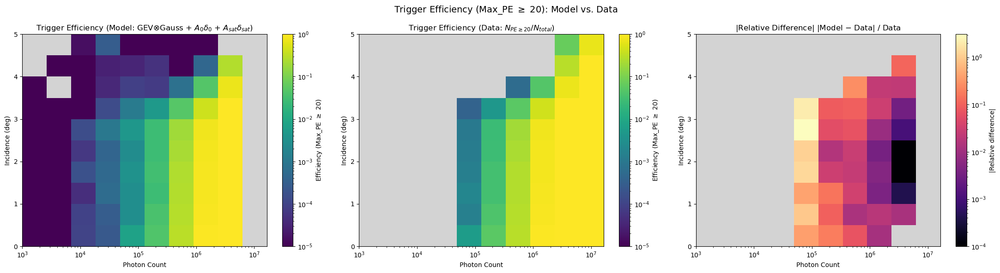


Median |relative difference| = 0.03035
Bins compared: 39 / 100
Pull computed for 85 / 100 bins
Mean pull = 1.360, median = 0.839, RMS = 2.211
Fraction |pull| > 3: 0.130


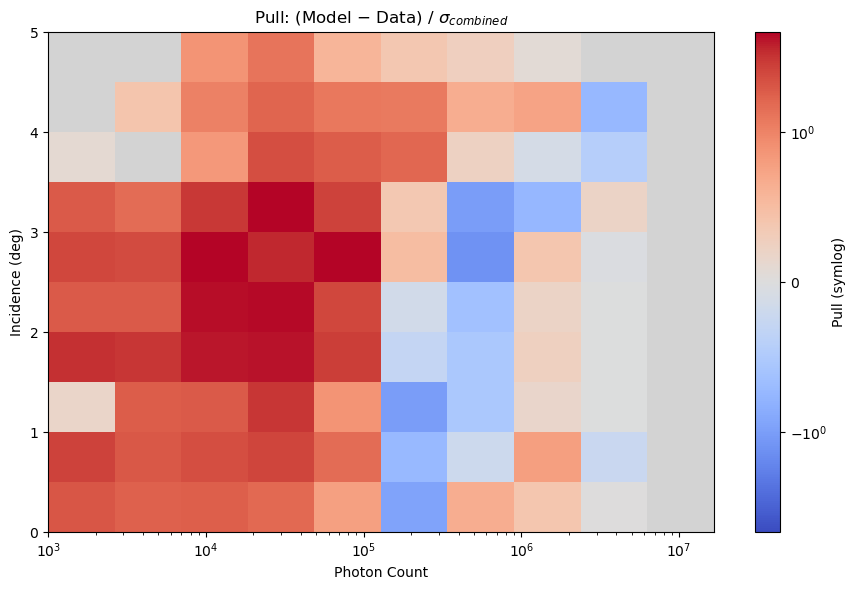

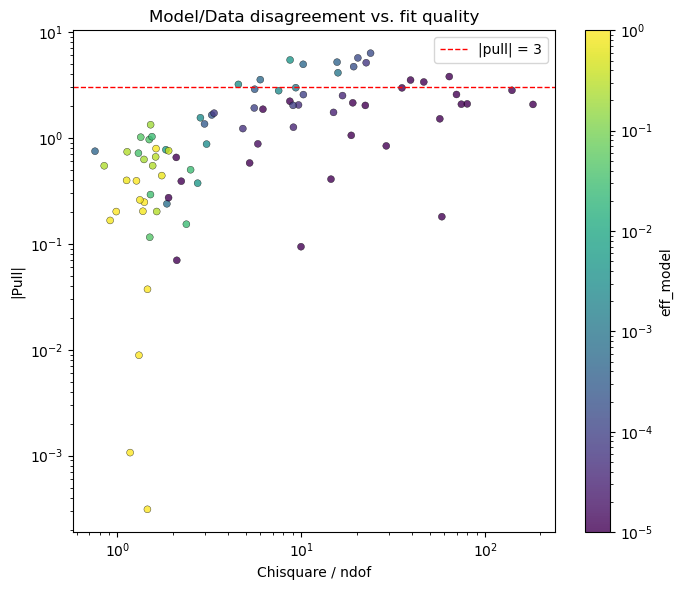

Correlation coefficient (log Deviance/ndof vs log|pull|): nan


/tmp/ipykernel_1570908/2347947771.py:256: RuntimeWarning: divide by zero encountered in log10
  r = np.corrcoef(np.log10(x), np.log10(y))[0, 1]
/uufs/chpc.utah.edu/common/home/u1520754/miniconda3/envs/landau310/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]


In [45]:
# Compare Data and Model (GEV ⊗ Gauss):
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
print_data = False
npz_file = "landau_gev_gauss_2d_fit_results_weighted.npz"
# ---------------------------------------------------------
# 1. Load fit results (efficiency loaded directly, not recomputed)
# ---------------------------------------------------------
data = np.load(npz_file, allow_pickle=True)

mu_gev       = data["mu_gev"]
scale_gev    = data["scale_gev"]
xi_gev       = data["xi_gev"]
sg_gev       = data["sg_gev"]
A            = data["A"]
A_0          = data["A_0"]
A_sat        = data["A_sat"]
n_events     = data["n_events"]
success_gev  = data["success_gev"]
frac_valid   = data["frac_valid"]

efficiency_gev     = data["efficiency_gev"]
efficiency_gev_err = data["efficiency_gev_err"]

inc_edges = data["inc_edges"]
pc_edges  = data["pc_edges"]

N_I, N_PC_ACTUAL = mu_gev.shape

PE_THRESHOLD = 20.0

# ---------------------------------------------------------
# 2. Model trigger efficiency -- loaded from npz
# ---------------------------------------------------------
eff_model     = np.array(efficiency_gev, dtype=float)
eff_model_err = np.array(efficiency_gev_err, dtype=float)

valid_model = success_gev & frac_valid & np.isfinite(eff_model)
eff_model     = np.where(valid_model, eff_model, np.nan)
eff_model_err = np.where(valid_model, eff_model_err, np.nan)
eff_model     = np.clip(eff_model, 0.0, 1.0)

print(f"Model efficiency loaded for {np.isfinite(eff_model).sum()} / "
      f"{N_I*N_PC_ACTUAL} bins")


# ---------------------------------------------------------
# 3. Data trigger efficiency -- vectorized with histogram2d
#    (two passes over the data instead of 600 masked passes)
# ---------------------------------------------------------
mask2d_eff = (
    np.isfinite(Max_PE) & np.isfinite(photon_count) & np.isfinite(Incidence)
    & (photon_count >= pc_edges[0]) & (photon_count <= pc_edges[-1])
    & (Incidence >= inc_edges[0]) & (Incidence <= inc_edges[-1])
    & (R == 0) & (Energy_GeV <= 5e5)
)

pe_d  = np.asarray(Max_PE[mask2d_eff],       dtype=float)
pc_d  = np.asarray(photon_count[mask2d_eff], dtype=float)
inc_d = np.asarray(Incidence[mask2d_eff],    dtype=float)

# histogram2d closes the last bin on the right, matching the original
# "include right edge in last bin" special case.
n_tot, _, _ = np.histogram2d(inc_d, pc_d, bins=[inc_edges, pc_edges])

trig = pe_d >= PE_THRESHOLD
n_trig, _, _ = np.histogram2d(inc_d[trig], pc_d[trig], bins=[inc_edges, pc_edges])

n_data = n_tot.astype(int)
with np.errstate(divide="ignore", invalid="ignore"):
    eff_data = np.where(n_tot > 0, n_trig / n_tot, np.nan)
    eff_data_err = np.where(
        n_tot > 0,
        np.sqrt(np.clip(eff_data * (1.0 - eff_data), 0.0, None) / np.maximum(n_tot, 1)),
        np.nan)

print(f"Data efficiency computed for {np.isfinite(eff_data).sum()} / "
      f"{N_I*N_PC_ACTUAL} bins (nonzero count bins)")


# ---------------------------------------------------------
# 3b. Print model vs data efficiency (with uncertainty) side by side
# ---------------------------------------------------------
both_finite = np.isfinite(eff_model) & np.isfinite(eff_data)
if print_data == True:
    print(f"\nModel vs Data efficiency (bins with both defined: {both_finite.sum()}):")
    print(f"{'inc range':>18} {'pc range':>20} {'eff_model':>12} {'eff_data':>12}")
    for i, j in zip(*np.nonzero(both_finite)):
        em, eme = eff_model[i, j], eff_model_err[i, j]
        ed, ede = eff_data[i, j], eff_data_err[i, j]
        inc_str = f"[{inc_edges[i]:.2f},{inc_edges[i+1]:.2f})"
        pc_str  = f"[{pc_edges[j]:.3e},{pc_edges[j+1]:.3e})"
        print(f"{inc_str:>18} {pc_str:>20} "
              f"{em:6.4f}±{eme:6.4f} {ed:6.4f}±{ede:6.4f}")


# ---------------------------------------------------------
# 4. Relative difference: (model - data) / data
# ---------------------------------------------------------
with np.errstate(divide="ignore", invalid="ignore"):
    rel_diff = np.where(
        (eff_data > 0) & np.isfinite(eff_data) & np.isfinite(eff_model),
        (eff_model - eff_data) / eff_data,
        np.nan
    )


# ---------------------------------------------------------
# 5. Plot -- log color scale
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# LogNorm cannot show zeros; mask them so they render as blank.
eff_model_p = np.where(eff_model > 0, eff_model, np.nan)
eff_data_p  = np.where(eff_data  > 0, eff_data,  np.nan)

finite_eff = np.concatenate([
    eff_model_p[np.isfinite(eff_model_p)].ravel(),
    eff_data_p[np.isfinite(eff_data_p)].ravel(),
])
eff_vmin = max(finite_eff.min(), 1e-5) if finite_eff.size else 1e-5
eff_norm = LogNorm(vmin=eff_vmin, vmax=1.0)

cmap_eff = plt.get_cmap("viridis").copy()
cmap_eff.set_bad("lightgrey")

# --- Panel 1: model efficiency ---
ax = axes[0]
pcm0 = ax.pcolormesh(pc_edges, inc_edges, eff_model_p, cmap=cmap_eff,
                     norm=eff_norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Trigger Efficiency (Model: GEV$\\otimes$Gauss + $A_0\\delta_0$ + $A_{sat}\\delta_{sat}$)")
fig.colorbar(pcm0, ax=ax, label="Efficiency (Max_PE $\\geq$ 20)")

# --- Panel 2: data efficiency ---
ax = axes[1]
pcm1 = ax.pcolormesh(pc_edges, inc_edges, eff_data_p, cmap=cmap_eff,
                     norm=eff_norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Trigger Efficiency (Data: $N_{PE\\geq20}/N_{total}$)")
fig.colorbar(pcm1, ax=ax, label="Efficiency (Max_PE $\\geq$ 20)")

# --- Panel 3: relative difference (log magnitude, signed colormap) ---
ax = axes[2]
rel_abs = np.abs(rel_diff)
rel_abs_p = np.where(rel_abs > 0, rel_abs, np.nan)
finite_rel = rel_abs_p[np.isfinite(rel_abs_p)]
rel_vmin = max(finite_rel.min(), 1e-4) if finite_rel.size else 1e-4
rel_vmax = max(finite_rel.max(), rel_vmin * 10) if finite_rel.size else 1.0

cmap_rel = plt.get_cmap("magma").copy()
cmap_rel.set_bad("lightgrey")

pcm2 = ax.pcolormesh(pc_edges, inc_edges, rel_abs_p, cmap=cmap_rel,
                     norm=LogNorm(vmin=rel_vmin, vmax=rel_vmax), shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("|Relative Difference| $|$Model $-$ Data$|$ / Data")
fig.colorbar(pcm2, ax=ax, label="|Relative difference|")

fig.suptitle(f"Trigger Efficiency (Max_PE $\\geq$ {PE_THRESHOLD:.0f}): Model vs. Data",
             fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nMedian |relative difference| = {np.nanmedian(np.abs(rel_diff)):.4g}")
print(f"Bins compared: {np.isfinite(rel_diff).sum()} / {N_I*N_PC_ACTUAL}")


# 6. Pull analysis: (model - data) significance, and its
#    correlation with fit quality (Deviance/ndof)
# ---------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

# chi2_red/ndof per bin for the GEV⊗Gauss fit
dev_ndof = data["chi2_red_gev"] if "chi2_red_gev" in data else None

# --- pull = (model - data) / combined uncertainty ---
with np.errstate(divide="ignore", invalid="ignore"):
    pull = np.where(
        np.isfinite(eff_model) & np.isfinite(eff_data)
        & (n_data > 0) & np.isfinite(eff_model_err),
        (eff_model - eff_data) /
        np.sqrt(np.nan_to_num(eff_model_err, nan=0.0)**2 +
                np.nan_to_num(eff_data_err,  nan=0.0)**2),
        np.nan
    )

n_pull = np.isfinite(pull).sum()
print(f"Pull computed for {n_pull} / {N_I*N_PC_ACTUAL} bins")
print(f"Mean pull = {np.nanmean(pull):.3f}, "
      f"median = {np.nanmedian(pull):.3f}, "
      f"RMS = {np.sqrt(np.nanmean(pull**2)):.3f}")
print(f"Fraction |pull| > 3: {np.nanmean(np.abs(pull) > 3):.3f}")

# ---------------------------------------------------------
# 6a. 2D heatmap of pull over (inc, pc)
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

pull_abs_max = np.nanpercentile(np.abs(pull), 98) if n_pull else 1.0
# linear threshold around 0 -- region below this is shown linearly,
# beyond it switches to log scaling. Tune linthresh to taste (e.g. 1-3
# since |pull| < 3 is "good").
linthresh = 1.0
norm = SymLogNorm(linthresh=linthresh, vmin=-pull_abs_max, vmax=pull_abs_max,
                   base=10)

cmap_pull = plt.get_cmap("coolwarm").copy()
cmap_pull.set_bad("lightgrey")

pcm = ax.pcolormesh(pc_edges, inc_edges, pull, cmap=cmap_pull,
                     norm=norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Pull: (Model $-$ Data) / $\\sigma_{combined}$")
fig.colorbar(pcm, ax=ax, label="Pull (symlog)")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6b. Pull vs. Deviance/ndof scatter -- checks whether large
#     model/data disagreement tracks with poor GEV⊗Gauss fits
# ---------------------------------------------------------
if dev_ndof is not None:
    mask_both = np.isfinite(pull) & np.isfinite(dev_ndof)
    x = dev_ndof[mask_both]
    y = np.abs(pull[mask_both])

    fig, ax = plt.subplots(figsize=(7, 6))
    sc = ax.scatter(x, y, c=eff_model[mask_both], cmap="viridis",
                     norm=LogNorm(vmin=max(eff_model[mask_both].min(), 1e-5),
                                  vmax=1.0),
                     s=25, alpha=0.8, edgecolor="k", linewidth=0.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Chisquare / ndof")
    ax.set_ylabel("|Pull|")
    ax.set_title("Model/Data disagreement vs. fit quality")
    fig.colorbar(sc, ax=ax, label="eff_model")
    ax.axhline(3, color="red", ls="--", lw=1, label="|pull| = 3")
    ax.legend()
    plt.tight_layout()
    plt.show()

    if x.size > 2:
        r = np.corrcoef(np.log10(x), np.log10(y))[0, 1]
        print(f"Correlation coefficient (log Deviance/ndof vs log|pull|): {r:.3f}")
else:
    print("No 'chi2_red_gev' array found in the npz -- skipping panel 6b. "
          "Check the key name used when the fit results were saved.")
